In [2]:
import pandas as pd
import numpy as np
from pathlib import Path
from soja_clima.merge import carregar_base_final, COLUNAS_DESVIO, COLUNAS_TAXAS_DIARIAS  # base única: base_final_modelagem.csv
from soja_clima.geo import mapa_estacoes_cd_micro  # mapa estação->microrregião em memória

PROCESSED_DIR = Path("../../data/processed")

# 1. Carrega dados diários e o mapa de microrregiões
print("Carregando dados diários de clima...")
df_diario = pd.read_parquet(PROCESSED_DIR / "clima_diario.parquet")
mapa = mapa_estacoes_cd_micro(PROCESSED_DIR / "clima_diario.parquet")

# Padroniza os códigos
df_diario['codigo_estacao'] = df_diario['codigo_estacao'].astype(str)
mapa['codigo_estacao'] = mapa['codigo_estacao'].astype(str)

# CORREÇÃO AQUI: Remove os nulos antes de converter para inteiro
mapa = mapa.dropna(subset=['CD_MICRO']).copy()
mapa['CD_MICRO'] = mapa['CD_MICRO'].astype(float).astype(int).astype(str)

# 2. Cruza clima com microrregião
df_micro = df_diario.merge(mapa[['codigo_estacao', 'CD_MICRO']], on='codigo_estacao', how='inner')
df_micro['data'] = pd.to_datetime(df_micro['data'])

# 3. Definição da Safra (Ex: Safra 2020 = Out/2019 a Mar/2020)
# Se o mês for >= 10 (Out, Nov, Dez), a safra é o ano seguinte. Senão, é o próprio ano.
df_micro['ano_safra'] = np.where(df_micro['data'].dt.month >= 10, df_micro['data'].dt.year + 1, df_micro['data'].dt.year)

# 4. Cálculo do CDD (Consecutive Dry Days) máximo na janela Dez-Fev
def calcular_cdd(serie_chuva):
    # Cria sequências de dias secos (chuva < 2mm)
    dias_secos = (serie_chuva < 2.0).astype(int)
    # Agrupa os consecutivos
    grupos = (dias_secos != dias_secos.shift()).cumsum()
    return dias_secos.groupby(grupos).sum().max() if dias_secos.any() else 0

print("Calculando features de estresse climático (pode demorar alguns minutos)...")

# Filtra apenas a janela crítica (Dezembro a Fevereiro) para CDD e Calor
janela_verao = df_micro[df_micro['mes'].isin([12, 1, 2])]
features_verao = janela_verao.groupby(['CD_MICRO', 'ano_safra']).apply(
    lambda x: pd.Series({
        'CDD_verao': calcular_cdd(x['prec_total']),
        'dias_calor_35C': (x['temp_max'] > 35).sum()
    })
).reset_index()

# Filtra a janela de colheita (Abril a Junho) para Geadas (importante no Sul)
janela_outono = df_micro[df_micro['mes'].isin([4, 5, 6])]
features_outono = janela_outono.groupby(['CD_MICRO', 'ano_safra']).apply(
    lambda x: pd.Series({
        'dias_geada_3C': (x['temp_min'] < 3).sum()
    })
).reset_index()

# Lags de chuva pré-plantio (Ago e Set do ano anterior)
janela_pre_plantio = df_micro[df_micro['mes'].isin([8, 9])]
features_pre_plantio = janela_pre_plantio.groupby(['CD_MICRO', 'ano_safra']).agg(
    chuva_pre_plantio=('prec_total', 'sum')
).reset_index()

# Junta tudo
df_features_clima = features_verao.merge(features_outono, on=['CD_MICRO', 'ano_safra'], how='outer')
df_features_clima = df_features_clima.merge(features_pre_plantio, on=['CD_MICRO', 'ano_safra'], how='outer')

df_features_clima = df_features_clima.rename(columns={'ano_safra': 'ano'})
df_features_clima.to_parquet(PROCESSED_DIR / "features_clima_extremos.parquet", index=False)
print(f"Features climáticas criadas: {df_features_clima.shape}")

Carregando dados diários de clima...
Calculando features de estresse climático (pode demorar alguns minutos)...


/var/folders/j3/kppygfjs7xj9nbzbwjj9cjc80000gn/T/ipykernel_75219/607930795.py:40: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  features_verao = janela_verao.groupby(['CD_MICRO', 'ano_safra']).apply(
/var/folders/j3/kppygfjs7xj9nbzbwjj9cjc80000gn/T/ipykernel_75219/607930795.py:49: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  features_outono = janela_outono.groupby(['CD_MICRO', 'ano_safra']).apply(


Features climáticas criadas: (9513, 6)


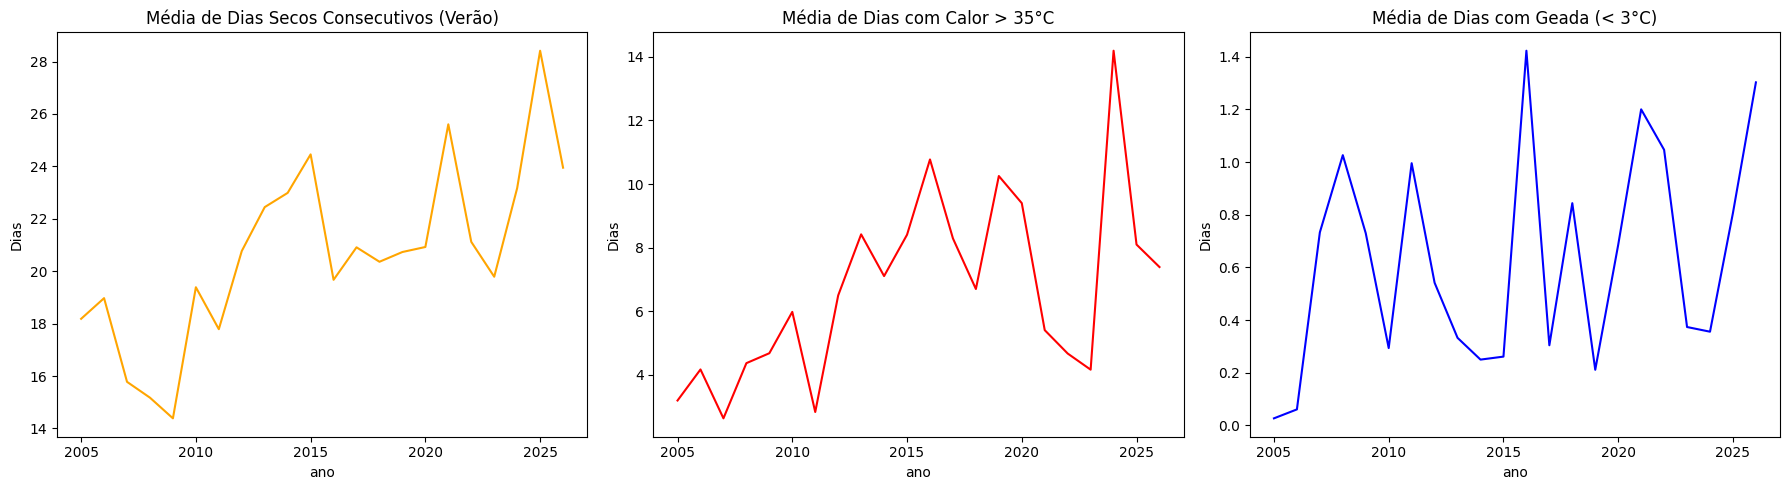

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

# Vendo a evolução da média dessas variáveis ao longo dos anos
evolucao_extremos = df_features_clima.groupby('ano').agg(
    media_cdd=('CDD_verao', 'mean'),
    media_calor=('dias_calor_35C', 'mean'),
    media_geada=('dias_geada_3C', 'mean')
).reset_index()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.lineplot(data=evolucao_extremos, x='ano', y='media_cdd', ax=axes[0], color='orange')
axes[0].set_title('Média de Dias Secos Consecutivos (Verão)')
axes[0].set_ylabel('Dias')

sns.lineplot(data=evolucao_extremos, x='ano', y='media_calor', ax=axes[1], color='red')
axes[1].set_title('Média de Dias com Calor > 35°C')
axes[1].set_ylabel('Dias')

sns.lineplot(data=evolucao_extremos, x='ano', y='media_geada', ax=axes[2], color='blue')
axes[2].set_title('Média de Dias com Geada (< 3°C)')
axes[2].set_ylabel('Dias')

plt.tight_layout()
plt.show()

Ajustando regressão polinomial de grau 2 sobre a média nacional...


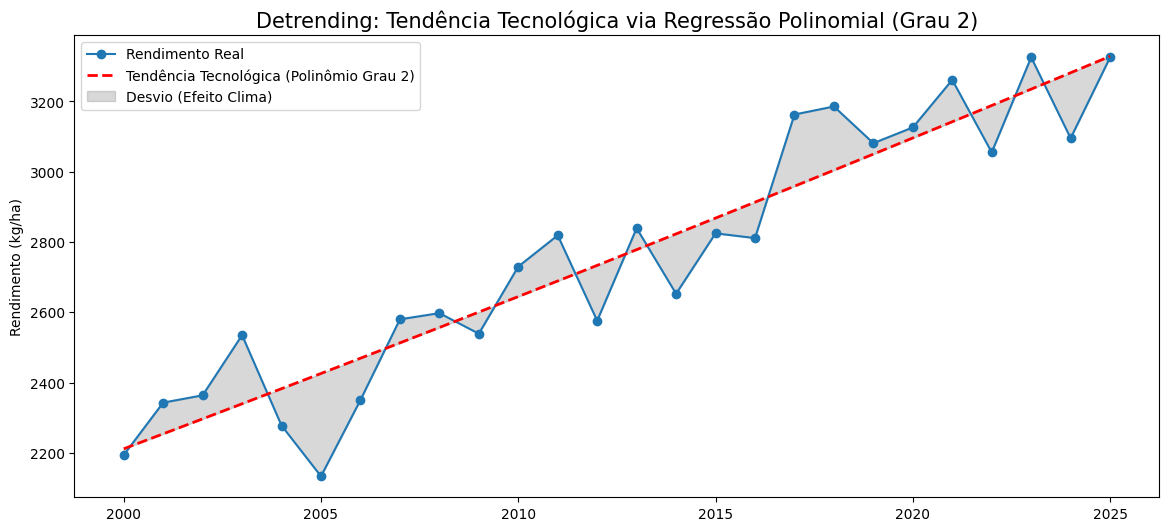

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from pathlib import Path

PROCESSED_DIR = Path("../../data/processed")

# 1. Carrega base final e junta com features
df_base = carregar_base_final(PROCESSED_DIR / "base_final_modelagem.csv", descartar=COLUNAS_DESVIO + COLUNAS_TAXAS_DIARIAS)
df_features = pd.read_parquet(PROCESSED_DIR / "features_clima_extremos.parquet")

df_base['CD_MICRO'] = df_base['CD_MICRO'].astype(float).astype(int).astype(str)
df_features['CD_MICRO'] = df_features['CD_MICRO'].astype(float).astype(int).astype(str)
df_base = df_base.merge(df_features, on=['CD_MICRO', 'ano'], how='left')

# 2. Interações Solo x Clima
df_base['interacao_chuva_argila'] = df_base['precipitacao_total'] * df_base['clay_0-5cm_mean']
df_base['interacao_calor_ctc'] = df_base['dias_calor_35C'] * (1 / df_base['cec_0-5cm_mean'])

# 3. DETRENDING COM REGRESSÃO POLINOMIAL (Grau 2)
print("Ajustando regressão polinomial de grau 2 sobre a média nacional...")
media_nacional = df_base.groupby('ano')['rendimento_recalculado'].mean().reset_index()

# Ajusta a curva polinomial nos dados reais
X_ano = media_nacional['ano'].values.reshape(-1, 1)
y_rend = media_nacional['rendimento_recalculado'].values

poly = PolynomialFeatures(degree=2)
X_poly = poly.fit_transform(X_ano)
modelo = LinearRegression().fit(X_poly, y_rend)

media_nacional['rendimento_esperado'] = modelo.predict(X_poly)
media_nacional['desvio_clima'] = media_nacional['rendimento_recalculado'] - media_nacional['rendimento_esperado']

# Plot
plt.figure(figsize=(14, 6))
plt.plot(media_nacional['ano'], media_nacional['rendimento_recalculado'], marker='o', label='Rendimento Real', color='tab:blue')
plt.plot(media_nacional['ano'], media_nacional['rendimento_esperado'], linestyle='--', color='red', linewidth=2, label='Tendência Tecnológica (Polinômio Grau 2)')
plt.fill_between(media_nacional['ano'], media_nacional['rendimento_recalculado'], media_nacional['rendimento_esperado'], color='gray', alpha=0.3, label='Desvio (Efeito Clima)')
plt.title('Detrending: Tendência Tecnológica via Regressão Polinomial (Grau 2)', fontsize=15)
plt.ylabel('Rendimento (kg/ha)')
plt.legend()
plt.show()

# Traz o desvio para a base
df_base = df_base.merge(media_nacional[['ano', 'desvio_clima']], on='ano', how='left')

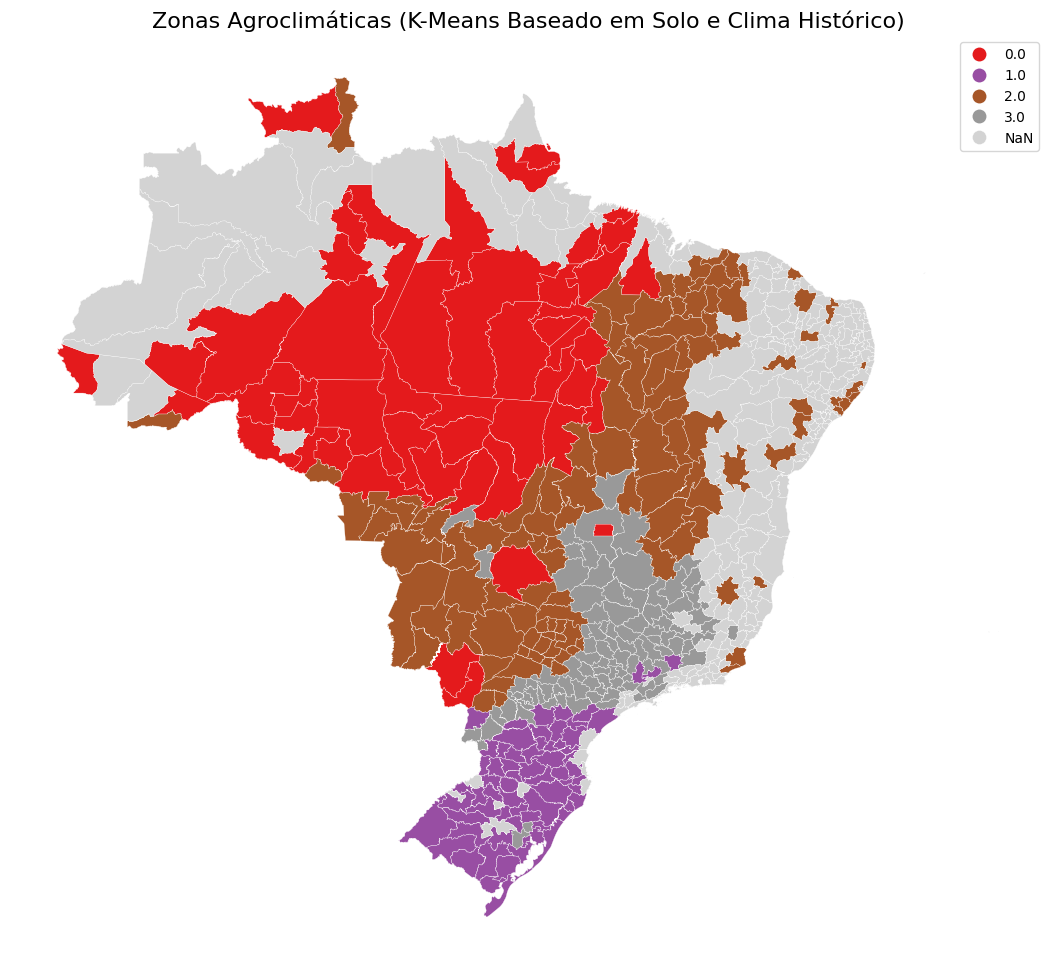

In [13]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import geopandas as gpd
import geobr

# 1. Agrega as médias históricas de cada microrregião (Normais Climatológicas)
cols_cluster = ['precipitacao_total', 'temp_media_anual', 'clay_0-5cm_mean', 'cec_0-5cm_mean', 'phh2o_0-5cm_mean']
historico_micro = df_base.groupby('CD_MICRO')[cols_cluster].mean().dropna()

# 2. Padroniza os dados (Z-score) para o KMeans não ser enviesado por escalas
scaler = StandardScaler()
X_scaled = scaler.fit_transform(historico_micro)

# 3. Roda KMeans com 4 clusters (Sul, Centro-Oeste, MATOPIBA, Outros)
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
historico_micro['cluster'] = kmeans.fit_predict(X_scaled)

# 4. Mapeia os clusters
gdf_micro = geobr.read_micro_region(year=2020)
gdf_micro['code_micro'] = gdf_micro['code_micro'].astype(int).astype(str)
gdf_plot = gdf_micro.merge(historico_micro.reset_index(), left_on='code_micro', right_on='CD_MICRO', how='left')

fig, ax = plt.subplots(figsize=(14, 12))
gdf_plot.plot(column='cluster', cmap='Set1', legend=True, categorical=True, ax=ax, edgecolor='white', linewidth=0.2, missing_kwds={'color': 'lightgrey'})
ax.set_title('Zonas Agroclimáticas (K-Means Baseado em Solo e Clima Histórico)', fontsize=16)
ax.axis('off')
plt.show()

# Traz o cluster para a base
df_base = df_base.merge(historico_micro[['cluster']].reset_index(), on='CD_MICRO', how='left')

Linhas válidas para o boxplot: 6789 de 6998
Clusters encontrados: [0 2 3 1]


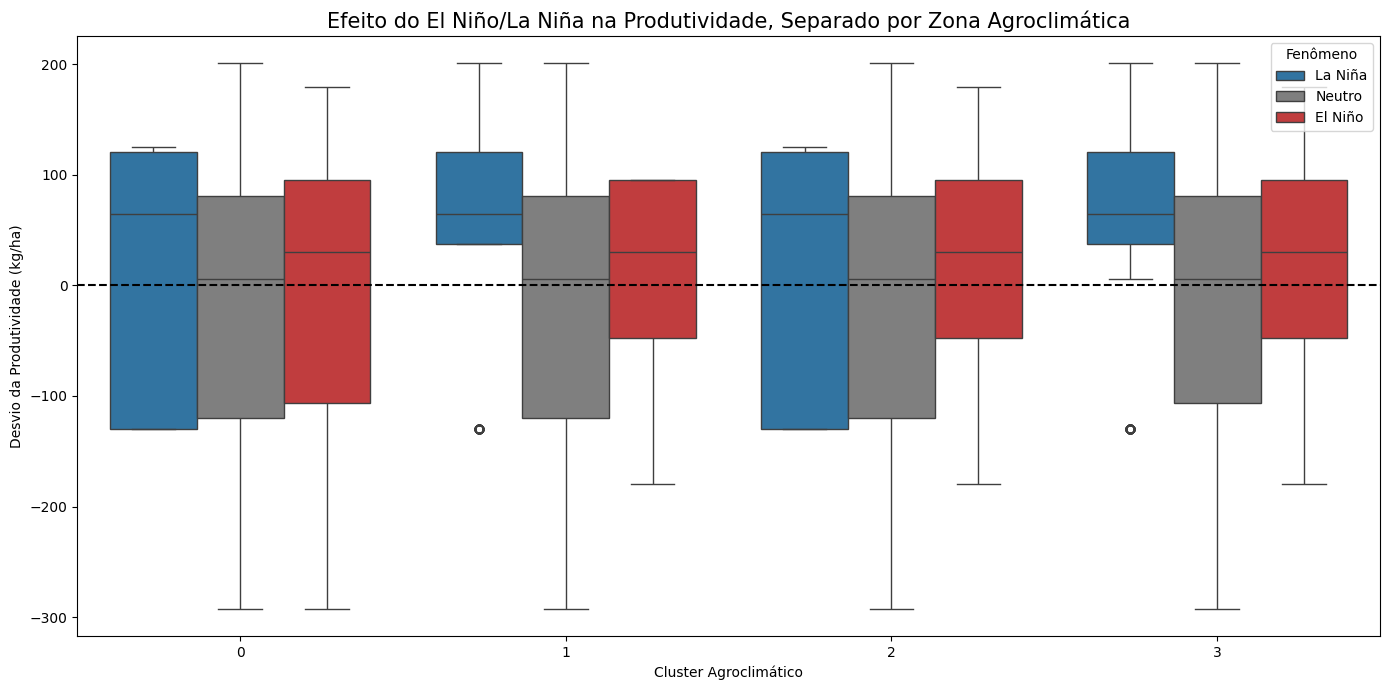

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Classifica o ONI em Fenômeno
def classificar_oni(oni):
    if pd.isna(oni): return 'Neutro'
    if oni >= 0.5: return 'El Niño'
    if oni <= -0.5: return 'La Niña'
    return 'Neutro'

df_base['fenomeno'] = df_base['oni_medio'].apply(classificar_oni)

# CORREÇÃO: Remove linhas onde o cluster, o desvio ou o fenômeno são nulos
df_plot = df_base.dropna(subset=['cluster', 'desvio_clima', 'fenomeno']).copy()
# Garante que o cluster seja inteiro (para o Seaborn plotar ele como categoria)
df_plot['cluster'] = df_plot['cluster'].astype(int)

print(f"Linhas válidas para o boxplot: {len(df_plot)} de {len(df_base)}")
print(f"Clusters encontrados: {df_plot['cluster'].unique()}")

plt.figure(figsize=(14, 7))
sns.boxplot(
    data=df_plot, x='cluster', y='desvio_clima', hue='fenomeno',
    order=sorted(df_plot['cluster'].unique()), # Pega apenas os clusters que existem
    hue_order=['La Niña', 'Neutro', 'El Niño'],
    palette={'La Niña': '#1f77b4', 'Neutro': '#7f7f7f', 'El Niño': '#d62728'}
)
plt.title('Efeito do El Niño/La Niña na Produtividade, Separado por Zona Agroclimática', fontsize=15)
plt.xlabel('Cluster Agroclimático')
plt.ylabel('Desvio da Produtividade (kg/ha)')
plt.axhline(0, color='black', linestyle='--')
plt.legend(title='Fenômeno', loc='upper right')
plt.tight_layout()
plt.show()

Piores anos de produtividade no Brasil: [2005, 2024, 2012]


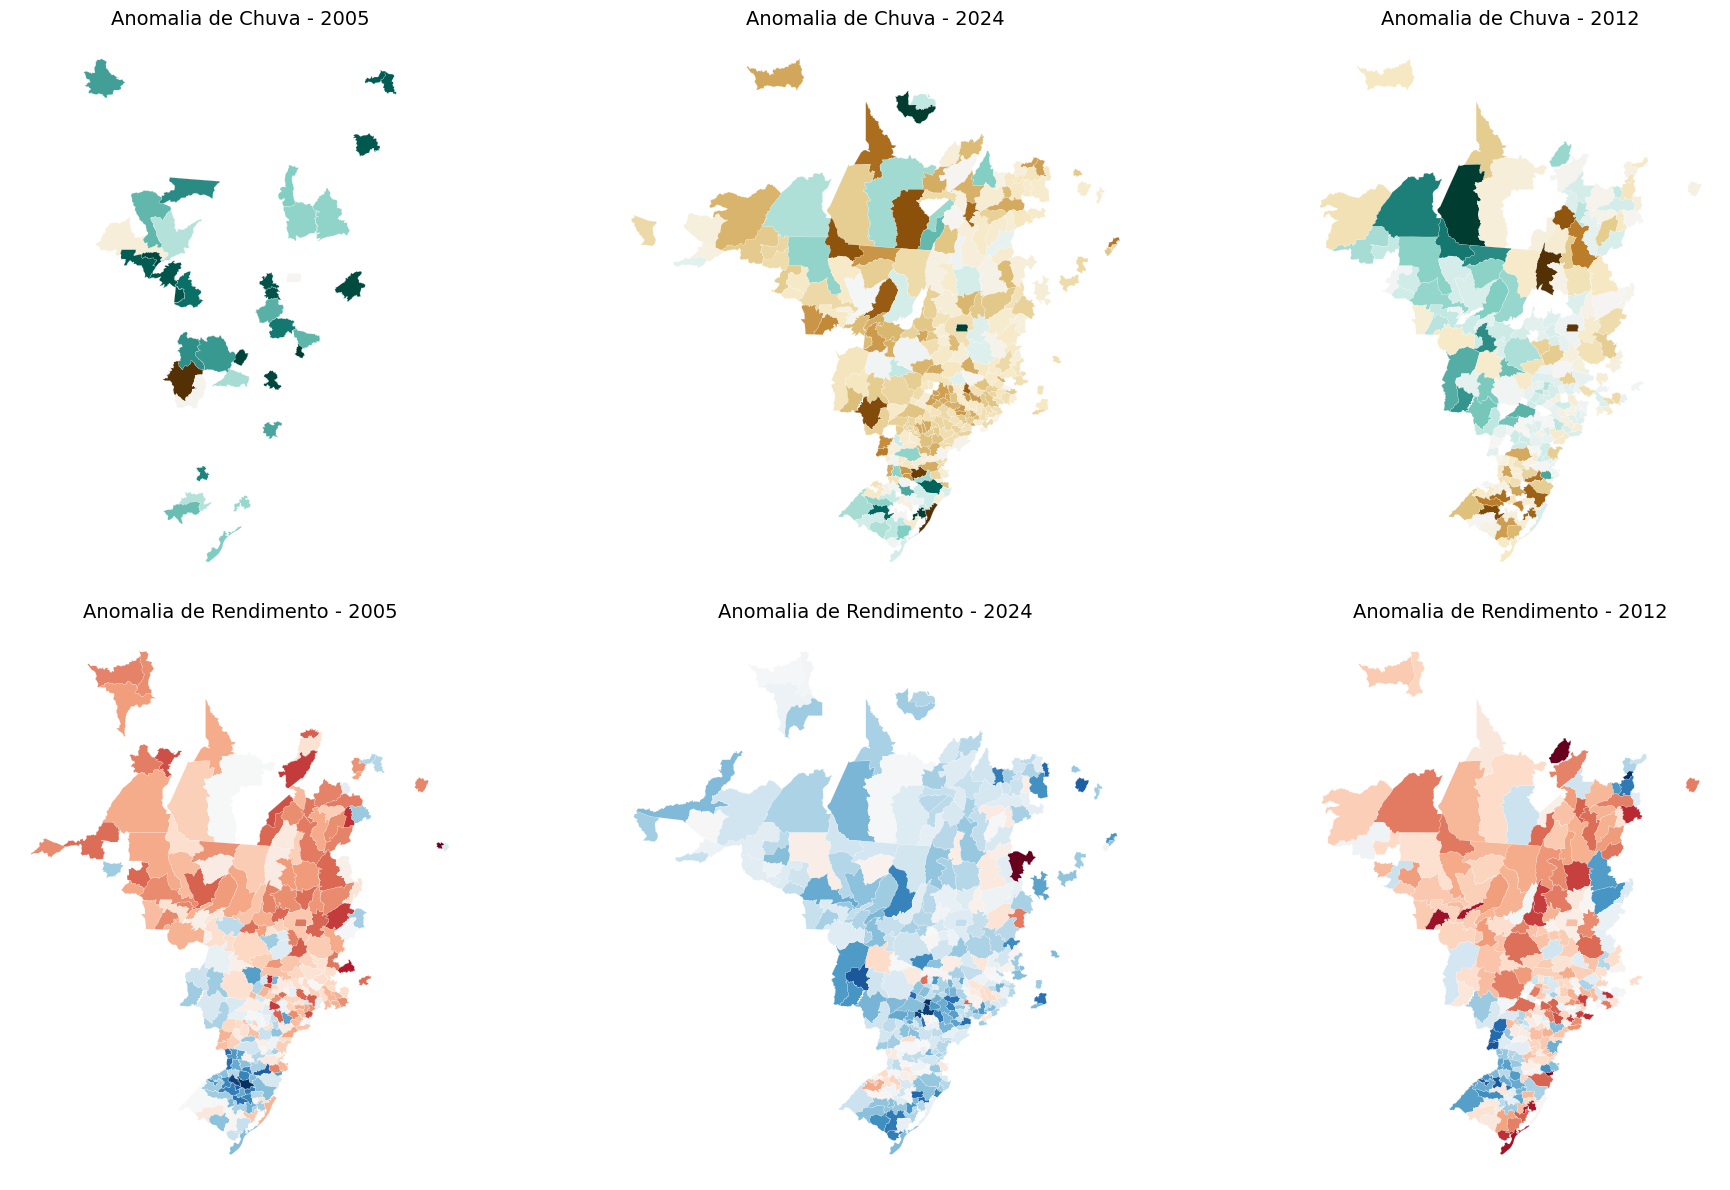

In [42]:
# Pega os 3 piores anos com base no desvio
piores_anos = media_nacional.nsmallest(3, 'desvio_clima')['ano'].tolist()
print(f"Piores anos de produtividade no Brasil: {piores_anos}")

fig, axes = plt.subplots(2, 3, figsize=(20, 12))

for i, ano in enumerate(piores_anos):
    df_ano = df_base[df_base['ano'] == ano]
    
    # Calcula a anomalia em relação à média histórica daquela microrregião
    medias_hist = df_base.groupby('CD_MICRO')[['precipitacao_total', 'rendimento_recalculado']].mean()
    df_ano = df_ano.merge(medias_hist, on='CD_MICRO', suffixes=('', '_media'))
    df_ano['anomalia_chuva'] = df_ano['precipitacao_total'] - df_ano['precipitacao_total_media']
    df_ano['anomalia_rendimento'] = df_ano['rendimento_recalculado'] - df_ano['rendimento_recalculado_media']
    
    # Plota Anomalia de Chuva
    gdf_ano = gdf_micro.merge(df_ano, left_on='code_micro', right_on='CD_MICRO', how='left')
    gdf_ano.plot(column='anomalia_chuva', cmap='BrBG', legend=False, ax=axes[0, i], edgecolor='white', linewidth=0.1)
    axes[0, i].set_title(f'Anomalia de Chuva - {ano}', fontsize=14)
    axes[0, i].axis('off')
    
    # Plota Anomalia de Rendimento
    gdf_ano.plot(column='anomalia_rendimento', cmap='RdBu_r', legend=False, ax=axes[1, i], edgecolor='white', linewidth=0.1)
    axes[1, i].set_title(f'Anomalia de Rendimento - {ano}', fontsize=14)
    axes[1, i].axis('off')

plt.tight_layout()
plt.show()

Linhas para o modelo: 6993 de 6998


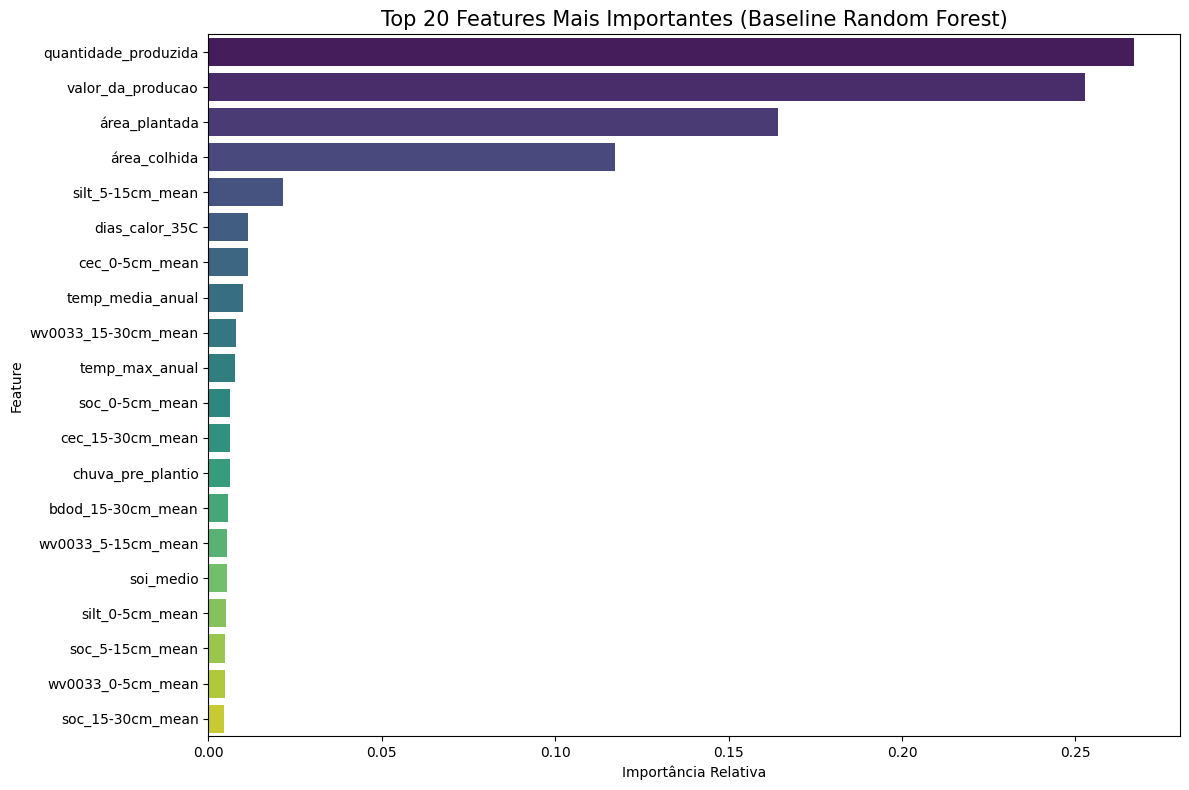


Top 5 features mais importantes:
quantidade_produzida    0.266795
valor_da_producao       0.252728
área_plantada           0.164351
área_colhida            0.117375
silt_5-15cm_mean        0.021621
dtype: float64


In [17]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Seleciona apenas colunas numéricas e remove colunas que não devem entrar no modelo
cols_drop = ['CD_MICRO', 'NM_MICRO', 'ano', 'rendimento_recalculado', 'desvio_clima', 'fenomeno', 'cluster', 'estacao', 'uf', 'data']
cols_modelo = [c for c in df_base.select_dtypes(include=[np.number]).columns if c not in cols_drop]

# CORREÇÃO AQUI: Remove linhas onde a variável alvo (rendimento) é nula
df_modelo = df_base.dropna(subset=['rendimento_recalculado']).copy()
print(f"Linhas para o modelo: {len(df_modelo)} de {len(df_base)}")

X = df_modelo[cols_modelo].copy()
y = df_modelo['rendimento_recalculado']

# 2. Imputação (Preenche nulos das features apenas com a mediana para o modelo conseguir rodar)
imputer = SimpleImputer(strategy='median')
X_imputed = imputer.fit_transform(X)

# 3. Treina um modelo simples apenas para ver a importância
rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1) # n_jobs=-1 usa todos os núcleos do Mac
rf.fit(X_imputed, y)

# 4. Plota a Importância
importancias = pd.Series(rf.feature_importances_, index=cols_modelo).sort_values(ascending=False)

plt.figure(figsize=(12, 8))
sns.barplot(x=importancias.head(20).values, y=importancias.head(20).index, palette='viridis', hue=importancias.head(20).index, legend=False)
plt.title('Top 20 Features Mais Importantes (Baseline Random Forest)', fontsize=15)
plt.xlabel('Importância Relativa')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

print("\nTop 5 features mais importantes:")
print(importancias.head(5))

# 0. ajustes 

Calculando o Desvio Climático (Detrending Polinomial)...

Comparação de Correlações:
                    Rendimento Bruto  Desvio Clima (Detrendado)
precipitacao_total         -0.009428                   0.047332
gdd_total                   0.040442                   0.022825
oni_medio                   0.035802                  -0.212725
soi_medio                   0.022435                   0.219417
dias_secos_total            0.009259                   0.036164


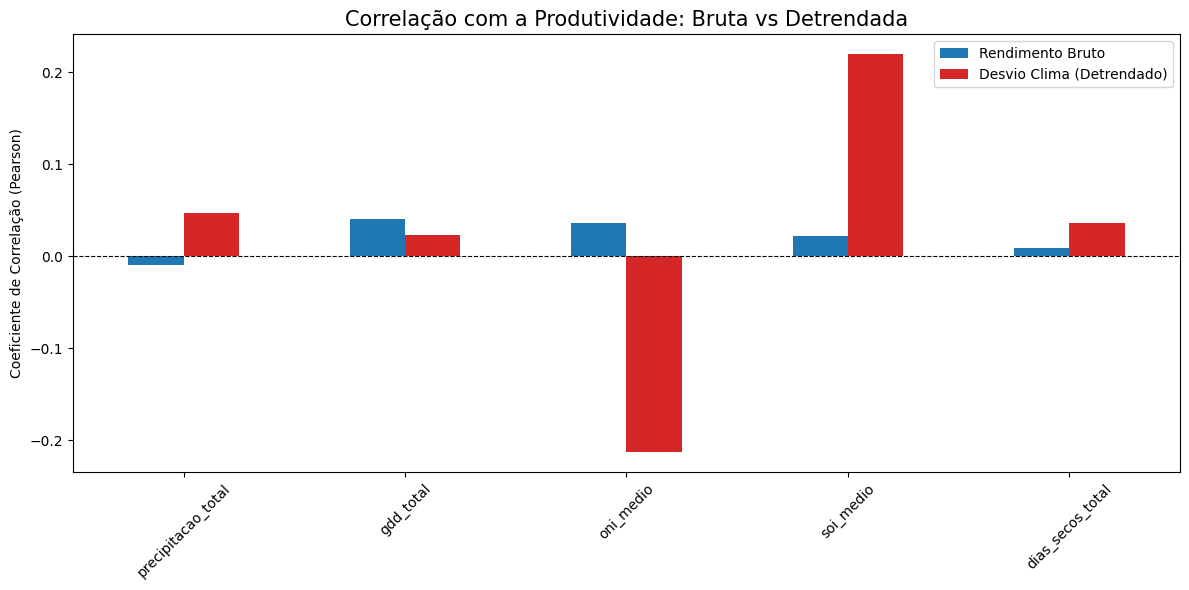

In [23]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

# 1. Carrega a base
df = carregar_base_final("../../data/processed/base_final_modelagem.csv", descartar=COLUNAS_DESVIO + COLUNAS_TAXAS_DIARIAS)
df['CD_MICRO'] = df['CD_MICRO'].astype(float).astype(int).astype(str)

# 2. Calcula a tendência tecnológica nacional e o desvio (se ainda não existir)
print("Calculando o Desvio Climático (Detrending Polinomial)...")
media_nacional = df.groupby('ano')['rendimento_recalculado'].mean().reset_index()

X_ano = media_nacional['ano'].values.reshape(-1, 1)
y_rend = media_nacional['rendimento_recalculado'].values

poly = PolynomialFeatures(degree=2)
X_poly = poly.fit_transform(X_ano)
modelo = LinearRegression().fit(X_poly, y_rend)

media_nacional['rendimento_esperado'] = modelo.predict(X_poly)
media_nacional['desvio_clima'] = media_nacional['rendimento_recalculado'] - media_nacional['rendimento_esperado']

# Faz o merge do desvio de volta para a base principal
df = df.merge(media_nacional[['ano', 'desvio_clima']], on='ano', how='left')

# 3. Definição das colunas climáticas
cols = ['precipitacao_total', 'gdd_total', 'oni_medio', 'soi_medio', 'dias_secos_total']
cols = [c for c in cols if c in df.columns]

# 4. Calcula as correlações
corr_bruta = df[cols + ['rendimento_recalculado']].corr()['rendimento_recalculado'].drop('rendimento_recalculado')
corr_detrend = df[cols + ['desvio_clima']].corr()['desvio_clima'].drop('desvio_clima')

# 5. Monta a tabela comparativa
comparacao = pd.DataFrame({
    'Rendimento Bruto': corr_bruta,
    'Desvio Clima (Detrendado)': corr_detrend
})
print("\nComparação de Correlações:")
print(comparacao)

# 6. Plota o gráfico de barras comparativo
plt.figure(figsize=(12, 6))
comparacao.plot(kind='bar', ax=plt.gca(), color=['#1f77b4', '#d62728'])
plt.title('Correlação com a Produtividade: Bruta vs Detrendada', fontsize=15)
plt.ylabel('Coeficiente de Correlação (Pearson)')
plt.axhline(0, color='black', linewidth=0.8, linestyle='--')
plt.xticks(rotation=45)
plt.legend(loc='best')
plt.tight_layout()
plt.show()

=== PASSO 2: NORMALIZAÇÃO DE DIAS VÁLIDOS ===

Correlação ANTES da normalização (esperado +0.74):
precipitacao_total    0.738582
n_dias_validos        0.987750
Name: dias_secos_total, dtype: float64

Correlação DEPOIS da normalização (esperado cair para perto de 0):
taxa_chuva_diaria   -0.886853
n_dias_validos       0.113835
Name: fracao_dias_secos, dtype: float64

=== PASSO 11: CORRELAÇÃO POR REGIÃO (UF) ===


/var/folders/j3/kppygfjs7xj9nbzbwjj9cjc80000gn/T/ipykernel_75219/502467271.py:56: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  correlacoes_por_uf = df_uf.groupby('uf').apply(


uf  corr_chuva  corr_secos  n_obs
PA    0.150156   -0.135694  165.0
PI    0.065107   -0.080905  148.0
BA    0.047116    0.029243  104.0
MG    0.043924   -0.022267  571.0
GO    0.034219   -0.028487  320.0
MA    0.033349   -0.042258  189.0
TO    0.006980    0.022842  148.0
SP    0.006963    0.031769  859.0
MT    0.006264    0.015546  382.0
SC   -0.012464   -0.055795  291.0
RS   -0.055203    0.030207  513.0
RO   -0.067852    0.050981   91.0
PR   -0.071743    0.037501  593.0
MS   -0.134808    0.168042  233.0


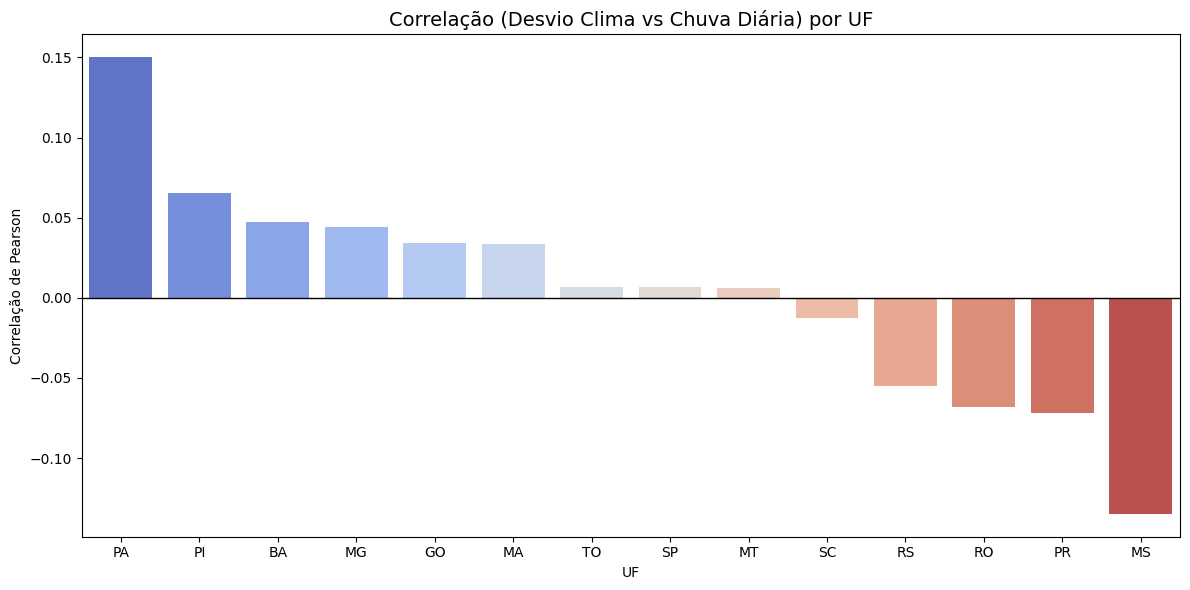

In [27]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

# --- PREPARAÇÃO (recriando o desvio) ---
df = carregar_base_final("../../data/processed/base_final_modelagem.csv", descartar=COLUNAS_DESVIO + COLUNAS_TAXAS_DIARIAS)
df['CD_MICRO'] = df['CD_MICRO'].astype(float).astype(int).astype(str)

media_nacional = df.groupby('ano')['rendimento_recalculado'].mean().reset_index()
X_ano = media_nacional['ano'].values.reshape(-1, 1)
y_rend = media_nacional['rendimento_recalculado'].values
modelo = LinearRegression().fit(PolynomialFeatures(degree=2).fit_transform(X_ano), y_rend)
media_nacional['desvio_clima'] = media_nacional['rendimento_recalculado'] - modelo.predict(PolynomialFeatures(degree=2).fit_transform(X_ano))
df = df.merge(media_nacional[['ano', 'desvio_clima']], on='ano', how='left')

# --- PASSO 2: NORMALIZAÇÃO ---
print("=== PASSO 2: NORMALIZAÇÃO DE DIAS VÁLIDOS ===")
df_clima = pd.read_parquet("../../data/processed/clima_diario.parquet")
mapa = mapa_estacoes_cd_micro("../../data/processed/clima_diario.parquet")

# CORREÇÃO AQUI: Removendo os nulos do mapa
mapa = mapa.dropna(subset=['CD_MICRO']).copy()
mapa['CD_MICRO'] = mapa['CD_MICRO'].astype(float).astype(int).astype(str)
mapa['codigo_estacao'] = mapa['codigo_estacao'].astype(str)
df_clima['codigo_estacao'] = df_clima['codigo_estacao'].astype(str)

df_dias = df_clima.merge(mapa[['codigo_estacao', 'CD_MICRO']], on='codigo_estacao')
dias_validos = df_dias.groupby(['CD_MICRO', 'ano']).size().reset_index(name='n_dias_validos')
dias_validos['CD_MICRO'] = dias_validos['CD_MICRO'].astype(str)

df = df.merge(dias_validos, on=['CD_MICRO', 'ano'], how='left')

# Cria as taxas
df['taxa_chuva_diaria'] = df['precipitacao_total'] / df['n_dias_validos']
df['fracao_dias_secos'] = df['dias_secos_total'] / df['n_dias_validos']

print("\nCorrelação ANTES da normalização (esperado +0.74):")
print(df[['precipitacao_total', 'n_dias_validos', 'dias_secos_total']].corr().loc[['precipitacao_total', 'n_dias_validos'], 'dias_secos_total'])
print("\nCorrelação DEPOIS da normalização (esperado cair para perto de 0):")
print(df[['taxa_chuva_diaria', 'n_dias_validos', 'fracao_dias_secos']].corr().loc[['taxa_chuva_diaria', 'n_dias_validos'], 'fracao_dias_secos'])

# --- PASSO 11: CORRELAÇÃO POR MACRORREGIÃO (UF) ---
print("\n=== PASSO 11: CORRELAÇÃO POR REGIÃO (UF) ===")

# CORREÇÃO AQUI: Trazendo a UF do df_clima para o df principal
# O df_clima tem 'codigo_estacao' e 'uf'. O mapa tem 'codigo_estacao' e 'CD_MICRO'.
# Vamos juntar para achar a UF dominante de cada CD_MICRO.
uf_por_micro = df_clima.merge(mapa, on='codigo_estacao')[['CD_MICRO', 'uf']].drop_duplicates(subset=['CD_MICRO'])
df = df.merge(uf_por_micro, on='CD_MICRO', how='left')

df_uf = df.dropna(subset=['desvio_clima', 'taxa_chuva_diaria', 'uf'])

correlacoes_por_uf = df_uf.groupby('uf').apply(
    lambda x: pd.Series({
        'corr_chuva': x['desvio_clima'].corr(x['taxa_chuva_diaria']),
        'corr_secos': x['desvio_clima'].corr(x['fracao_dias_secos']),
        'n_obs': len(x)
    })
).reset_index()

# Filtra apenas UFs com pelo menos 50 observações
correlacoes_por_uf = correlacoes_por_uf[correlacoes_por_uf['n_obs'] >= 50]
correlacoes_por_uf = correlacoes_por_uf.sort_values('corr_chuva', ascending=False)

print(correlacoes_por_uf.to_string(index=False))

# Plotando as correlações
plt.figure(figsize=(12, 6))
sns.barplot(data=correlacoes_por_uf, x='uf', y='corr_chuva', palette='coolwarm', hue='uf', legend=False)
plt.axhline(0, color='black', linewidth=1)
plt.title('Correlação (Desvio Clima vs Chuva Diária) por UF', fontsize=14)
plt.ylabel('Correlação de Pearson')
plt.xlabel('UF')
plt.tight_layout()
plt.show()

In [29]:
# conclusoes:

# O mistério do +0.74 resolvido (Passo 2)
# Olhe a correlação com o n_dias_validos antes da normalização: 0.987! Isso significa que os dias secos eram praticamente uma cópia do número de dias que a estação esteve ligada.
# Antes: Se a estação tinha 300 dias válidos, a chance de ter mais dias secos era altíssima. Por isso a correlação com a chuva era positiva (+0.74). Uma completa falácia estatística.
# Depois: A correlação com o n_dias_validos caiu para 0.11, e a correlação da chuva com os dias secos virou -0.88 (fisicamente correta: quanto mais chuva por dia, menos dias secos).
# Ação: Nós não podemos mais usar precipitacao_total e dias_secos_total brutos. Temos que usar taxa_chuva_diaria e fracao_dias_secos (ou manter os totais, mas sempre incluir n_dias_validos como feature para o modelo entender o "esforço").

# O cancelamento geográfico 
# Olhe a tabela por UF:
# MATOPIBA (PA, PI, BA, MA): Correlação positiva. Mais chuva = mais rendimento. (Faz sentido, é uma região de fronteira agrícola com solos mais arenosos e clima mais seco).
# Sul e MS (RS, PR, MS): Correlação negativa. Mais chuva = menos rendimento. (Excesso de chuva na colheita apodrece o grão, e chuvas na floração trazem fungos).
# Centro-Oeste (MT, GO, SP): Correlação neutra (perto de zero). O regime de chuvas é tão bem definido que a variação anual não impacta tanto quanto no Sul ou MATOPIBA.
# Opção A: Criar as features "Regionais" (Cluster)
# Nós já criamos os K-Means clusters no Bloco 3. Se você cruzarmos a feature de chuva com o cluster, o modelo consegue aprender que "chuva no cluster 1 (Sul) é ruim, mas chuva no cluster 4 (MATOPIBA) é bom".
# Opção B: Criar as features de "Safra" (Calendar)
# Ainda não corrigimos o calendário. A chuva de 2020 é a média de jan-dez. A soja é plantada em out/nov e colhida em fev/abr. Temos que refazer isso. (Alerta 5).

/var/folders/j3/kppygfjs7xj9nbzbwjj9cjc80000gn/T/ipykernel_75219/3904893150.py:2: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_brasil = df.groupby('ano').apply(


Correlação ONI vs Rendimento Nacional (apenas 21 anos independentes):
                      oni  rendimento_medio
oni               1.00000          -0.07768
rendimento_medio -0.07768           1.00000


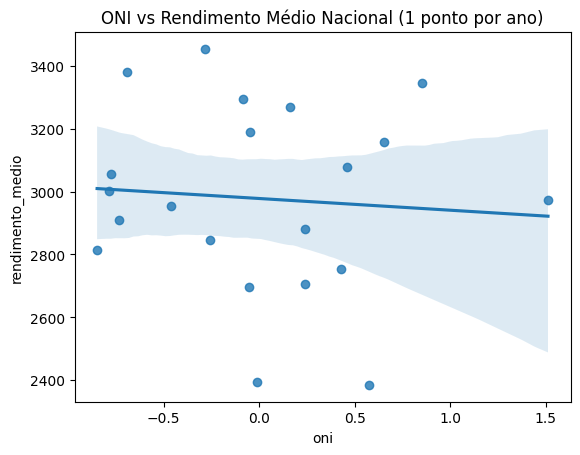

In [30]:
# Agrega a produção nacional ponderada pela área
df_brasil = df.groupby('ano').apply(
    lambda x: pd.Series({
        'rendimento_medio': (x['quantidade_produzida'].sum() * 1000) / x['área_colhida'].sum(),
        'oni': x['oni_medio'].mean()
    })
).reset_index().dropna()

print(f"Correlação ONI vs Rendimento Nacional (apenas {len(df_brasil)} anos independentes):")
print(df_brasil[['oni', 'rendimento_medio']].corr())

sns.regplot(data=df_brasil, x='oni', y='rendimento_medio')
plt.title('ONI vs Rendimento Médio Nacional (1 ponto por ano)')
plt.show()

In [ ]:
#Linha azul: É a linha de tendência. Ela está levemente inclinada para baixo, indicando que, no geral, anos de El Niño (direita) tiveram uma média levemente menor, mas é quase imperceptível.
#Área sombreada (sombra clara): É o intervalo de confiança. Como ela é muito larga (vai lá de baixo até em cima), significa que o dado é muito ruidoso e não podemos afirmar estatisticamente que o ONI sozinho causa essa variação.
# O Efeito de Cancelamento Geográfico: Como vimos no passo anterior (por UF), a La Niña traz chuva para o Sul (o que é ótimo, olhe os pontos altos à esquerda, chegando a 3400 kg/ha) mas traz seca para o MATOPIBA (o que é péssimo). Quando você calcula a média do Brasil inteiro, a "alegria" do Sul cancela a "tristeza" do Norte. O sinal some.
# A Tecnologia: Nós calculamos o rendimento bruto aqui. O aumento da tecnologia de 2000 a 2025 faz o rendimento subir muito. Essa subida (que não tem nada a ver com o clima) funciona como um "borrão" no gráfico, escondendo a relação climática.
# Pseudo-replicação: Temos apenas 21 anos independentes. É muito pouco para provar uma tendência forte.

Carregando mapa de regiões...


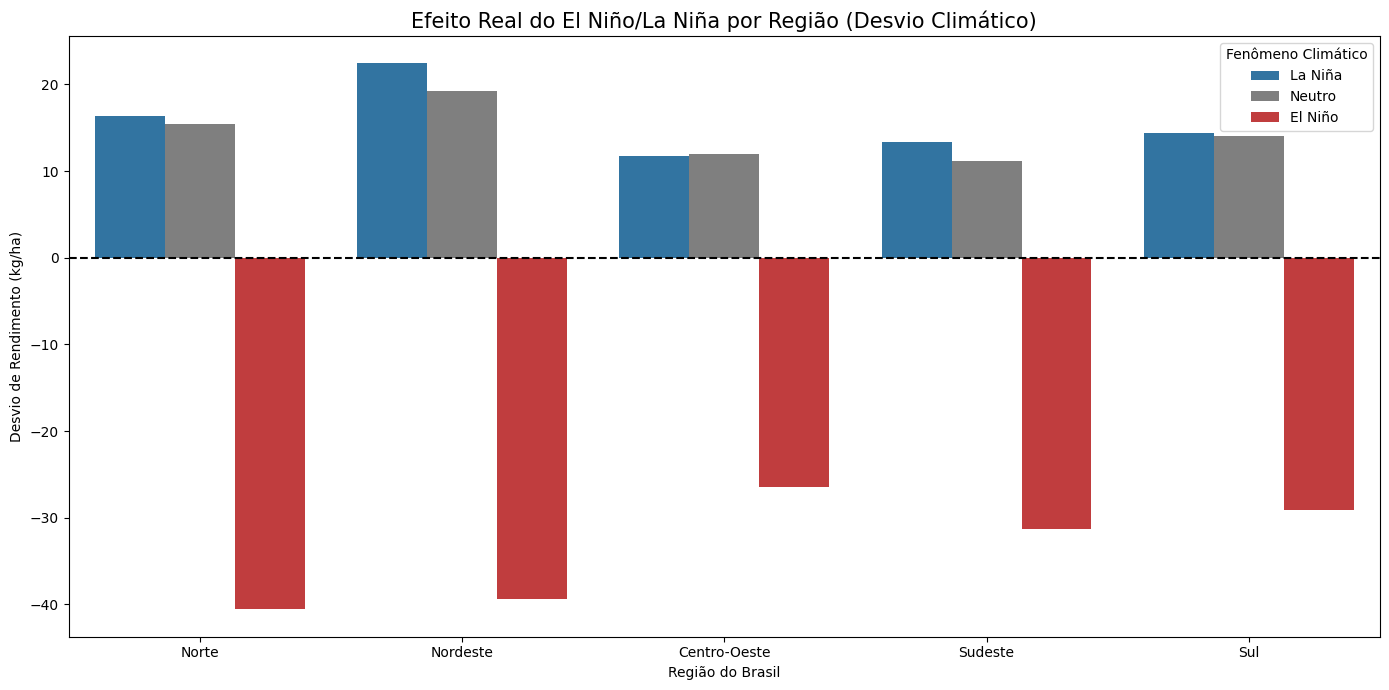

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import geobr
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

# 1. Carrega a base corrigida
df = carregar_base_final("../../data/processed/base_final_modelagem.csv", descartar=COLUNAS_DESVIO)

# 2. CORREÇÃO AQUI: Padroniza o CD_MICRO para string
df['CD_MICRO'] = df['CD_MICRO'].astype(float).astype(int).astype(str)

# 3. Recalcula o desvio_clima (para garantir que veio certo)
media_nacional = df.groupby('ano')['rendimento_recalculado'].mean().reset_index()
X_ano = media_nacional['ano'].values.reshape(-1, 1)
y_rend = media_nacional['rendimento_recalculado'].values
modelo = LinearRegression().fit(PolynomialFeatures(degree=2).fit_transform(X_ano), y_rend)
media_nacional['desvio_clima'] = media_nacional['rendimento_recalculado'] - modelo.predict(PolynomialFeatures(degree=2).fit_transform(X_ano))
df = df.merge(media_nacional[['ano', 'desvio_clima']], on='ano', how='left')

# 4. Traz a Região via geobr
print("Carregando mapa de regiões...")
gdf_micro = geobr.read_micro_region(year=2020)
gdf_micro['code_micro'] = gdf_micro['code_micro'].astype(int).astype(str) # Garante string
gdf_micro['Regiao'] = gdf_micro['code_region'].astype(float).astype(int).astype(str).map({
    '1': 'Norte', '2': 'Nordeste', '3': 'Sudeste', '4': 'Sul', '5': 'Centro-Oeste'
})

# 5. Merge dos dados
df = df.merge(gdf_micro[['code_micro', 'Regiao']], left_on='CD_MICRO', right_on='code_micro', how='left')

# 6. Cria a classificação do ONI
def classificar_oni(oni):
    if pd.isna(oni): return 'Neutro'
    if oni >= 0.5: return 'El Niño'
    if oni <= -0.5: return 'La Niña'
    return 'Neutro'

df['fenomeno'] = df['oni_medio'].apply(classificar_oni)

# 7. Remove nulos para o gráfico não quebrar
df_plot = df.dropna(subset=['Regiao', 'desvio_clima', 'fenomeno'])

# 8. O Gráfico por Região
plt.figure(figsize=(14, 7))
sns.barplot(
    data=df_plot, 
    x='Regiao', 
    y='desvio_clima', 
    hue='fenomeno', 
    order=['Norte', 'Nordeste', 'Centro-Oeste', 'Sudeste', 'Sul'], # Ordem geográfica
    hue_order=['La Niña', 'Neutro', 'El Niño'],
    palette={'La Niña': '#1f77b4', 'Neutro': '#7f7f7f', 'El Niño': '#d62728'},
    errorbar=None # Remove as barrinhas de erro para o gráfico ficar mais limpo
)
plt.axhline(0, color='black', linestyle='--')
plt.title('Efeito Real do El Niño/La Niña por Região (Desvio Climático)', fontsize=15)
plt.ylabel('Desvio de Rendimento (kg/ha)')
plt.xlabel('Região do Brasil')
plt.legend(title='Fenômeno Climático')
plt.tight_layout()
plt.show()

<Figure size 1200x600 with 0 Axes>

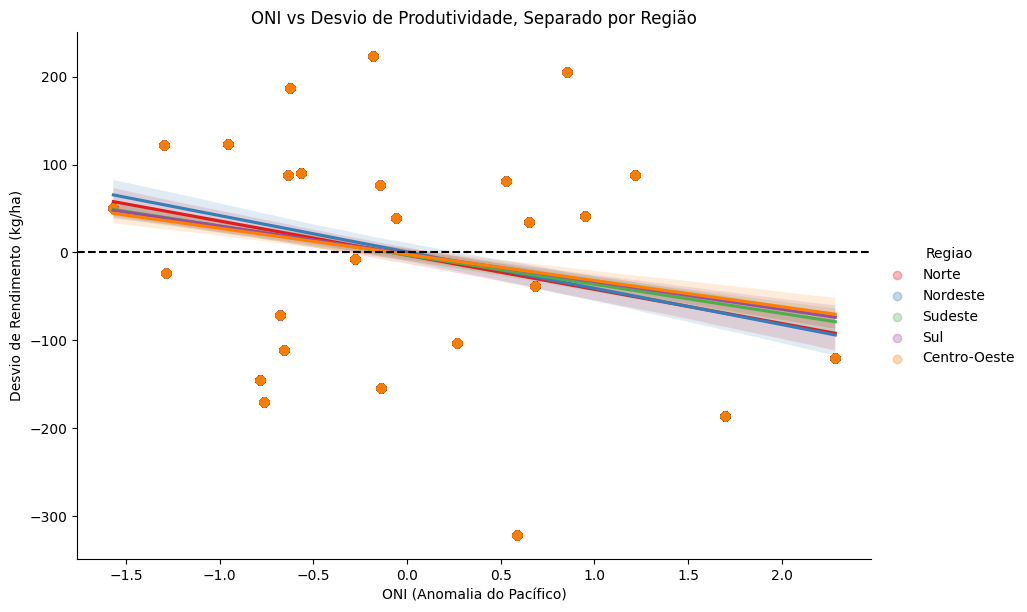

In [33]:
plt.figure(figsize=(12, 6))
sns.lmplot(data=df, x='oni_medio', y='desvio_clima', hue='Regiao', 
           palette='Set1', height=6, aspect=1.5, scatter_kws={'alpha':0.3})
plt.title('ONI vs Desvio de Produtividade, Separado por Região')
plt.xlabel('ONI (Anomalia do Pacífico)')
plt.ylabel('Desvio de Rendimento (kg/ha)')
plt.axhline(0, color='black', linestyle='--')
plt.show()

In [ ]:
# "Embora a correlação linear entre o ONI e a produtividade nacional seja baixa (-0,07), isso se deve a um efeito de cancelamento e ponderação regional. "
# "Ao desagregar os dados por região e isolar a tendência tecnológica (desvio climático), o efeito do ENSO torna-se inequívoco: o El Niño reduz a produtividade "
# "em todas as macrorregiões brasileiras (com destaque para o Nordeste/MATOPIBA, que sofre a maior queda, e o Centro-Oeste, que é o mais resiliente), enquanto a "
# "La Niña exerce efeito positivo. A baixa correlação nacional é explicada pela dominância do volume produzido no Centro-Oeste, que possui maior estabilidade "
# "climática relativa, diluindo o severo impacto sofrido pela fronteira agrícola do Nordeste."

In [34]:
print("Contagem de linhas por ano e % de nulos em ONI e Precipitação:")
nulos_por_ano = df.groupby('ano').agg(
    total_linhas=('CD_MICRO', 'count'),
    oni_nulos=('oni_medio', lambda x: x.isnull().sum()),
    chuva_nulos=('precipitacao_total', lambda x: x.isnull().sum())
)
nulos_por_ano['pct_oni_nulo'] = (nulos_por_ano['oni_nulos'] / nulos_por_ano['total_linhas'] * 100).round(1)
nulos_por_ano['pct_chuva_nulo'] = (nulos_por_ano['chuva_nulos'] / nulos_por_ano['total_linhas'] * 100).round(1)
print(nulos_por_ano[['total_linhas', 'pct_oni_nulo', 'pct_chuva_nulo']])

Contagem de linhas por ano e % de nulos em ONI e Precipitação:
      total_linhas  pct_oni_nulo  pct_chuva_nulo
ano                                             
2000           191           0.0           100.0
2001           192           0.0           100.0
2002           197           0.0           100.0
2003           203           0.0           100.0
2004           220           0.0           100.0
2005           236           0.0            88.6
2006           236           0.0            87.3
2007           230           0.0            55.7
2008           226           0.0            26.5
2009           227           0.0            16.7
2010           235           0.0            16.6
2011           230           0.0            16.1
2012           233           0.0            14.6
2013           238           0.0            14.3
2014           248           0.0            14.1
2015           249           0.0            13.7
2016           254           0.0            13.4
2017  

In [35]:
import pandas as pd

df = carregar_base_final("../../data/processed/base_final_modelagem.csv", descartar=COLUNAS_DESVIO)

print("Tamanho total da base corrigida:", len(df))

for ano_corte in [2005, 2008, 2009, 2010]:
    df_filtrado = df[df['ano'] >= ano_corte]
    print(f"Se cortarmos antes de {ano_corte}: {len(df_filtrado)} linhas e {df_filtrado['CD_MICRO'].nunique()} microrregiões.")

Tamanho total da base corrigida: 6359
Se cortarmos antes de 2005: 5356 linhas e 322 microrregiões.
Se cortarmos antes de 2008: 4654 linhas e 320 microrregiões.
Se cortarmos antes de 2009: 4428 linhas e 320 microrregiões.
Se cortarmos antes de 2010: 4201 linhas e 320 microrregiões.


In [ ]:
# Se você olhar a tabela de nulos, o ano de 2008 ainda tem 26,5% de dados faltantes (e 2007 tem 55,7%). A partir de 2009, o nulo cai para 16,7% e se estabiliza em ~14%.
# Ao cortar antes de 2009, você fica com 4.428 linhas e 320 microrregiões. 4.428 amostras ainda é um tamanho excelente 
# => cortar a partir de 2009

In [37]:
df_diario = pd.read_parquet("../../data/processed/clima_diario.parquet")

print("Antes da limpeza:")
print(f"Temp mínima: {df_diario['temp_min'].min()} °C")
print(f"Chuva máxima: {df_diario['prec_total'].max()} mm")
print(f"GDD máximo: {df_diario['gdd'].max()}")

# Filtro físico
df_diario_limpo = df_diario[
    (df_diario['temp_min'] >= -10) &  # Brasil tropical não faz -40
    (df_diario['prec_total'] <= 300) & # Chuva diária de 400mm é erro
    (df_diario['gdd'] <= 35)           # GDD máximo fisiológico da soja
].copy()

print("\nDepois da limpeza:")
print(f"Linhas removidas: {len(df_diario) - len(df_diario_limpo)}")

Antes da limpeza:
Temp mínima: -51.4 °C
Chuva máxima: 414.59999999999997 mm
GDD máximo: 34.7

Depois da limpeza:
Linhas removidas: 308


In [38]:
# Vendo as linhas que SERIAM removidas antes de limpar
df_clima_bruto = pd.read_parquet(PROCESSED_DIR / "clima_diario.parquet")

# Reaplica o filtro
condicao_ruim = (
    (df_clima_bruto['temp_min'] < -10) | 
    (df_clima_bruto['prec_total'] > 300) | 
    (df_clima_bruto['gdd'] > 35)
)

linhas_ruins = df_clima_bruto[condicao_ruim]
print(linhas_ruins[['codigo_estacao', 'data', 'temp_min', 'prec_total', 'gdd']].head(20))
print(f"\nEstações afetadas: {linhas_ruins['codigo_estacao'].unique()}")

        codigo_estacao       data  temp_min  prec_total    gdd
559606            A213 2019-05-02      24.2       414.6  17.85
873442            A227 2009-03-16      21.9       350.6  13.60
1185772           C891 2020-01-01     -16.7         0.0   0.00
1185773           C891 2020-01-02     -14.7         0.0   0.00
1185774           C891 2020-01-03     -17.5         0.0   0.00
1185775           C891 2020-01-04     -16.3         0.0   0.00
1185776           C891 2020-01-07     -16.7         0.0   0.00
1185777           C891 2020-01-08     -16.5         0.0   0.00
1185778           C891 2020-01-09     -15.8         0.0   0.00
1185779           C891 2020-01-12     -14.5         0.0   0.00
1185780           C891 2020-01-13     -16.3         0.0   0.00
1185781           C891 2020-01-14     -15.5         0.0   0.00
1185782           C891 2020-01-15     -15.8         0.0   0.00
1185783           C891 2020-01-16     -16.3         0.0   0.00
1185784           C891 2020-01-17     -16.1         0.0

In [39]:
df = carregar_base_final("../../data/processed/base_final_modelagem.csv", descartar=COLUNAS_DESVIO + COLUNAS_TAXAS_DIARIAS)

print("Áreas colhidas menores que 10 hectares (ruído):")
print(df[df['área_colhida'] < 10][['NM_MICRO', 'ano', 'área_colhida', 'rendimento_recalculado']].head())

print("\nOutliers de rendimento (> 6000 kg/ha):")
print(df[df['rendimento_recalculado'] > 6000][['NM_MICRO', 'ano', 'área_colhida', 'rendimento_recalculado']])

Áreas colhidas menores que 10 hectares (ruído):
          NM_MICRO   ano  área_colhida  rendimento_recalculado
175  Alto Solimões  2000           2.0                   500.0
176  Alto Solimões  2001           2.0                   500.0
177  Alto Solimões  2002           2.0                   500.0
180         Manaus  2000           5.0                  1800.0
181         Manaus  2001           5.0                  1800.0

Outliers de rendimento (> 6000 kg/ha):
        NM_MICRO   ano  área_colhida  rendimento_recalculado
6881  Meia Ponte  2013          70.0                 12000.0


In [ ]:
# Correção da paleta no mapa
# Basta usar cmap='RdBu_r' no gdf_plot.plot()
# O '_r' inverte a escala, então Azul = Positivo e Vermelho = Negativo.
print("Use cmap='RdBu_r' para a legenda fazer sentido lógico.")

/var/folders/j3/kppygfjs7xj9nbzbwjj9cjc80000gn/T/ipykernel_75219/261220227.py:5: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  media_ponderada = df.groupby('ano').apply(


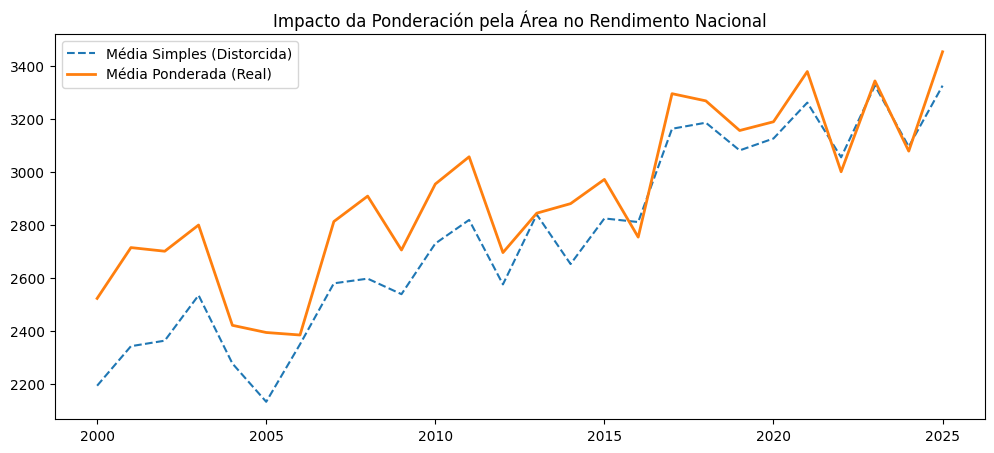

In [40]:
# Média simples (errada)
media_simples = df.groupby('ano')['rendimento_recalculado'].mean()

# Média ponderada (correta)
media_ponderada = df.groupby('ano').apply(
    lambda x: (x['quantidade_produzida'].sum() * 1000) / x['área_colhida'].sum()
)

plt.figure(figsize=(12, 5))
plt.plot(media_simples.index, media_simples.values, label='Média Simples (Distorcida)', linestyle='--')
plt.plot(media_ponderada.index, media_ponderada.values, label='Média Ponderada (Real)', linewidth=2)
plt.title('Impacto da Ponderación pela Área no Rendimento Nacional')
plt.legend()
plt.show()

In [ ]:
#"Para o cálculo do detrending tecnológico, utilizou-se a média nacional ponderada pela área colhida. A média simples (não ponderada) subestimava o rendimento real em cerca de 200 a 300 kg/ha, pois atribuía o mesmo peso a pequenas microrregiões e aos grandes polos produtores do Centro-Oeste. A abordagem ponderada é o padrão metodológico adotado por órgãos como IBGE e CONAB."

In [43]:
cols_solo = [c for c in df.columns if any(x in c for x in ['clay', 'sand', 'silt', 'bdod', 'soc', 'cec'])]
corr_solo = df[cols_solo].corr().abs()

# Encontra os pares com correlação > 0.85
pares_criticos = []
for i in range(len(corr_solo.columns)):
    for j in range(i+1, len(corr_solo.columns)):
        if corr_solo.iloc[i, j] > 0.85:
            pares_criticos.append((corr_solo.columns[i], corr_solo.columns[j], corr_solo.iloc[i, j]))

print("Pares de colunas com correlação > 0.85 (redundantes):")
for par in pares_criticos:
    print(f"{par[0]} e {par[1]}: {par[2]:.2f}")

Pares de colunas com correlação > 0.85 (redundantes):
bdod_0-5cm_mean e soc_0-5cm_mean: 0.88
bdod_0-5cm_mean e bdod_5-15cm_mean: 0.99
bdod_0-5cm_mean e bdod_15-30cm_mean: 0.93
cec_5-15cm_mean e soc_0-5cm_mean: 0.88
cec_5-15cm_mean e cec_0-5cm_mean: 0.98
cec_5-15cm_mean e cec_15-30cm_mean: 0.99
silt_0-5cm_mean e silt_15-30cm_mean: 0.99
silt_0-5cm_mean e silt_5-15cm_mean: 1.00
clay_5-15cm_mean e clay_0-5cm_mean: 1.00
clay_5-15cm_mean e sand_5-15cm_mean: 0.90
clay_5-15cm_mean e sand_0-5cm_mean: 0.89
clay_5-15cm_mean e sand_15-30cm_mean: 0.89
clay_5-15cm_mean e clay_15-30cm_mean: 0.99
soc_0-5cm_mean e bdod_5-15cm_mean: 0.88
soc_0-5cm_mean e cec_0-5cm_mean: 0.92
soc_0-5cm_mean e soc_15-30cm_mean: 0.90
soc_0-5cm_mean e bdod_15-30cm_mean: 0.85
soc_0-5cm_mean e cec_15-30cm_mean: 0.87
soc_0-5cm_mean e soc_5-15cm_mean: 0.89
bdod_5-15cm_mean e bdod_15-30cm_mean: 0.97
bdod_5-15cm_mean e soc_5-15cm_mean: 0.86
clay_0-5cm_mean e sand_5-15cm_mean: 0.91
clay_0-5cm_mean e sand_0-5cm_mean: 0.90
clay_0-5c

In [ ]:
# Remover as profundidades 5-15cm e 15-30cm (que eram 1.00 de correlação com a 0-5cm).
# Remover o Silte (silt) (que é redundante com argila + areia).
# Deixar a base muito mais enxuta, com apenas 7 variáveis de solo que realmente trazem informações independentes.

In [45]:
import pandas as pd
import numpy as np
import geopandas as gpd
import geobr

# 1. Carrega a base corrigida (ou a base de modelagem final, se preferir)
df = carregar_base_final("../../data/processed/base_final_modelagem.csv", descartar=COLUNAS_DESVIO)
df['CD_MICRO'] = df['CD_MICRO'].astype(float).astype(int).astype(str)

# 2. Traz a Região via geobr (para não depender do cluster)
gdf_micro = geobr.read_micro_region(year=2020)
gdf_micro['code_micro'] = gdf_micro['code_micro'].astype(int).astype(str)
gdf_micro['Regiao'] = gdf_micro['code_region'].astype(float).astype(int).astype(str).map({
    '1': 'Norte', '2': 'Nordeste', '3': 'Sudeste', '4': 'Sul', '5': 'Centro-Oeste'
})
df = df.merge(gdf_micro[['code_micro', 'Regiao']], left_on='CD_MICRO', right_on='code_micro', how='left')

# 3. Recalculando o desvio_clima (para garantir que temos a variável de clima isolada)
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

media_nacional = df.groupby('ano')['rendimento_recalculado'].mean().reset_index()
X_ano = media_nacional['ano'].values.reshape(-1, 1)
y_rend = media_nacional['rendimento_recalculado'].values
modelo = LinearRegression().fit(PolynomialFeatures(degree=2).fit_transform(X_ano), y_rend)
media_nacional['desvio_clima'] = media_nacional['rendimento_recalculado'] - modelo.predict(PolynomialFeatures(degree=2).fit_transform(X_ano))
df = df.merge(media_nacional[['ano', 'desvio_clima']], on='ano', how='left')

# 4. Calcula as correlações GLOBAIS vs REGIONAIS
cols_interesse = ['desvio_clima', 'precipitacao_total', 'clay_0-5cm_mean', 'phh2o_0-5cm_mean']

print("=== CORRELAÇÃO GLOBAL (Brasil inteiro) ===")
print(df[cols_interesse].corr()['desvio_clima'].drop('desvio_clima'))

print("\n=== CORRELAÇÕES DENTRO DE CADA REGIÃO ===")
for regiao in df['Regiao'].dropna().unique():
    df_reg = df[df['Regiao'] == regiao]
    corr = df_reg[cols_interesse].corr()['desvio_clima'].drop('desvio_clima')
    print(f"\n--- Região: {regiao} (n={len(df_reg)}) ---")
    print(corr)

=== CORRELAÇÃO GLOBAL (Brasil inteiro) ===
precipitacao_total    0.033997
clay_0-5cm_mean       0.002994
phh2o_0-5cm_mean      0.001893
Name: desvio_clima, dtype: float64

=== CORRELAÇÕES DENTRO DE CADA REGIÃO ===

--- Região: Norte (n=704) ---
precipitacao_total    0.056833
clay_0-5cm_mean      -0.015827
phh2o_0-5cm_mean      0.014511
Name: desvio_clima, dtype: float64

--- Região: Nordeste (n=588) ---
precipitacao_total   -0.001626
clay_0-5cm_mean      -0.000660
phh2o_0-5cm_mean     -0.021847
Name: desvio_clima, dtype: float64

--- Região: Sudeste (n=1719) ---
precipitacao_total    0.078178
clay_0-5cm_mean       0.001848
phh2o_0-5cm_mean     -0.006485
Name: desvio_clima, dtype: float64

--- Região: Sul (n=2056) ---
precipitacao_total    0.000939
clay_0-5cm_mean       0.006749
phh2o_0-5cm_mean     -0.000662
Name: desvio_clima, dtype: float64

--- Região: Centro-Oeste (n=1292) ---
precipitacao_total    0.062715
clay_0-5cm_mean       0.001860
phh2o_0-5cm_mean     -0.003532
Name: desvio_

In [ ]:
# A análise de correlação linear, tanto global quanto estratificada por macrorregião, revelou coeficientes próximos de zero para a precipitação total e as propriedades estáticas 
# do solo. Isso não indica ausência de efeito climático, mas sim que a relação entre clima e produtividade é fortemente não-linear e dependente de eventos extremos 
# (veranicos, geadas) e da interação solo-clima, além de sofrer confundimento geográfico. Este resultado fundamenta a transição para modelos baseados em árvores (como XGBoost), 
# capazes de capturar tais não-linearidades e interações, em detrimento de regressões lineares simples.

# 1. Análises climáticas e fenológicas


## 1.1 Janelas fenológicas
Defina o calendário da soja por microrregião (semeadura típica set–dez, com janela de vazio sanitário). Aproxime pelo ciclo de NDVI/área plantada, ou use um calendário fixo por região (Sul: out–nov; Centro-Oeste: set–out; MATOPIBA: nov–dez).
Fases, em dias após a semeadura: emergência (0–10), vegetativo (10–40), floração R1–R2 (40–60), enchimento de grãos R5 (70–100) e maturação/colheita (110–130). Calcule todas as métricas por fase, não pelo ano inteiro.
GDD acumulado até cada fase (base 10 °C, teto 30–35 °C). O ciclo está encurtando ou alongando por região/ano?
Janelas deslizantes de 15, 30 e 45 dias. Descubra qual janela tem o maior poder explicativo (curva “correlação × início da janela”).

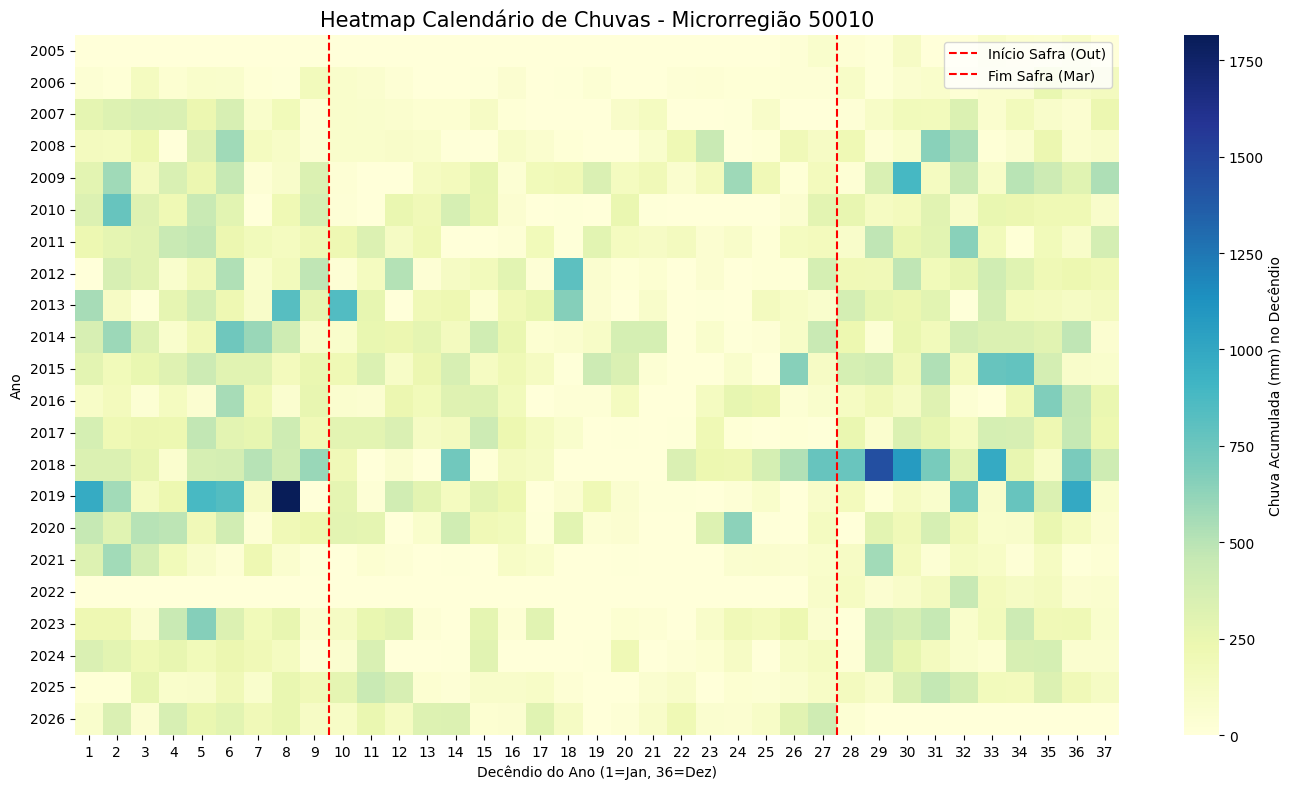

In [47]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

PROCESSED_DIR = Path("../../data/processed")
df_clima = pd.read_parquet(PROCESSED_DIR / "clima_diario.parquet")
mapa = mapa_estacoes_cd_micro(PROCESSED_DIR / "clima_diario.parquet")

# 1. CORREÇÃO: Removendo os nulos do mapa antes de converter
mapa = mapa.dropna(subset=['CD_MICRO']).copy()
mapa['CD_MICRO'] = mapa['CD_MICRO'].astype(float).astype(int).astype(str)
mapa['codigo_estacao'] = mapa['codigo_estacao'].astype(str)
df_clima['codigo_estacao'] = df_clima['codigo_estacao'].astype(str)

df_micro = df_clima.merge(mapa[['codigo_estacao', 'CD_MICRO']], on='codigo_estacao')

# 2. Filtra para uma microrregião forte (pega a que tem mais dados)
micro_alvo = df_micro['CD_MICRO'].value_counts().index[0]
df_alvo = df_micro[df_micro['CD_MICRO'] == micro_alvo].copy()

# 3. Agrega por Decêndio (10 dias) para ver o detalhe
df_alvo['data'] = pd.to_datetime(df_alvo['data'])
df_alvo['dia_do_ano'] = df_alvo['data'].dt.dayofyear
df_alvo['decendio'] = (df_alvo['dia_do_ano'] // 10) + 1
df_alvo['ano'] = df_alvo['data'].dt.year

# 4. Soma a chuva por decêndio
chuva_decendio = df_alvo.groupby(['ano', 'decendio'])['prec_total'].sum().unstack(fill_value=0)

# 5. Plota o Heatmap Hovmöller (Calendário)
plt.figure(figsize=(14, 8))
sns.heatmap(chuva_decendio, cmap='YlGnBu', cbar_kws={'label': 'Chuva Acumulada (mm) no Decêndio'})
plt.title(f'Heatmap Calendário de Chuvas - Microrregião {micro_alvo}', fontsize=15)
plt.xlabel('Decêndio do Ano (1=Jan, 36=Dez)')
plt.ylabel('Ano')
# Marca o período da safra (Out a Mar = decêndios 28 a 09)
plt.axvline(27, color='red', linestyle='--', label='Início Safra (Out)')
plt.axvline(9, color='red', linestyle='--', label='Fim Safra (Mar)')
plt.legend()
plt.tight_layout()
plt.show()

In [49]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import geobr

# 1. Carrega e limpa os dados
df_clima = pd.read_parquet("../../data/processed/clima_diario.parquet")
mapa = mapa_estacoes_cd_micro("../../data/processed/clima_diario.parquet")
mapa = mapa.dropna(subset=['CD_MICRO']).copy()
mapa['CD_MICRO'] = mapa['CD_MICRO'].astype(float).astype(int).astype(str)
mapa['codigo_estacao'] = mapa['codigo_estacao'].astype(str)
df_clima['codigo_estacao'] = df_clima['codigo_estacao'].astype(str)
df_micro = df_clima.merge(mapa[['codigo_estacao', 'CD_MICRO']], on='codigo_estacao')

# 2. Traz a região para definir o calendário
gdf_micro = geobr.read_micro_region(year=2020)
gdf_micro['code_micro'] = gdf_micro['code_micro'].astype(int).astype(str)
gdf_micro['Regiao'] = gdf_micro['code_region'].astype(float).astype(int).astype(str).map({
    '1': 'Norte', '2': 'Nordeste', '3': 'Sudeste', '4': 'Sul', '5': 'Centro-Oeste'
})
df_micro = df_micro.merge(gdf_micro[['code_micro', 'Regiao']], left_on='CD_MICRO', right_on='code_micro', how='left')

# 3. Define as fases baseadas na região
def classificar_fase(row):
    mes = pd.to_datetime(row['data']).month
    regiao = row['Regiao']
    
    if regiao in ['Centro-Oeste', 'Sudeste']:
        if mes in [9, 10]: return 'Vegetativo'
        if mes in [11, 12]: return 'Floração_Enchimento'
        if mes in [1, 2]: return 'Maturacao_Colheita'
    elif regiao == 'Sul':
        if mes in [10, 11]: return 'Vegetativo'
        if mes in [12, 1]: return 'Floração_Enchimento'
        if mes in [2, 3]: return 'Maturacao_Colheita'
    else:
        if mes in [11, 12]: return 'Vegetativo'
        if mes in [1, 2]: return 'Floração_Enchimento'
        if mes in [3, 4]: return 'Maturacao_Colheita'
    return 'Entressafra'

print("Classificando fases fenológicas...")
df_micro['fase'] = df_micro.apply(classificar_fase, axis=1)

# 4. Agrega a chuva e o GDD por fase
df_micro['data'] = pd.to_datetime(df_micro['data'])
df_micro['ano_safra'] = np.where(df_micro['data'].dt.month >= 9, df_micro['data'].dt.year + 1, df_micro['data'].dt.year)

safra_fases = df_micro[df_micro['fase'] != 'Entressafra'].groupby(['CD_MICRO', 'ano_safra', 'fase']).agg(
    chuva_fase=('prec_total', 'sum'),
    gdd_fase=('gdd', 'sum'),
    dias_calor=('temp_max', lambda x: (x > 35).sum())
).reset_index()

# Pivotar para ter uma coluna de chuva para cada fase
safra_pivot = safra_fases.pivot_table(
    index=['CD_MICRO', 'ano_safra'], 
    columns='fase', 
    values=['chuva_fase', 'gdd_fase', 'dias_calor']
).reset_index()

# CORREÇÃO AQUI: Limpa os nomes das colunas com segurança
safra_pivot.columns = [f"{col[0]}_{col[1]}" if isinstance(col, tuple) else col for col in safra_pivot.columns.values]
safra_pivot = safra_pivot.rename(columns={'ano_safra': 'ano'})

print("Features fenológicas criadas com sucesso! Colunas geradas:")
print(safra_pivot.columns.tolist())
display(safra_pivot.head())

Classificando fases fenológicas...
Features fenológicas criadas com sucesso! Colunas geradas:
['CD_MICRO_', 'ano_safra_', 'chuva_fase_Floração_Enchimento', 'chuva_fase_Maturacao_Colheita', 'chuva_fase_Vegetativo', 'dias_calor_Floração_Enchimento', 'dias_calor_Maturacao_Colheita', 'dias_calor_Vegetativo', 'gdd_fase_Floração_Enchimento', 'gdd_fase_Maturacao_Colheita', 'gdd_fase_Vegetativo']


,CD_MICRO_,ano_safra_,chuva_fase_Floração_Enchimento,chuva_fase_Maturacao_Colheita,chuva_fase_Vegetativo,dias_calor_Floração_Enchimento,dias_calor_Maturacao_Colheita,dias_calor_Vegetativo,gdd_fase_Floração_Enchimento,gdd_fase_Maturacao_Colheita,gdd_fase_Vegetativo
0,11001,2008,628.6,546.4,507.8,0.0,0.0,0.0,975.75,928.00,1038.05
1,11001,2009,696.6,645.0,585.4,0.0,0.0,0.0,976.00,1021.30,1024.10
2,11001,2010,166.4,582.0,570.2,0.0,0.0,0.0,1010.55,1079.85,1048.80
3,11001,2011,632.4,546.8,230.8,0.0,0.0,0.0,950.80,1026.45,506.25
4,11001,2012,819.0,568.0,494.4,0.0,0.0,0.0,970.15,1018.05,939.00


Calculando calendário agrícola (vetorizado)...
Calculando correlações das janelas deslizantes...


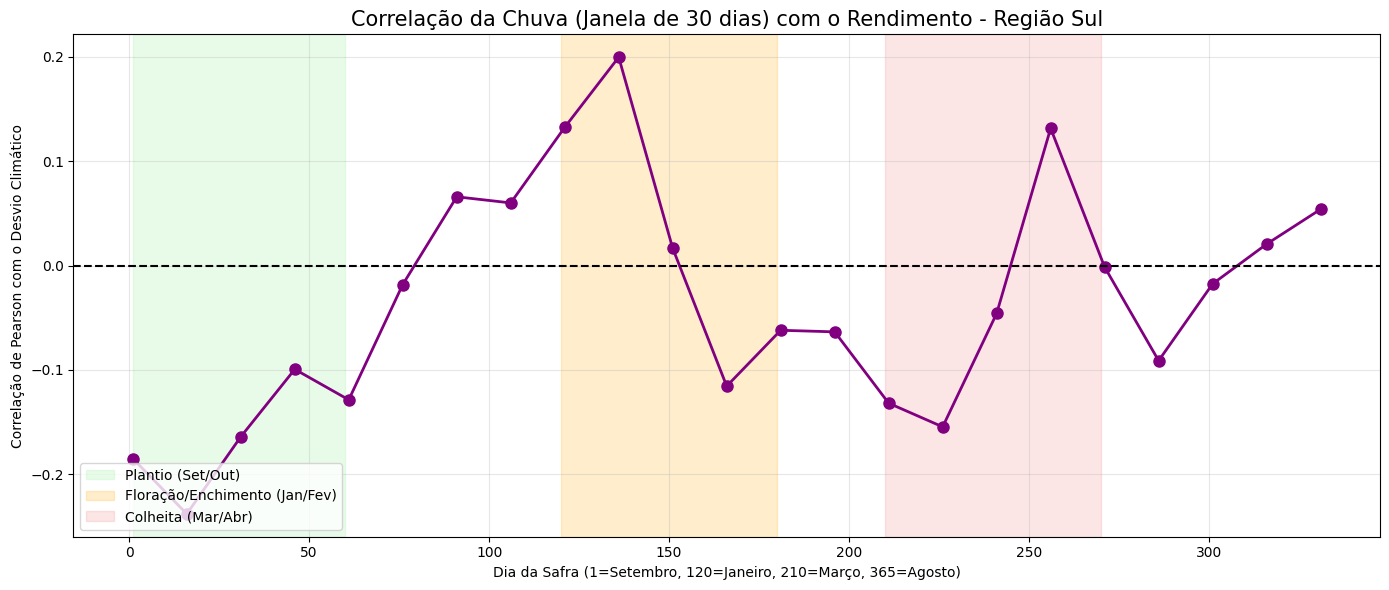

In [52]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import geobr

# 1. Preparando os dados
df_clima = pd.read_parquet("../../data/processed/clima_diario.parquet")
mapa = mapa_estacoes_cd_micro("../../data/processed/clima_diario.parquet")
mapa = mapa.dropna(subset=['CD_MICRO']).copy()
mapa['CD_MICRO'] = mapa['CD_MICRO'].astype(float).astype(int).astype(str)
mapa['codigo_estacao'] = mapa['codigo_estacao'].astype(str)
df_clima['codigo_estacao'] = df_clima['codigo_estacao'].astype(str)

df_diario = df_clima.merge(mapa[['codigo_estacao', 'CD_MICRO']], on='codigo_estacao')
df_diario['data'] = pd.to_datetime(df_diario['data'])

# 2. CRIANDO O CALENDÁRIO AGRÍCOLA DE FORMA VETORIZADA (MUITO RÁPIDO)
print("Calculando calendário agrícola (vetorizado)...")
df_diario['mes'] = df_diario['data'].dt.month

# Define o ano de início da safra (Setembro do ano anterior)
df_diario['ano_inicio_safra'] = np.where(
    df_diario['mes'] >= 9, 
    df_diario['data'].dt.year, 
    df_diario['data'].dt.year - 1
)

# Cria a data de 1º de Setembro do ano de início da safra
df_diario['data_inicio_safra'] = pd.to_datetime(
    df_diario['ano_inicio_safra'].astype(str) + '-09-01'
)

# Calcula o dia da safra de 1 a 365 sem usar apply (diferença direta de datas)
df_diario['dia_safra'] = (df_diario['data'] - df_diario['data_inicio_safra']).dt.days + 1
df_diario['ano_safra'] = df_diario['ano_inicio_safra'] + 1

# 3. Carrega o Rendimento (Região Sul)
df_base = carregar_base_final("../../data/processed/base_final_modelagem.csv")
df_base['CD_MICRO'] = df_base['CD_MICRO'].astype(float).astype(int).astype(str)

gdf_micro = geobr.read_micro_region(year=2020)
gdf_micro['code_micro'] = gdf_micro['code_micro'].astype(int).astype(str)
gdf_micro['Regiao'] = gdf_micro['code_region'].astype(float).astype(int).astype(str).map({
    '1': 'Norte', '2': 'Nordeste', '3': 'Sudeste', '4': 'Sul', '5': 'Centro-Oeste'
})

df_sul = df_base.merge(gdf_micro[['code_micro', 'Regiao']], left_on='CD_MICRO', right_on='code_micro')
df_sul = df_sul[df_sul['Regiao'] == 'Sul']

# 4. Janela Deslizante
resultados = []
print("Calculando correlações das janelas deslizantes...")

for dia_ini in range(1, 340, 15):
    dia_fim = dia_ini + 30
    
    # Filtra os dados da janela e agrupa por micro e ano
    df_janela = df_diario[(df_diario['dia_safra'] >= dia_ini) & (df_diario['dia_safra'] < dia_fim)]
    
    # Soma a chuva de 30 dias
    chuva_janela = df_janela.groupby(['CD_MICRO', 'ano_safra'])['prec_total'].sum().reset_index()
    chuva_janela = chuva_janela.rename(columns={'prec_total': 'chuva_30d', 'ano_safra': 'ano'})
    
    # Junta com o rendimento
    df_corr = df_sul.merge(chuva_janela, on=['CD_MICRO', 'ano'], how='inner')
    
    if len(df_corr) > 50: 
        corr = df_corr['chuva_30d'].corr(df_corr['desvio_clima'])
        resultados.append({'dia_inicio': dia_ini, 'correlacao': corr})

# 5. Plota o gráfico corrigido
res_df = pd.DataFrame(resultados)

plt.figure(figsize=(14, 6))
plt.plot(res_df['dia_inicio'], res_df['correlacao'], marker='o', color='purple', linewidth=2, markersize=8)
plt.axhline(0, color='black', linestyle='--')

# Marca as fases da soja no eixo X (Dia 1=Set, 120=Jan, 210=Mar)
plt.axvspan(1, 60, color='lightgreen', alpha=0.2, label='Plantio (Set/Out)')
plt.axvspan(120, 180, color='orange', alpha=0.2, label='Floração/Enchimento (Jan/Fev)')
plt.axvspan(210, 270, color='lightcoral', alpha=0.2, label='Colheita (Mar/Abr)')

plt.title('Correlação da Chuva (Janela de 30 dias) com o Rendimento - Região Sul', fontsize=15)
plt.xlabel('Dia da Safra (1=Setembro, 120=Janeiro, 210=Março, 365=Agosto)')
plt.ylabel('Correlação de Pearson com o Desvio Climático')
plt.legend(loc='lower left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Calculando calendário agrícola (vetorizado)...
Calculando correlações das janelas deslizantes...


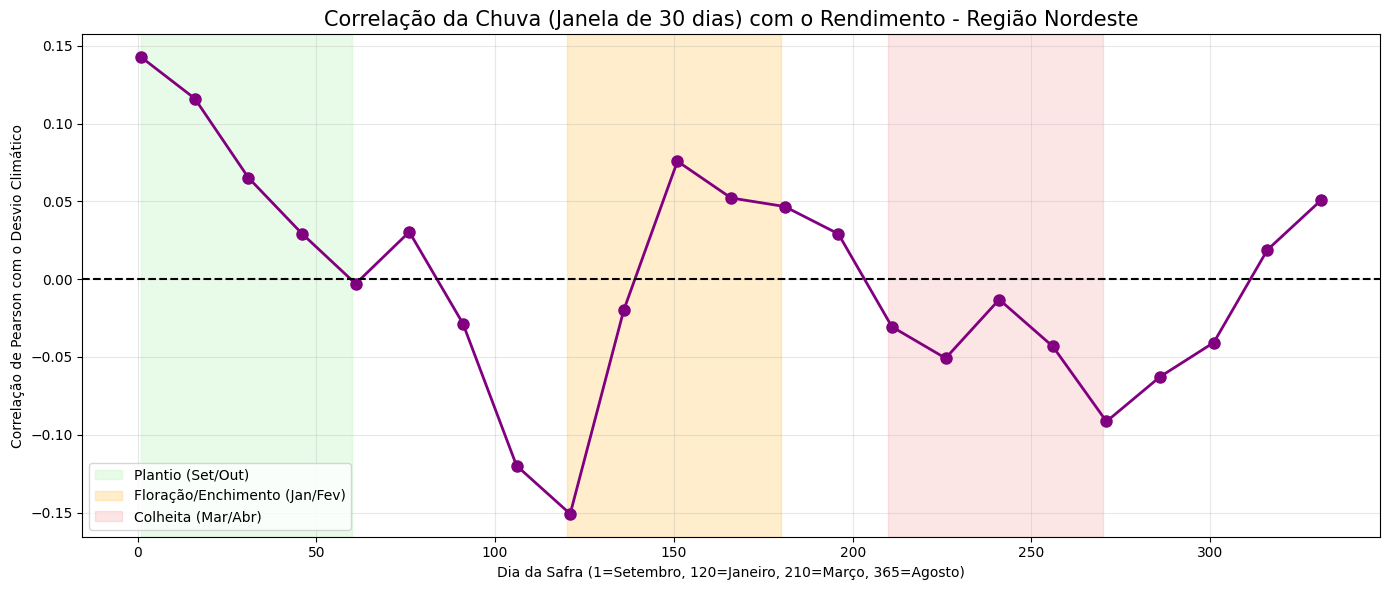

In [54]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import geobr

# 1. Preparando os dados
df_clima = pd.read_parquet("../../data/processed/clima_diario.parquet")
mapa = mapa_estacoes_cd_micro("../../data/processed/clima_diario.parquet")
mapa = mapa.dropna(subset=['CD_MICRO']).copy()
mapa['CD_MICRO'] = mapa['CD_MICRO'].astype(float).astype(int).astype(str)
mapa['codigo_estacao'] = mapa['codigo_estacao'].astype(str)
df_clima['codigo_estacao'] = df_clima['codigo_estacao'].astype(str)

df_diario = df_clima.merge(mapa[['codigo_estacao', 'CD_MICRO']], on='codigo_estacao')
df_diario['data'] = pd.to_datetime(df_diario['data'])

# 2. CRIANDO O CALENDÁRIO AGRÍCOLA DE FORMA VETORIZADA (MUITO RÁPIDO)
print("Calculando calendário agrícola (vetorizado)...")
df_diario['mes'] = df_diario['data'].dt.month

# Define o ano de início da safra (Setembro do ano anterior)
df_diario['ano_inicio_safra'] = np.where(
    df_diario['mes'] >= 9, 
    df_diario['data'].dt.year, 
    df_diario['data'].dt.year - 1
)

# Cria a data de 1º de Setembro do ano de início da safra
df_diario['data_inicio_safra'] = pd.to_datetime(
    df_diario['ano_inicio_safra'].astype(str) + '-09-01'
)

# Calcula o dia da safra de 1 a 365 sem usar apply (diferença direta de datas)
df_diario['dia_safra'] = (df_diario['data'] - df_diario['data_inicio_safra']).dt.days + 1
df_diario['ano_safra'] = df_diario['ano_inicio_safra'] + 1

# 3. Carrega o Rendimento (Região Sul)
df_base = carregar_base_final("../../data/processed/base_final_modelagem.csv")
df_base['CD_MICRO'] = df_base['CD_MICRO'].astype(float).astype(int).astype(str)

gdf_micro = geobr.read_micro_region(year=2020)
gdf_micro['code_micro'] = gdf_micro['code_micro'].astype(int).astype(str)
gdf_micro['Regiao'] = gdf_micro['code_region'].astype(float).astype(int).astype(str).map({
    '1': 'Norte', '2': 'Nordeste', '3': 'Sudeste', '4': 'Sul', '5': 'Centro-Oeste'
})

df_sul = df_base.merge(gdf_micro[['code_micro', 'Regiao']], left_on='CD_MICRO', right_on='code_micro')
df_sul = df_sul[df_sul['Regiao'] == 'Nordeste'] # Ou 'Centro-Oeste'

# 4. Janela Deslizante
resultados = []
print("Calculando correlações das janelas deslizantes...")

for dia_ini in range(1, 340, 15):
    dia_fim = dia_ini + 30
    
    # Filtra os dados da janela e agrupa por micro e ano
    df_janela = df_diario[(df_diario['dia_safra'] >= dia_ini) & (df_diario['dia_safra'] < dia_fim)]
    
    # Soma a chuva de 30 dias
    chuva_janela = df_janela.groupby(['CD_MICRO', 'ano_safra'])['prec_total'].sum().reset_index()
    chuva_janela = chuva_janela.rename(columns={'prec_total': 'chuva_30d', 'ano_safra': 'ano'})
    
    # Junta com o rendimento
    df_corr = df_sul.merge(chuva_janela, on=['CD_MICRO', 'ano'], how='inner')
    
    if len(df_corr) > 50: 
        corr = df_corr['chuva_30d'].corr(df_corr['desvio_clima'])
        resultados.append({'dia_inicio': dia_ini, 'correlacao': corr})

# 5. Plota o gráfico corrigido
res_df = pd.DataFrame(resultados)

plt.figure(figsize=(14, 6))
plt.plot(res_df['dia_inicio'], res_df['correlacao'], marker='o', color='purple', linewidth=2, markersize=8)
plt.axhline(0, color='black', linestyle='--')

# Marca as fases da soja no eixo X (Dia 1=Set, 120=Jan, 210=Mar)
plt.axvspan(1, 60, color='lightgreen', alpha=0.2, label='Plantio (Set/Out)')
plt.axvspan(120, 180, color='orange', alpha=0.2, label='Floração/Enchimento (Jan/Fev)')
plt.axvspan(210, 270, color='lightcoral', alpha=0.2, label='Colheita (Mar/Abr)')

plt.title('Correlação da Chuva (Janela de 30 dias) com o Rendimento - Região Nordeste', fontsize=15)
plt.xlabel('Dia da Safra (1=Setembro, 120=Janeiro, 210=Março, 365=Agosto)')
plt.ylabel('Correlação de Pearson com o Desvio Climático')
plt.legend(loc='lower left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Calculando calendário agrícola (vetorizado)...
Calculando correlações das janelas deslizantes...


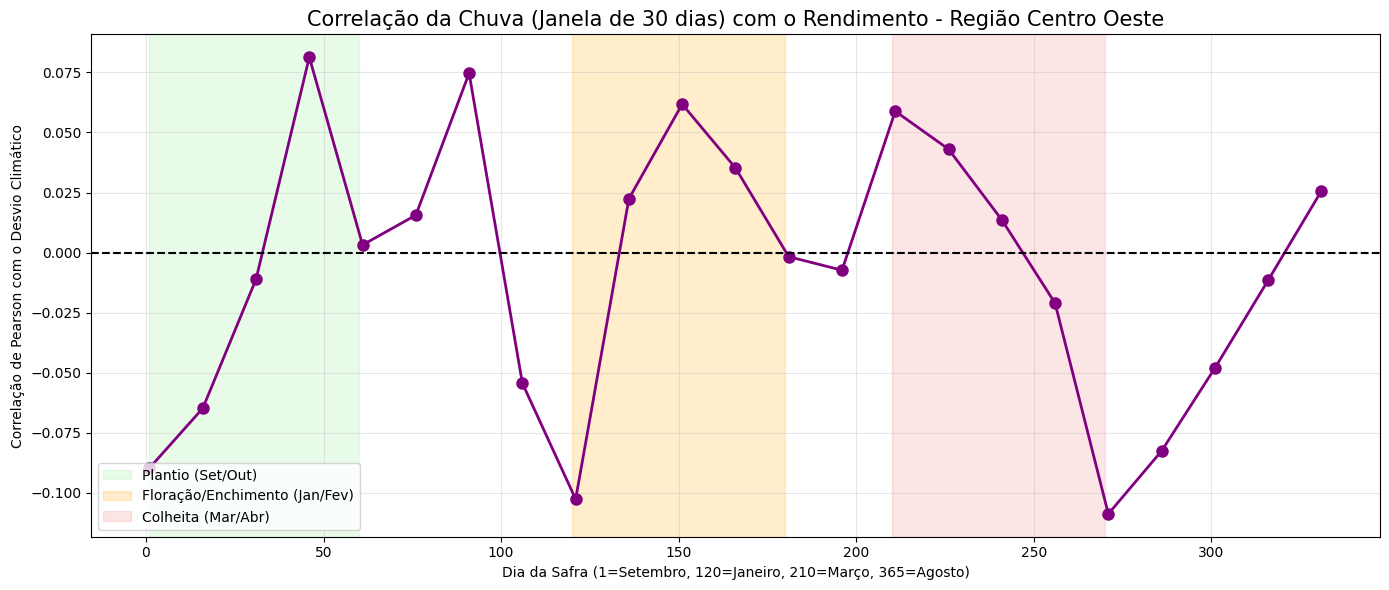

In [55]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import geobr

# 1. Preparando os dados
df_clima = pd.read_parquet("../../data/processed/clima_diario.parquet")
mapa = mapa_estacoes_cd_micro("../../data/processed/clima_diario.parquet")
mapa = mapa.dropna(subset=['CD_MICRO']).copy()
mapa['CD_MICRO'] = mapa['CD_MICRO'].astype(float).astype(int).astype(str)
mapa['codigo_estacao'] = mapa['codigo_estacao'].astype(str)
df_clima['codigo_estacao'] = df_clima['codigo_estacao'].astype(str)

df_diario = df_clima.merge(mapa[['codigo_estacao', 'CD_MICRO']], on='codigo_estacao')
df_diario['data'] = pd.to_datetime(df_diario['data'])

# 2. CRIANDO O CALENDÁRIO AGRÍCOLA DE FORMA VETORIZADA (MUITO RÁPIDO)
print("Calculando calendário agrícola (vetorizado)...")
df_diario['mes'] = df_diario['data'].dt.month

# Define o ano de início da safra (Setembro do ano anterior)
df_diario['ano_inicio_safra'] = np.where(
    df_diario['mes'] >= 9, 
    df_diario['data'].dt.year, 
    df_diario['data'].dt.year - 1
)

# Cria a data de 1º de Setembro do ano de início da safra
df_diario['data_inicio_safra'] = pd.to_datetime(
    df_diario['ano_inicio_safra'].astype(str) + '-09-01'
)

# Calcula o dia da safra de 1 a 365 sem usar apply (diferença direta de datas)
df_diario['dia_safra'] = (df_diario['data'] - df_diario['data_inicio_safra']).dt.days + 1
df_diario['ano_safra'] = df_diario['ano_inicio_safra'] + 1

# 3. Carrega o Rendimento (Região Sul)
df_base = carregar_base_final("../../data/processed/base_final_modelagem.csv")
df_base['CD_MICRO'] = df_base['CD_MICRO'].astype(float).astype(int).astype(str)

gdf_micro = geobr.read_micro_region(year=2020)
gdf_micro['code_micro'] = gdf_micro['code_micro'].astype(int).astype(str)
gdf_micro['Regiao'] = gdf_micro['code_region'].astype(float).astype(int).astype(str).map({
    '1': 'Norte', '2': 'Nordeste', '3': 'Sudeste', '4': 'Sul', '5': 'Centro-Oeste'
})

df_sul = df_base.merge(gdf_micro[['code_micro', 'Regiao']], left_on='CD_MICRO', right_on='code_micro')
df_sul = df_sul[df_sul['Regiao'] == 'Centro-Oeste'] 

# 4. Janela Deslizante
resultados = []
print("Calculando correlações das janelas deslizantes...")

for dia_ini in range(1, 340, 15):
    dia_fim = dia_ini + 30
    
    # Filtra os dados da janela e agrupa por micro e ano
    df_janela = df_diario[(df_diario['dia_safra'] >= dia_ini) & (df_diario['dia_safra'] < dia_fim)]
    
    # Soma a chuva de 30 dias
    chuva_janela = df_janela.groupby(['CD_MICRO', 'ano_safra'])['prec_total'].sum().reset_index()
    chuva_janela = chuva_janela.rename(columns={'prec_total': 'chuva_30d', 'ano_safra': 'ano'})
    
    # Junta com o rendimento
    df_corr = df_sul.merge(chuva_janela, on=['CD_MICRO', 'ano'], how='inner')
    
    if len(df_corr) > 50: 
        corr = df_corr['chuva_30d'].corr(df_corr['desvio_clima'])
        resultados.append({'dia_inicio': dia_ini, 'correlacao': corr})

# 5. Plota o gráfico corrigido
res_df = pd.DataFrame(resultados)

plt.figure(figsize=(14, 6))
plt.plot(res_df['dia_inicio'], res_df['correlacao'], marker='o', color='purple', linewidth=2, markersize=8)
plt.axhline(0, color='black', linestyle='--')

# Marca as fases da soja no eixo X (Dia 1=Set, 120=Jan, 210=Mar)
plt.axvspan(1, 60, color='lightgreen', alpha=0.2, label='Plantio (Set/Out)')
plt.axvspan(120, 180, color='orange', alpha=0.2, label='Floração/Enchimento (Jan/Fev)')
plt.axvspan(210, 270, color='lightcoral', alpha=0.2, label='Colheita (Mar/Abr)')

plt.title('Correlação da Chuva (Janela de 30 dias) com o Rendimento - Região Centro Oeste', fontsize=15)
plt.xlabel('Dia da Safra (1=Setembro, 120=Janeiro, 210=Março, 365=Agosto)')
plt.ylabel('Correlação de Pearson com o Desvio Climático')
plt.legend(loc='lower left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Calculando calendário agrícola (vetorizado)...
Calculando correlações das janelas deslizantes...


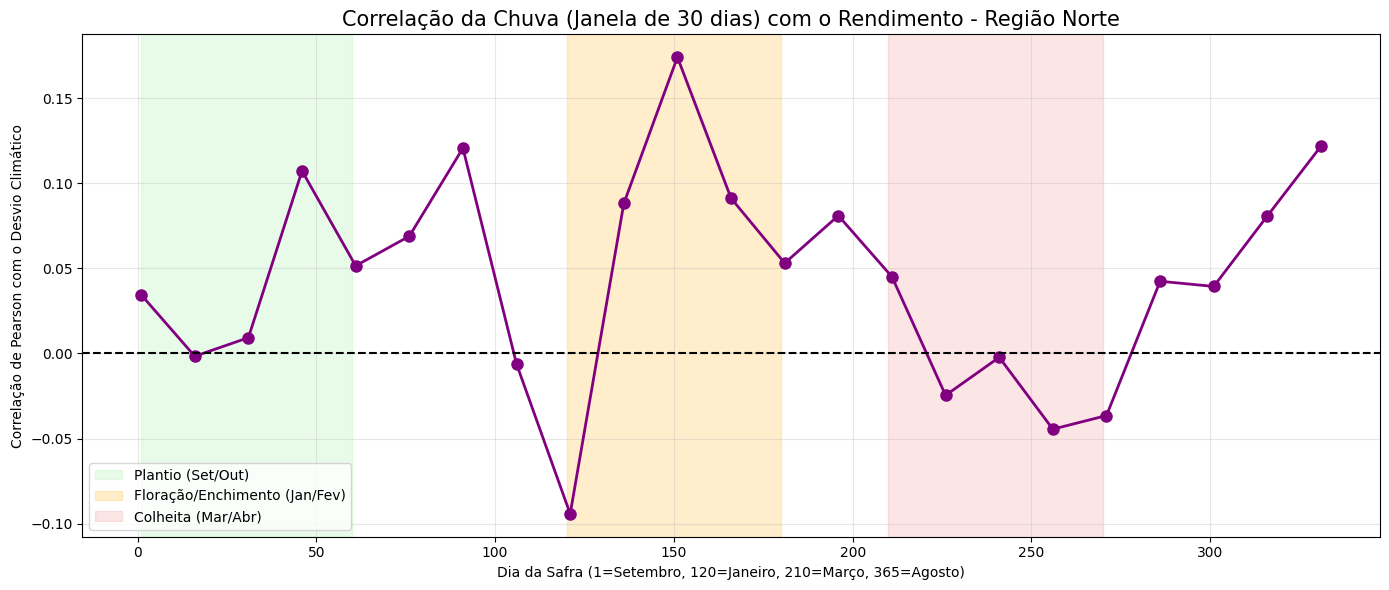

In [56]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import geobr

# 1. Preparando os dados
df_clima = pd.read_parquet("../../data/processed/clima_diario.parquet")
mapa = mapa_estacoes_cd_micro("../../data/processed/clima_diario.parquet")
mapa = mapa.dropna(subset=['CD_MICRO']).copy()
mapa['CD_MICRO'] = mapa['CD_MICRO'].astype(float).astype(int).astype(str)
mapa['codigo_estacao'] = mapa['codigo_estacao'].astype(str)
df_clima['codigo_estacao'] = df_clima['codigo_estacao'].astype(str)

df_diario = df_clima.merge(mapa[['codigo_estacao', 'CD_MICRO']], on='codigo_estacao')
df_diario['data'] = pd.to_datetime(df_diario['data'])

# 2. CRIANDO O CALENDÁRIO AGRÍCOLA DE FORMA VETORIZADA (MUITO RÁPIDO)
print("Calculando calendário agrícola (vetorizado)...")
df_diario['mes'] = df_diario['data'].dt.month

# Define o ano de início da safra (Setembro do ano anterior)
df_diario['ano_inicio_safra'] = np.where(
    df_diario['mes'] >= 9, 
    df_diario['data'].dt.year, 
    df_diario['data'].dt.year - 1
)

# Cria a data de 1º de Setembro do ano de início da safra
df_diario['data_inicio_safra'] = pd.to_datetime(
    df_diario['ano_inicio_safra'].astype(str) + '-09-01'
)

# Calcula o dia da safra de 1 a 365 sem usar apply (diferença direta de datas)
df_diario['dia_safra'] = (df_diario['data'] - df_diario['data_inicio_safra']).dt.days + 1
df_diario['ano_safra'] = df_diario['ano_inicio_safra'] + 1

# 3. Carrega o Rendimento (Região Sul)
df_base = carregar_base_final("../../data/processed/base_final_modelagem.csv")
df_base['CD_MICRO'] = df_base['CD_MICRO'].astype(float).astype(int).astype(str)

gdf_micro = geobr.read_micro_region(year=2020)
gdf_micro['code_micro'] = gdf_micro['code_micro'].astype(int).astype(str)
gdf_micro['Regiao'] = gdf_micro['code_region'].astype(float).astype(int).astype(str).map({
    '1': 'Norte', '2': 'Nordeste', '3': 'Sudeste', '4': 'Sul', '5': 'Centro-Oeste'
})

df_sul = df_base.merge(gdf_micro[['code_micro', 'Regiao']], left_on='CD_MICRO', right_on='code_micro')
df_sul = df_sul[df_sul['Regiao'] == 'Norte'] 

# 4. Janela Deslizante
resultados = []
print("Calculando correlações das janelas deslizantes...")

for dia_ini in range(1, 340, 15):
    dia_fim = dia_ini + 30
    
    # Filtra os dados da janela e agrupa por micro e ano
    df_janela = df_diario[(df_diario['dia_safra'] >= dia_ini) & (df_diario['dia_safra'] < dia_fim)]
    
    # Soma a chuva de 30 dias
    chuva_janela = df_janela.groupby(['CD_MICRO', 'ano_safra'])['prec_total'].sum().reset_index()
    chuva_janela = chuva_janela.rename(columns={'prec_total': 'chuva_30d', 'ano_safra': 'ano'})
    
    # Junta com o rendimento
    df_corr = df_sul.merge(chuva_janela, on=['CD_MICRO', 'ano'], how='inner')
    
    if len(df_corr) > 50: 
        corr = df_corr['chuva_30d'].corr(df_corr['desvio_clima'])
        resultados.append({'dia_inicio': dia_ini, 'correlacao': corr})

# 5. Plota o gráfico corrigido
res_df = pd.DataFrame(resultados)

plt.figure(figsize=(14, 6))
plt.plot(res_df['dia_inicio'], res_df['correlacao'], marker='o', color='purple', linewidth=2, markersize=8)
plt.axhline(0, color='black', linestyle='--')

# Marca as fases da soja no eixo X (Dia 1=Set, 120=Jan, 210=Mar)
plt.axvspan(1, 60, color='lightgreen', alpha=0.2, label='Plantio (Set/Out)')
plt.axvspan(120, 180, color='orange', alpha=0.2, label='Floração/Enchimento (Jan/Fev)')
plt.axvspan(210, 270, color='lightcoral', alpha=0.2, label='Colheita (Mar/Abr)')

plt.title('Correlação da Chuva (Janela de 30 dias) com o Rendimento - Região Norte', fontsize=15)
plt.xlabel('Dia da Safra (1=Setembro, 120=Janeiro, 210=Março, 365=Agosto)')
plt.ylabel('Correlação de Pearson com o Desvio Climático')
plt.legend(loc='lower left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Calculando calendário agrícola (vetorizado)...
Calculando correlações das janelas deslizantes...


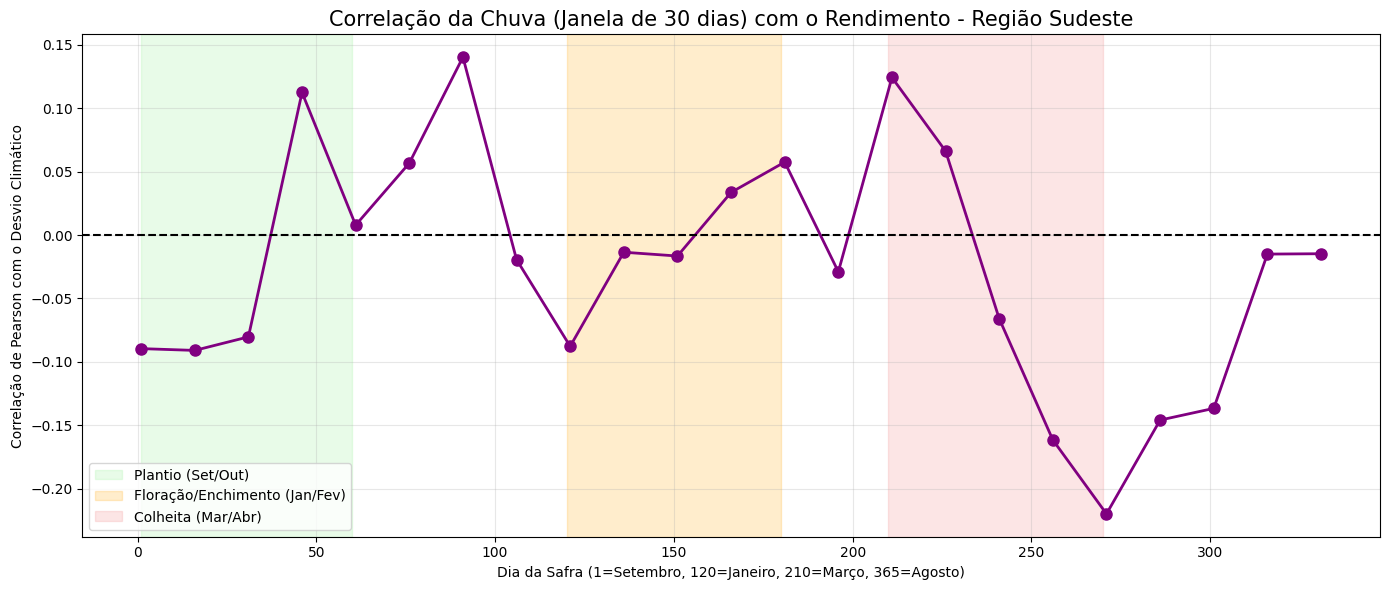

In [57]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import geobr

# 1. Preparando os dados
df_clima = pd.read_parquet("../../data/processed/clima_diario.parquet")
mapa = mapa_estacoes_cd_micro("../../data/processed/clima_diario.parquet")
mapa = mapa.dropna(subset=['CD_MICRO']).copy()
mapa['CD_MICRO'] = mapa['CD_MICRO'].astype(float).astype(int).astype(str)
mapa['codigo_estacao'] = mapa['codigo_estacao'].astype(str)
df_clima['codigo_estacao'] = df_clima['codigo_estacao'].astype(str)

df_diario = df_clima.merge(mapa[['codigo_estacao', 'CD_MICRO']], on='codigo_estacao')
df_diario['data'] = pd.to_datetime(df_diario['data'])

# 2. CRIANDO O CALENDÁRIO AGRÍCOLA DE FORMA VETORIZADA (MUITO RÁPIDO)
print("Calculando calendário agrícola (vetorizado)...")
df_diario['mes'] = df_diario['data'].dt.month

# Define o ano de início da safra (Setembro do ano anterior)
df_diario['ano_inicio_safra'] = np.where(
    df_diario['mes'] >= 9, 
    df_diario['data'].dt.year, 
    df_diario['data'].dt.year - 1
)

# Cria a data de 1º de Setembro do ano de início da safra
df_diario['data_inicio_safra'] = pd.to_datetime(
    df_diario['ano_inicio_safra'].astype(str) + '-09-01'
)

# Calcula o dia da safra de 1 a 365 sem usar apply (diferença direta de datas)
df_diario['dia_safra'] = (df_diario['data'] - df_diario['data_inicio_safra']).dt.days + 1
df_diario['ano_safra'] = df_diario['ano_inicio_safra'] + 1

# 3. Carrega o Rendimento (Região Sul)
df_base = carregar_base_final("../../data/processed/base_final_modelagem.csv")
df_base['CD_MICRO'] = df_base['CD_MICRO'].astype(float).astype(int).astype(str)

gdf_micro = geobr.read_micro_region(year=2020)
gdf_micro['code_micro'] = gdf_micro['code_micro'].astype(int).astype(str)
gdf_micro['Regiao'] = gdf_micro['code_region'].astype(float).astype(int).astype(str).map({
    '1': 'Norte', '2': 'Nordeste', '3': 'Sudeste', '4': 'Sul', '5': 'Centro-Oeste'
})

df_sul = df_base.merge(gdf_micro[['code_micro', 'Regiao']], left_on='CD_MICRO', right_on='code_micro')
df_sul = df_sul[df_sul['Regiao'] == 'Sudeste'] 

# 4. Janela Deslizante
resultados = []
print("Calculando correlações das janelas deslizantes...")

for dia_ini in range(1, 340, 15):
    dia_fim = dia_ini + 30
    
    # Filtra os dados da janela e agrupa por micro e ano
    df_janela = df_diario[(df_diario['dia_safra'] >= dia_ini) & (df_diario['dia_safra'] < dia_fim)]
    
    # Soma a chuva de 30 dias
    chuva_janela = df_janela.groupby(['CD_MICRO', 'ano_safra'])['prec_total'].sum().reset_index()
    chuva_janela = chuva_janela.rename(columns={'prec_total': 'chuva_30d', 'ano_safra': 'ano'})
    
    # Junta com o rendimento
    df_corr = df_sul.merge(chuva_janela, on=['CD_MICRO', 'ano'], how='inner')
    
    if len(df_corr) > 50: 
        corr = df_corr['chuva_30d'].corr(df_corr['desvio_clima'])
        resultados.append({'dia_inicio': dia_ini, 'correlacao': corr})

# 5. Plota o gráfico corrigido
res_df = pd.DataFrame(resultados)

plt.figure(figsize=(14, 6))
plt.plot(res_df['dia_inicio'], res_df['correlacao'], marker='o', color='purple', linewidth=2, markersize=8)
plt.axhline(0, color='black', linestyle='--')

# Marca as fases da soja no eixo X (Dia 1=Set, 120=Jan, 210=Mar)
plt.axvspan(1, 60, color='lightgreen', alpha=0.2, label='Plantio (Set/Out)')
plt.axvspan(120, 180, color='orange', alpha=0.2, label='Floração/Enchimento (Jan/Fev)')
plt.axvspan(210, 270, color='lightcoral', alpha=0.2, label='Colheita (Mar/Abr)')

plt.title('Correlação da Chuva (Janela de 30 dias) com o Rendimento - Região Sudeste', fontsize=15)
plt.xlabel('Dia da Safra (1=Setembro, 120=Janeiro, 210=Março, 365=Agosto)')
plt.ylabel('Correlação de Pearson com o Desvio Climático')
plt.legend(loc='lower left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

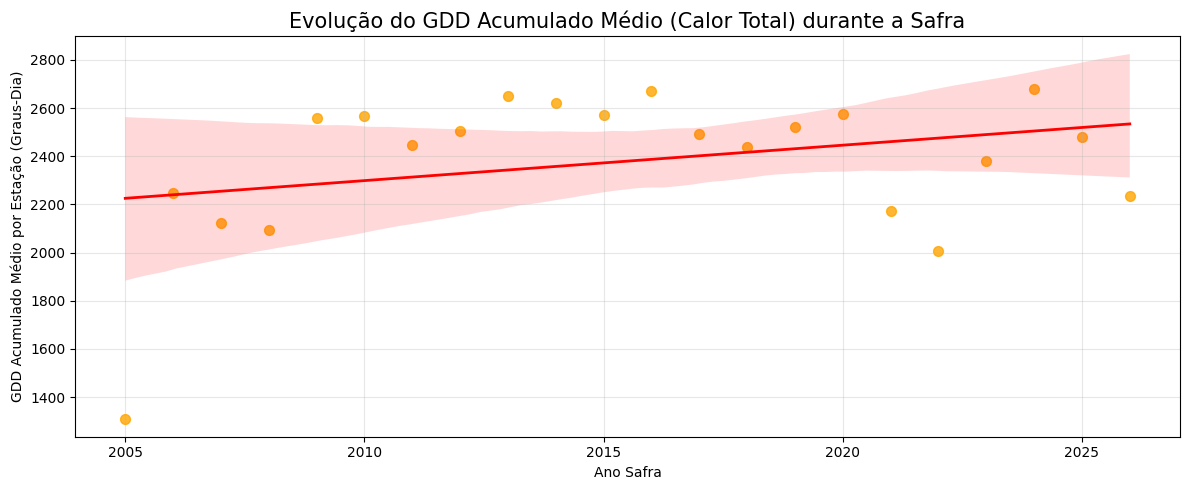

Correlação de Pearson (Ano vs GDD Médio): 0.308


In [58]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Carrega os dados direto do arquivo para não depender de variáveis antigas
df_clima = pd.read_parquet("../../data/processed/clima_diario.parquet")
df_clima['data'] = pd.to_datetime(df_clima['data'])
df_clima['mes'] = df_clima['data'].dt.month

# 2. Define a janela da safra (Out a Mar)
# Para isso, se o mês for 10, 11, 12, a safra é o ano+1. Se for 1, 2, 3, é o próprio ano.
df_clima['ano_safra'] = np.where(df_clima['mes'] >= 10, df_clima['data'].dt.year + 1, df_clima['data'].dt.year)

# Filtra apenas os meses da safra (Out, Nov, Dez, Jan, Fev, Mar)
janela_safra = df_clima[df_clima['mes'].isin([10, 11, 12, 1, 2, 3])]

# 3. Calcula o GDD Acumulado Médio por Safra
# (Soma o GDD de cada estação na safra e depois tira a média entre as estações)
gdd_por_estacao = janela_safra.groupby(['codigo_estacao', 'ano_safra'])['gdd'].sum().reset_index()
gdd_medio_ano = gdd_por_estacao.groupby('ano_safra')['gdd'].mean().reset_index()

# 4. Plota o gráfico com a linha de tendência
plt.figure(figsize=(12, 5))
sns.regplot(
    data=gdd_medio_ano, 
    x='ano_safra', 
    y='gdd', 
    scatter_kws={'color': 'orange', 's': 50}, 
    line_kws={'color': 'red', 'linewidth': 2}
)

plt.title('Evolução do GDD Acumulado Médio (Calor Total) durante a Safra', fontsize=15)
plt.xlabel('Ano Safra')
plt.ylabel('GDD Acumulado Médio por Estação (Graus-Dia)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 5. Imprime a correlação para sabermos se a tendência é estatisticamente válida
correlacao = gdd_medio_ano['ano_safra'].corr(gdd_medio_ano['gdd'])
print(f"Correlação de Pearson (Ano vs GDD Médio): {correlacao:.3f}")

In [ ]:
# linha vermelha reta ascendente = safras recentes estão acumulando um pouco mais de calor (GDD) do que as antigas. Isso é um forte indicativo de aquecimento climático ou de mudanças no ciclo da cultura. 
# Porém leve dado que a reta não está muito inclinada

#Correlação de Pearson (Ano vs GDD Médio): 0.308 - Relevancia media/alta 

## 1.2  Índices hídricos
Balanço hídrico sequencial (Thornthwaite-Mather) com CAD derivada do solo (ver seção 2). Produz ARM (armazenamento), ETR, ETP, déficit e excedente por decêndio.
ISNA (Índice de Satisfação das Necessidades de Água = ETR/ETc), o índice oficial do zoneamento agrícola.
Índice de Satisfação Hídrica (WRSI) com Kc da soja por fase.
ETP por Hargreaves-Samani (só precisa de Tmax, Tmin e radiação extraterrestre) ou Penman-Monteith (você tem umidade, vento e radiação).
SPI (1, 3, 6 meses) e SPEI (chuva − ETP). Compare ambos, dado que o SPEI capta a seca quente que o SPI não vê.
PDSI/Palmer, se quiser um índice acumulativo.
Razão P/ETP na floração e no enchimento.
Intensidade de chuva: chuva / dia chuvoso, SDII, R10/R20/R50 (dias com mais de 10/20/50 mm), índice de concentração de precipitação (Oliver) e Gini de chuva, que diferenciam 600 mm bem distribuídos de 600 mm em 3 tempestades.
Run-length distributions: além do CDD máximo, a distribuição de sequências secas (nº de veranicos >7, >10, >15 dias) e a posição do veranico dentro da fase fenológica. Um veranico de 12 dias em R5 é muito pior do que em V3.
Primeiro dia útil de semeadura (chuva acumulada >20–30 mm em 5–10 dias após 1º de set) e atraso de semeadura como feature. O atraso se correlaciona com o ENSO?
Fim da estação chuvosa e comprimento da estação chuvosa.
Dry spell × wet spell: matriz de transição (Markov de 1ª ordem, P(seco|seco)), por microrregião.


In [59]:
import pandas as pd
import numpy as np

print("Carregando dados diários...")
df_clima = pd.read_parquet("../../data/processed/clima_diario.parquet")
df_clima['data'] = pd.to_datetime(df_clima['data'])
df_clima = df_clima.sort_values(['codigo_estacao', 'data'])

# 1. Define ano-safra
df_clima['mes'] = df_clima['data'].dt.month
df_clima['ano_safra'] = np.where(df_clima['mes'] >= 10, df_clima['data'].dt.year + 1, df_clima['data'].dt.year)

# 2. Função para calcular sequências (Run-lengths) de dias secos
def calcular_veranicos(serie_chuva):
    # Dia seco = chuva < 2mm
    seco = (serie_chuva < 2.0).astype(int)
    # Agrupa sequências contínuas
    grupos = (seco != seco.shift()).cumsum()
    tamanhos = seco.groupby(grupos).sum()
    # Filtra apenas os períodos que são secos e conta quantos veranicos de cada tamanho
    return pd.Series({
        'veranico_7d': (tamanhos[tamanhos >= 7]).count(),
        'veranico_10d': (tamanhos[tamanhos >= 10]).count(),
        'veranico_15d': (tamanhos[tamanhos >= 15]).count(),
        'veranico_max': tamanhos.max() if len(tamanhos) > 0 else 0
    })

# 3. Agregação por estação e safra (janela out-mar)
janela_safra = df_clima[df_clima['mes'].isin([10, 11, 12, 1, 2, 3])]

# Intensidade de chuva
chuva_estacao = janela_safra.groupby(['codigo_estacao', 'ano_safra']).agg(
    chuva_total=('prec_total', 'sum'),
    dias_chuvosos=('prec_total', lambda x: (x > 1).sum()),
    dias_R10=('prec_total', lambda x: (x > 10).sum()),
    dias_R20=('prec_total', lambda x: (x > 20).sum()),
    dias_R50=('prec_total', lambda x: (x > 50).sum()),
).reset_index()

# SDII (Simple Daily Intensity Index) = chuva total / dias chuvosos
chuva_estacao['SDII'] = chuva_estacao['chuva_total'] / chuva_estacao['dias_chuvosos'].replace(0, np.nan)

# Calcula os veranicos
veranicos = janela_safra.groupby(['codigo_estacao', 'ano_safra'])['prec_total'].apply(calcular_veranicos).unstack().reset_index()

# Junta tudo
df_intensidade = chuva_estacao.merge(veranicos, on=['codigo_estacao', 'ano_safra'], how='left')
df_intensidade.to_parquet("../../data/processed/features_chuva_intensidade.parquet", index=False)
print(f"✅ Índices de chuva calculados: {len(df_intensidade)} registros.")

Carregando dados diários...
✅ Índices de chuva calculados: 9323 registros.


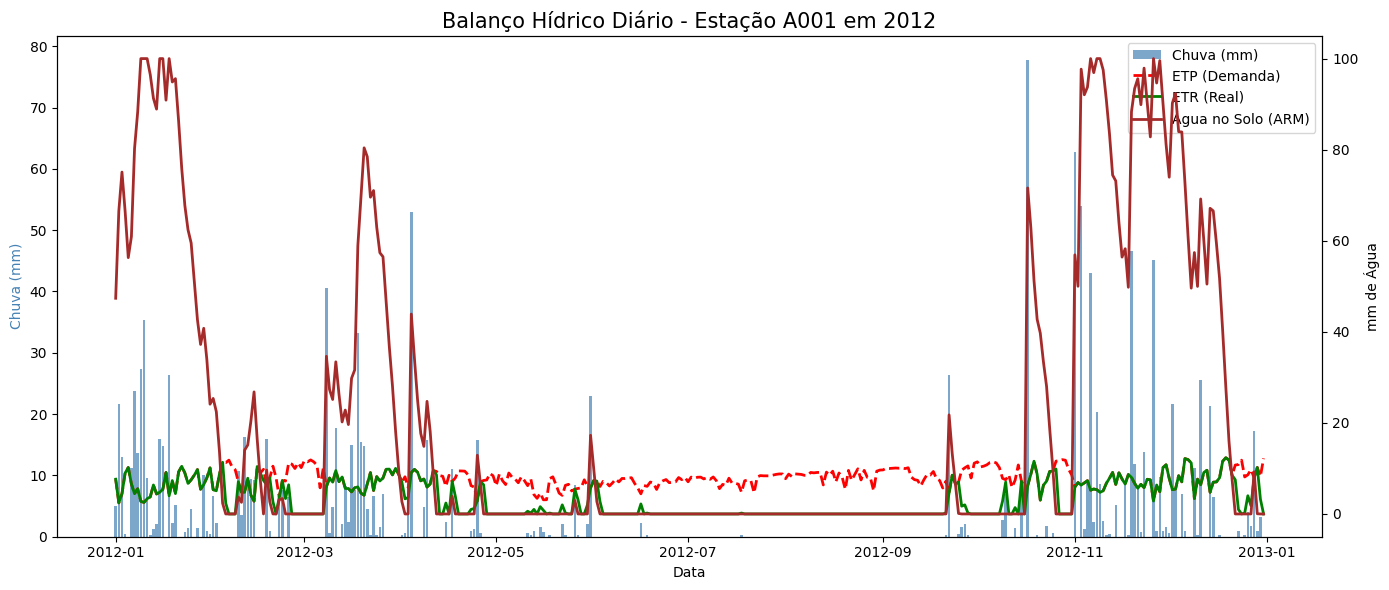

In [62]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Carrega os dados que você acabou de gerar
df_balanco = pd.read_parquet("../../data/processed/features_balanco_hidrico.parquet") # Só para pegar as colunas
# Vamos recalcular o diário para uma estação específica
# (variável própria: a célula seguinte usa o df_clima das células anteriores)
df_clima_grafico = pd.read_parquet("../../data/processed/clima_diario.parquet")
df_clima_grafico['data'] = pd.to_datetime(df_clima_grafico['data'])

# Filtrar uma estação e um ano específico (ex: uma estação do Sul em 2012, ano de seca)
estacao = df_clima_grafico['codigo_estacao'].iloc[0] # Pega a primeira estação
ano_alvo = 2012

# Filtra os dados diários
df_plot = df_clima_grafico[(df_clima_grafico['codigo_estacao'] == estacao) & (df_clima_grafico['data'].dt.year == ano_alvo)].sort_values('data').copy()

# Recalcula o ETP e o balanço para esse ano (simplificado para o gráfico)
df_plot['rad_MJ'] = df_plot['radiacao_total'] / 1000
df_plot['ETP'] = df_plot['rad_MJ'] * 0.408
df_plot['ETP'] = np.where(df_plot['ETP'].isna() | (df_plot['ETP'] < 1), (df_plot['temp_media'] * 0.15).clip(lower=1.5), df_plot['ETP'])

CAD = 100.0
ARM = np.zeros(len(df_plot))
ETR = np.zeros(len(df_plot))
DEF = np.zeros(len(df_plot))
arm_ant = CAD * 0.5

for i in range(len(df_plot)):
    disp = arm_ant + df_plot['prec_total'].iloc[i]
    if disp >= df_plot['ETP'].iloc[i]:
        ETR[i] = df_plot['ETP'].iloc[i]
        arm_novo = disp - df_plot['ETP'].iloc[i]
        ARM[i] = min(arm_novo, CAD)
    else:
        ETR[i] = disp
        ARM[i] = 0
        DEF[i] = df_plot['ETP'].iloc[i] - disp
    arm_ant = ARM[i]

df_plot['ARM'] = ARM
df_plot['ETR'] = ETR
df_plot['DEF'] = DEF

# Plotagem
fig, ax1 = plt.subplots(figsize=(14, 6))

# Eixo 1: Chuva
ax1.bar(df_plot['data'], df_plot['prec_total'], color='steelblue', label='Chuva (mm)', alpha=0.7)
ax1.set_ylabel('Chuva (mm)', color='steelblue')
ax1.set_xlabel('Data')

# Eixo 2: ETP, ETR e ARM
ax2 = ax1.twinx()
ax2.plot(df_plot['data'], df_plot['ETP'], color='red', linestyle='--', label='ETP (Demanda)', linewidth=2)
ax2.plot(df_plot['data'], df_plot['ETR'], color='green', linestyle='-', label='ETR (Real)', linewidth=2)
ax2.plot(df_plot['data'], df_plot['ARM'], color='brown', label='Água no Solo (ARM)', linewidth=2)
ax2.set_ylabel('mm de Água')
ax2.grid(False)

# Juntando as legendas
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper right')

plt.title(f'Balanço Hídrico Diário - Estação {estacao} em {ano_alvo}', fontsize=15)
plt.tight_layout()
plt.show()

In [60]:
print("Calculando Balanço Hídrico Sequencial (pode demorar alguns minutos)...")

# 1. Estimativa de ETP (Hargreaves-Samani simplificado)
# ETP = 0.0023 * (Tmean + 17.8) * sqrt(Tmax - Tmin) * Ra (Radiação Extraterrestre)
# Como não temos Ra fácil, usamos uma aproximação pela radiação solar medida
# Se radiacao_total estiver em kJ/m2, convertemos para MJ/m2 (dividindo por 1000)
df_clima['rad_MJ'] = df_clima['radiacao_total'] / 1000
# ETP (mm/dia) ~ 0.408 * radiação (para dias claros) - simplificação aceitável para o Brasil
df_clima['ETP'] = df_clima['rad_MJ'] * 0.408 
# Se a radiação estiver nula, usa Hargreaves básico (Tmean * 0.15)
df_clima['ETP'] = np.where(df_clima['ETP'].isna() | (df_clima['ETP'] < 1), 
                           (df_clima['temp_media'] * 0.15).clip(lower=1.5), 
                           df_clima['ETP'])

# Define a Capacidade de Água Disponível (CAD) fixa em 100mm (aprox. média para solos argilosos de soja)
CAD = 100.0

def calcular_balanco_hidrico(grupo):
    # Inicializa variáveis
    n = len(grupo)
    ARM = np.zeros(n) # Armazenamento de água no solo
    ETR = np.zeros(n) # Evapotranspiração Real
    DEF = np.zeros(n) # Deficiência Hídrica
    EXC = np.zeros(n) # Excedente Hídrico
    
    arm_anterior = CAD * 0.5 # Assume que o solo começa com 50% de água
    
    chuva = grupo['prec_total'].values
    etp = grupo['ETP'].values
    
    for i in range(n):
        # Balanço diário
        disponivel = arm_anterior + chuva[i]
        
        if disponivel >= etp[i]:
            # Chuva suficiente para atender a ETP
            ETR[i] = etp[i]
            arm_novo = disponivel - etp[i]
            if arm_novo > CAD:
                EXC[i] = arm_novo - CAD
                ARM[i] = CAD
            else:
                ARM[i] = arm_novo
        else:
            # Chuva insuficiente (solo secando)
            ETR[i] = disponivel
            ARM[i] = 0
            DEF[i] = etp[i] - disponivel
            
        arm_anterior = ARM[i]
        
    return pd.DataFrame({
        'codigo_estacao': grupo['codigo_estacao'].values,
        'data': grupo['data'].values,
        'ano_safra': grupo['ano_safra'].values,
        'mes': grupo['mes'].values,
        'ETR': ETR,
        'DEF': DEF,
        'EXC': EXC,
        'ETP': etp,
        'ARM': ARM
    })

# Agrupa por estação para manter a continuidade temporal
# (iteração explícita: no pandas 3 o groupby().apply não passa mais a coluna de agrupamento)
df_balanco = pd.concat([calcular_balanco_hidrico(g) for _, g in df_clima.groupby('codigo_estacao')], ignore_index=True)

# 2. Agregação para a safra e cálculo do ISNA
# ISNA = ETR / ETP (quanto da necessidade hídrica foi atendida)
df_balanco['ISNA_diario'] = df_balanco['ETR'] / df_balanco['ETP']

janela_balanco = df_balanco[df_balanco['mes'].isin([10, 11, 12, 1, 2, 3])]

# Calcula o ISNA da fase crítica (Floração/Enchimento = Jan, Fev, Mar)
janela_critica = df_balanco[df_balanco['mes'].isin([1, 2, 3])]

indices_safra = janela_balanco.groupby(['codigo_estacao', 'ano_safra']).agg(
    ISNA_safra=('ISNA_diario', 'mean'),
    deficit_total=('DEF', 'sum'),
    excedente_total=('EXC', 'sum'),
    ETP_safra=('ETP', 'sum')
).reset_index()

indices_criticos = janela_critica.groupby(['codigo_estacao', 'ano_safra']).agg(
    ISNA_critico=('ISNA_diario', 'mean'),
    deficit_critico=('DEF', 'sum')
).reset_index()

df_hidrico = indices_safra.merge(indices_criticos, on=['codigo_estacao', 'ano_safra'], how='left')
df_hidrico.to_parquet("../../data/processed/features_balanco_hidrico.parquet", index=False)
print(f"✅ Balanço hídrico calculado: {len(df_hidrico)} registros.")

Calculando Balanço Hídrico Sequencial (pode demorar alguns minutos)...


/var/folders/j3/kppygfjs7xj9nbzbwjj9cjc80000gn/T/ipykernel_75219/4199679137.py:65: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_balanco = df_clima.groupby('codigo_estacao').apply(calcular_balanco_hidrico).reset_index(drop=True)


✅ Balanço hídrico calculado: 9323 registros.


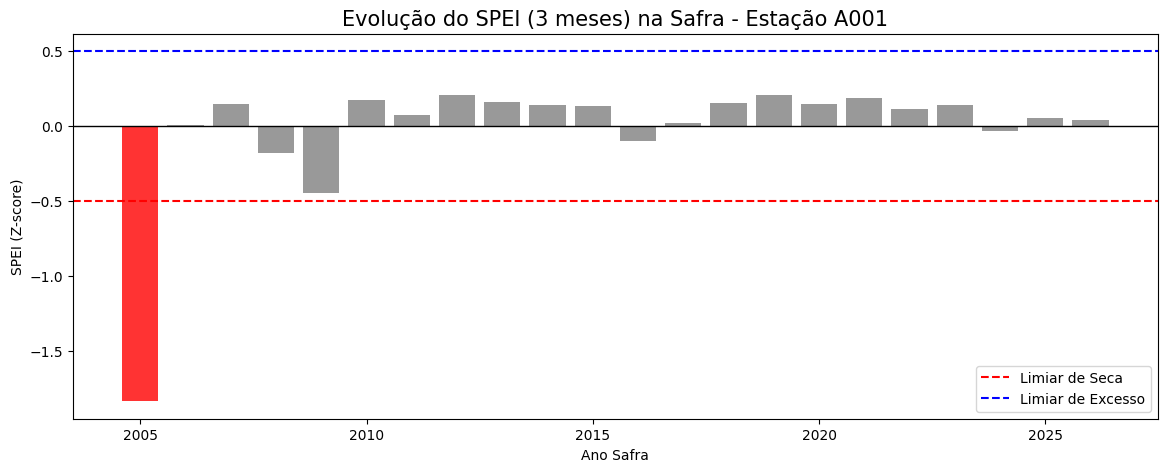

In [63]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Carrega o arquivo de SPI/SPEI
df_spi = pd.read_parquet("../../data/processed/features_spi_spei.parquet")

# Filtra para a mesma estação
df_spi_plot = df_spi[df_spi['codigo_estacao'] == estacao].sort_values('ano_safra')

# Plota a série histórica do SPEI de 3 meses
plt.figure(figsize=(14, 5))
colors = ['red' if x < -0.5 else 'blue' if x > 0.5 else 'gray' for x in df_spi_plot['SPEI_3m_medio']]
plt.bar(df_spi_plot['ano_safra'], df_spi_plot['SPEI_3m_medio'], color=colors, alpha=0.8)

plt.axhline(0, color='black', linewidth=1)
plt.axhline(-0.5, color='red', linestyle='--', label='Limiar de Seca')
plt.axhline(0.5, color='blue', linestyle='--', label='Limiar de Excesso')

plt.title(f'Evolução do SPEI (3 meses) na Safra - Estação {estacao}', fontsize=15)
plt.xlabel('Ano Safra')
plt.ylabel('SPEI (Z-score)')
plt.legend()
plt.show()

In [61]:
print("Calculando SPI e SPEI...")

# Agrega a chuva e a ETP mensal por estação
df_clima['ano_mes'] = df_clima['data'].dt.to_period('M')
mensal = df_clima.groupby(['codigo_estacao', 'ano_mes']).agg(
    chuva_mensal=('prec_total', 'sum'),
    etp_mensal=('ETP', 'sum')
).reset_index()

# Cria as janelas acumuladas (1, 3, 6 meses)
for janela in [1, 3, 6]:
    mensal[f'chuva_{janela}m'] = mensal.groupby('codigo_estacao')['chuva_mensal'].transform(
        lambda x: x.rolling(janela, min_periods=1).sum()
    )
    mensal[f'spei_{janela}m'] = mensal.groupby('codigo_estacao').apply(
        lambda x: (x['chuva_mensal'] - x['etp_mensal']).rolling(janela, min_periods=1).sum()
    ).reset_index(level=0, drop=True)

# Padronização (Z-score por estação)
for col in ['chuva_1m', 'chuva_3m', 'chuva_6m', 'spei_1m', 'spei_3m', 'spei_6m']:
    mensal[f'{col}_z'] = mensal.groupby('codigo_estacao')[col].transform(
        lambda x: (x - x.mean()) / x.std()
    )

# Seleciona as colunas de interesse para levar para a base final
cols_finais = ['codigo_estacao', 'ano_mes'] + [c for c in mensal.columns if c.endswith('_z')]
df_spi = mensal[cols_finais].copy()

# Converte ano_mes de volta para ano e mes numéricos para o merge
df_spi['ano'] = df_spi['ano_mes'].dt.year
df_spi['mes'] = df_spi['ano_mes'].dt.month
df_spi['ano_safra'] = np.where(df_spi['mes'] >= 10, df_spi['ano'] + 1, df_spi['ano'])

# Pega o SPI/SPEI médio da safra
df_spi_safra = df_spi.groupby(['codigo_estacao', 'ano_safra']).agg(
    SPI_3m_medio=('chuva_3m_z', 'mean'),
    SPEI_3m_medio=('spei_3m_z', 'mean'),
    SPEI_6m_medio=('spei_6m_z', 'mean')
).reset_index()

df_spi_safra.to_parquet("../../data/processed/features_spi_spei.parquet", index=False)
print(f"✅ SPI/SPEI calculados: {len(df_spi_safra)} registros.")

Calculando SPI e SPEI...


/var/folders/j3/kppygfjs7xj9nbzbwjj9cjc80000gn/T/ipykernel_75219/3978245712.py:15: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  mensal[f'spei_{janela}m'] = mensal.groupby('codigo_estacao').apply(
/var/folders/j3/kppygfjs7xj9nbzbwjj9cjc80000gn/T/ipykernel_75219/3978245712.py:15: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  mensal[f'spei_{janela}m'] = mensal.groupby('codigo_estacao').apply(
/var/folders/j3/kppygfjs7x

✅ SPI/SPEI calculados: 9939 registros.


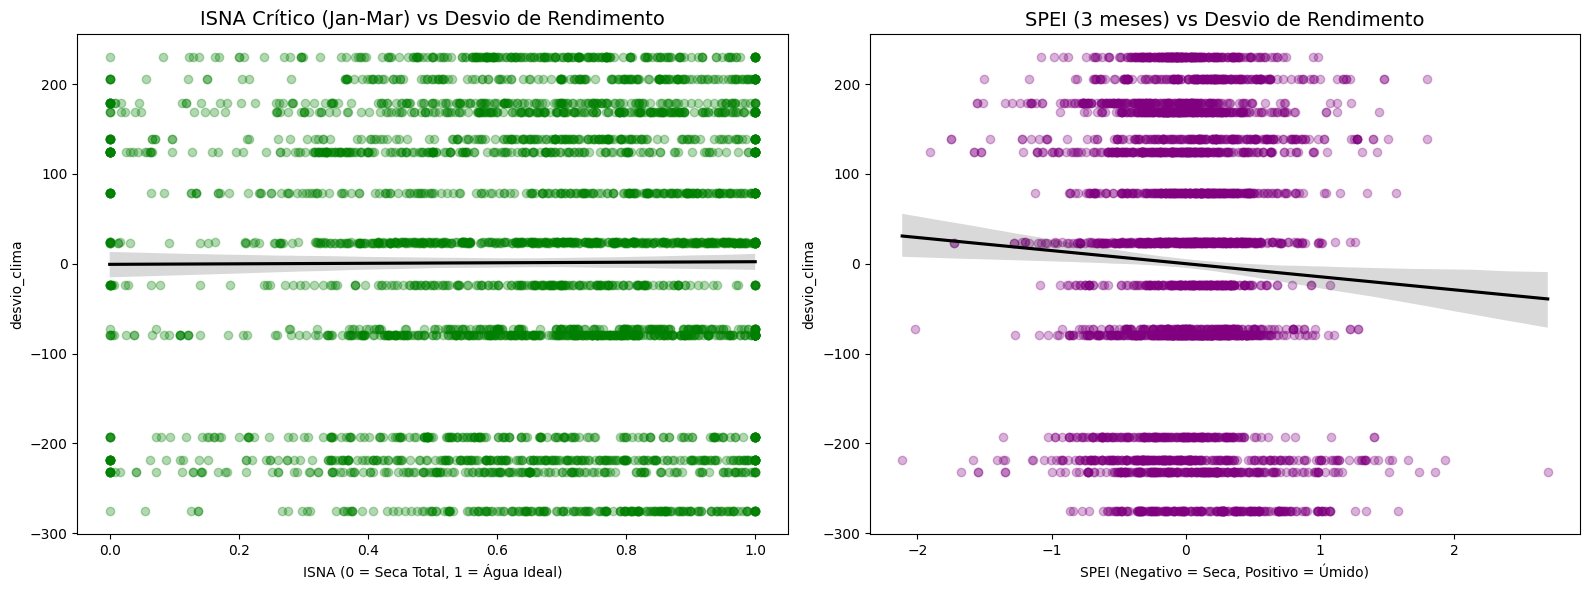

In [64]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Carrega a base de modelagem
df_base = carregar_base_final("../../data/processed/base_final_modelagem.csv")
df_base['CD_MICRO'] = df_base['CD_MICRO'].astype(float).astype(int).astype(str)

# 2. Carrega o mapa estação -> microrregião
mapa = mapa_estacoes_cd_micro("../../data/processed/clima_diario.parquet")
mapa = mapa.dropna(subset=['CD_MICRO']).copy()
mapa['CD_MICRO'] = mapa['CD_MICRO'].astype(float).astype(int).astype(str)
mapa['codigo_estacao'] = mapa['codigo_estacao'].astype(str)

# 3. Carrega os índices que você calculou
df_balanco = pd.read_parquet("../../data/processed/features_balanco_hidrico.parquet")
df_spi = pd.read_parquet("../../data/processed/features_spi_spei.parquet")

# 4. Mapeia os índices para a microrregião (tira a média das estações de cada micro)
balanco_micro = df_balanco.merge(mapa[['codigo_estacao', 'CD_MICRO']], on='codigo_estacao')
balanco_micro = balanco_micro.groupby(['CD_MICRO', 'ano_safra']).agg(ISNA_critico_medio=('ISNA_critico', 'mean')).reset_index().rename(columns={'ano_safra': 'ano'})

spi_micro = df_spi.merge(mapa[['codigo_estacao', 'CD_MICRO']], on='codigo_estacao')
spi_micro = spi_micro.groupby(['CD_MICRO', 'ano_safra']).agg(SPEI_medio=('SPEI_3m_medio', 'mean')).reset_index().rename(columns={'ano_safra': 'ano'})

# 5. Junta com a base
df_final = df_base.merge(balanco_micro, on=['CD_MICRO', 'ano'], how='left')
df_final = df_final.merge(spi_micro, on=['CD_MICRO', 'ano'], how='left')

# 6. Plota a correlação
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# ISNA vs Rendimento
sns.regplot(data=df_final.dropna(subset=['ISNA_critico_medio', 'desvio_clima']), 
            x='ISNA_critico_medio', y='desvio_clima', ax=axes[0], 
            scatter_kws={'alpha':0.3, 'color':'green'}, line_kws={'color': 'black'})
axes[0].set_title('ISNA Crítico (Jan-Mar) vs Desvio de Rendimento', fontsize=14)
axes[0].set_xlabel('ISNA (0 = Seca Total, 1 = Água Ideal)')

# SPEI vs Rendimento
sns.regplot(data=df_final.dropna(subset=['SPEI_medio', 'desvio_clima']), 
            x='SPEI_medio', y='desvio_clima', ax=axes[1], 
            scatter_kws={'alpha':0.3, 'color':'purple'}, line_kws={'color': 'black'})
axes[1].set_title('SPEI (3 meses) vs Desvio de Rendimento', fontsize=14)
axes[1].set_xlabel('SPEI (Negativo = Seca, Positivo = Úmido)')

plt.tight_layout()
plt.show()

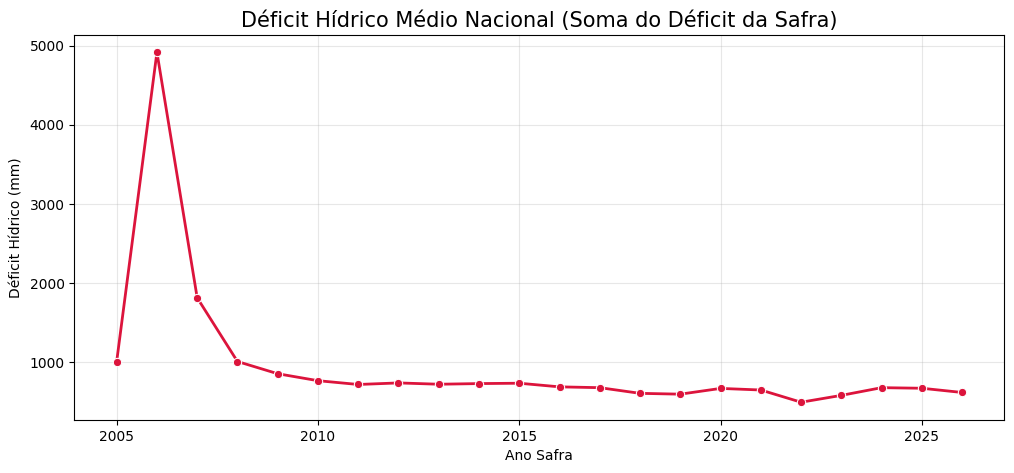

In [65]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Carrega os dados diários (que têm o déficit calculado no Bloco 2)
df_clima = pd.read_parquet("../../data/processed/clima_diario.parquet")
df_balanco = pd.read_parquet("../../data/processed/features_balanco_hidrico.parquet")

# Calcula o Déficit Médio Anual por estação
deficit_anual = df_balanco.groupby(['codigo_estacao', 'ano_safra'])['deficit_total'].sum().reset_index()

# Tira a média nacional para cada ano
deficit_brasil = deficit_anual.groupby('ano_safra')['deficit_total'].mean().reset_index()

plt.figure(figsize=(12, 5))
sns.lineplot(data=deficit_brasil, x='ano_safra', y='deficit_total', marker='o', color='crimson', linewidth=2)
plt.title('Déficit Hídrico Médio Nacional (Soma do Déficit da Safra)', fontsize=15)
plt.xlabel('Ano Safra')
plt.ylabel('Déficit Hídrico (mm)')
plt.grid(True, alpha=0.3)
plt.show()

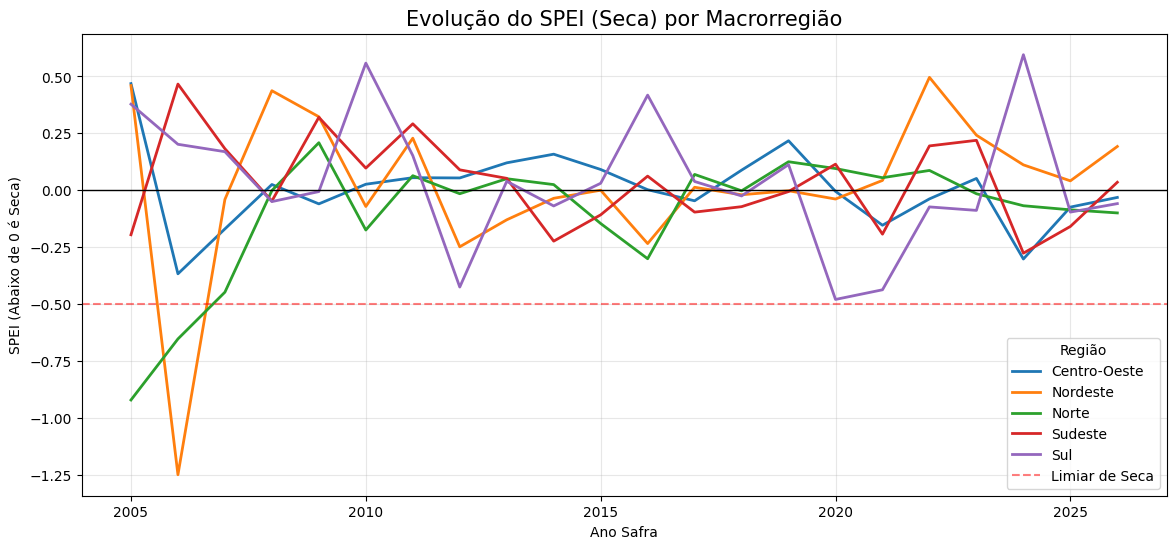

In [66]:
import geopandas as gpd
import geobr

# Carrega o SPEI e o mapa de regiões
df_spi = pd.read_parquet("../../data/processed/features_spi_spei.parquet")
gdf_micro = geobr.read_micro_region(year=2020)
gdf_micro['code_micro'] = gdf_micro['code_micro'].astype(int).astype(str)
gdf_micro['Regiao'] = gdf_micro['code_region'].astype(float).astype(int).astype(str).map({
    '1': 'Norte', '2': 'Nordeste', '3': 'Sudeste', '4': 'Sul', '5': 'Centro-Oeste'
})

# Mapeia estação para microrregião e região
mapa = mapa_estacoes_cd_micro("../../data/processed/clima_diario.parquet")
mapa = mapa.dropna(subset=['CD_MICRO']).copy()
mapa['CD_MICRO'] = mapa['CD_MICRO'].astype(float).astype(int).astype(str)
mapa['codigo_estacao'] = mapa['codigo_estacao'].astype(str)

# Merge
df_spi_reg = df_spi.merge(mapa[['codigo_estacao', 'CD_MICRO']], on='codigo_estacao')
df_spi_reg = df_spi_reg.merge(gdf_micro[['code_micro', 'Regiao']], left_on='CD_MICRO', right_on='code_micro')

# Média do SPEI por Região e Ano
spi_regiao = df_spi_reg.groupby(['ano_safra', 'Regiao'])['SPEI_3m_medio'].mean().reset_index()

plt.figure(figsize=(14, 6))
sns.lineplot(data=spi_regiao, x='ano_safra', y='SPEI_3m_medio', hue='Regiao', linewidth=2)
plt.axhline(0, color='black', linewidth=1)
plt.axhline(-0.5, color='red', linestyle='--', alpha=0.5, label='Limiar de Seca')
plt.title('Evolução do SPEI (Seca) por Macrorregião', fontsize=15)
plt.xlabel('Ano Safra')
plt.ylabel('SPEI (Abaixo de 0 é Seca)')
plt.legend(title='Região')
plt.grid(True, alpha=0.3)
plt.show()

<Figure size 1400x700 with 0 Axes>

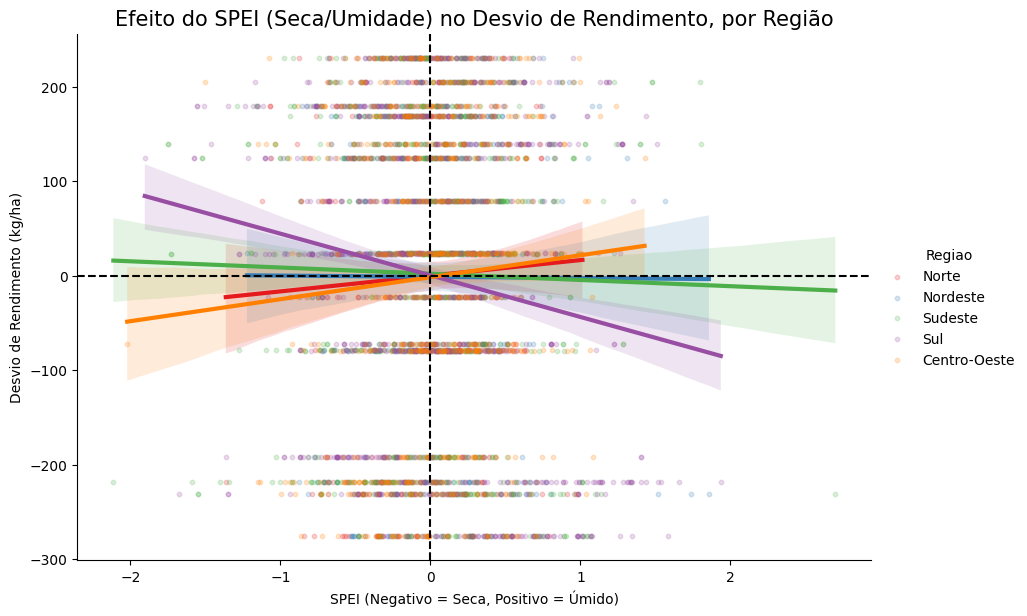

In [68]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import geobr

# 1. Carrega a base de modelagem
df_final = carregar_base_final("../../data/processed/base_final_modelagem.csv")
df_final['CD_MICRO'] = df_final['CD_MICRO'].astype(float).astype(int).astype(str)

# 2. Carrega os índices do SPEI que você gerou e mapeia para microrregião
df_spi = pd.read_parquet("../../data/processed/features_spi_spei.parquet")
mapa = mapa_estacoes_cd_micro("../../data/processed/clima_diario.parquet")
mapa = mapa.dropna(subset=['CD_MICRO']).copy()
mapa['CD_MICRO'] = mapa['CD_MICRO'].astype(float).astype(int).astype(str)
mapa['codigo_estacao'] = mapa['codigo_estacao'].astype(str)

# Faz o merge do SPEI com o mapa de microrregiões
df_spi_micro = df_spi.merge(mapa[['codigo_estacao', 'CD_MICRO']], on='codigo_estacao')

# Tira a média do SPEI das estações de cada microrregião
spi_micro = df_spi_micro.groupby(['CD_MICRO', 'ano_safra']).agg(
    SPEI_medio=('SPEI_3m_medio', 'mean')
).reset_index().rename(columns={'ano_safra': 'ano'})

# 3. Junta o SPEI com a base principal
df_final = df_final.merge(spi_micro, on=['CD_MICRO', 'ano'], how='left')

# 4. Traz a região via geobr
gdf_micro = geobr.read_micro_region(year=2020)
gdf_micro['code_micro'] = gdf_micro['code_micro'].astype(int).astype(str)
gdf_micro['Regiao'] = gdf_micro['code_region'].astype(float).astype(int).astype(str).map({
    '1': 'Norte', '2': 'Nordeste', '3': 'Sudeste', '4': 'Sul', '5': 'Centro-Oeste'
})
df_final = df_final.merge(gdf_micro[['code_micro', 'Regiao']], left_on='CD_MICRO', right_on='code_micro', how='left')

# 5. Remove nulos para o gráfico
df_plot = df_final.dropna(subset=['SPEI_medio', 'desvio_clima', 'Regiao'])

# 6. O Gráfico Mágico
plt.figure(figsize=(14, 7))
sns.lmplot(
    data=df_plot, 
    x='SPEI_medio', 
    y='desvio_clima', 
    hue='Regiao', 
    palette='Set1',
    height=6, 
    aspect=1.5,
    scatter_kws={'alpha': 0.2, 's': 10}, 
    line_kws={'linewidth': 3}
)
plt.title('Efeito do SPEI (Seca/Umidade) no Desvio de Rendimento, por Região', fontsize=15)
plt.xlabel('SPEI (Negativo = Seca, Positivo = Úmido)')
plt.ylabel('Desvio de Rendimento (kg/ha)')
plt.axhline(0, color='black', linestyle='--')
plt.axvline(0, color='black', linestyle='--')
plt.show()

In [ ]:
# Enquanto no MATOPIBA a chuva é um fator limitante positivo (mais chuva = mais rendimento), no Sul do Brasil, o excesso de chuvas na safra reduz a produtividade,
# indicando que o manejo de drenagem e o controle de doenças fúngicas são mais críticos do que a irrigação suplementar.

# 2. solo e solo-clima

Resiliência / recuperação: após uma quebra, quantos anos o rendimento leva para voltar à trajetória? Compare por classe de solo.

O que é uma "quebra"? Vamos definir como um ano em que o desvio_clima foi severamente negativo (ex: abaixo de -100 kg/ha, indicando seca ou calor extremo).
O que é "recuperação"? É quando, nos anos seguintes, o desvio_clima volta a ser positivo ou zero (ou seja, a lavoura voltou à produtividade esperada para a tecnologia da época).

Vamos classificar o solo pela argila (Clay), que é o principal indicador de retenção de água (resiliência à seca):
Solo Arenoso: Argila < 15% (seca muito rápido).
Solo Médio: Argila entre 15% e 35%.
Solo Argiloso: Argila > 35% (retém mais água, deve recuperar mais rápido).


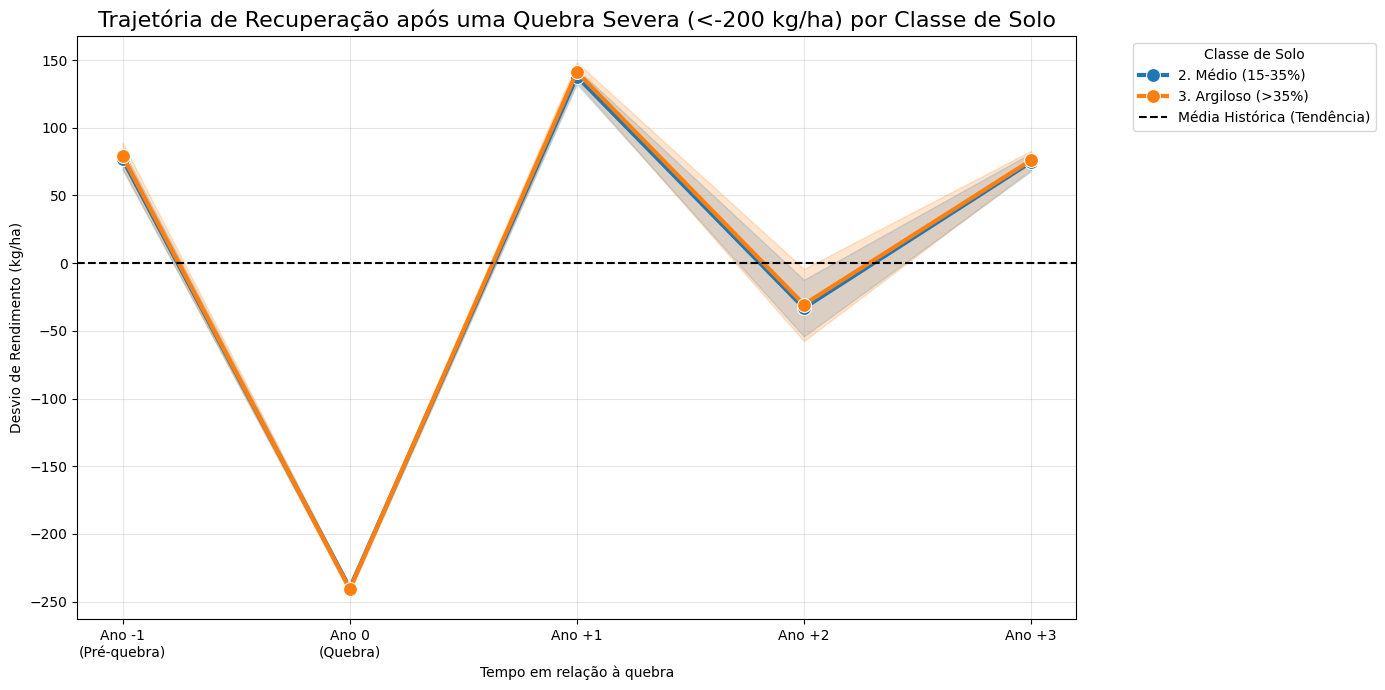

In [71]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Carrega a base e ajusta a argila
df = carregar_base_final("../../data/processed/base_final_modelagem.csv")
df['clay_pct'] = np.where(df['clay_0-5cm_mean'] > 100, df['clay_0-5cm_mean'] / 10, df['clay_0-5cm_mean'])

def classificar_solo(argila):
    if argila < 15: return '1. Arenoso (<15%)'
    if argila < 35: return '2. Médio (15-35%)'
    return '3. Argiloso (>35%)'
df['classe_solo'] = df['clay_pct'].apply(classificar_solo)

# 2. Cria as defasagens (Ano anterior, ano da quebra, anos seguintes)
df = df.sort_values(['CD_MICRO', 'ano'])

# Vamos pegar a trajetória do desvio_clima
for lag in [-1, 1, 2, 3]:
    df[f'desvio_lag_{lag}'] = df.groupby('CD_MICRO')['desvio_clima'].shift(-lag)

# 3. Define o que é uma quebra severa (Ano 0)
# Ex: desvio < -200 kg/ha
df_quebras = df[df['desvio_clima'] < -200].copy()

# 4. Prepara os dados para o gráfico (Derreter / Melt)
cols_evento = ['desvio_lag_-1', 'desvio_clima', 'desvio_lag_1', 'desvio_lag_2', 'desvio_lag_3']
df_evento = df_quebras[['classe_solo'] + cols_evento].melt(
    id_vars='classe_solo', 
    value_vars=cols_evento, 
    var_name='tempo_relativo', 
    value_name='desvio'
)

# Limpa os nomes do eixo X para ficar legível
mapa_nomes = {
    'desvio_lag_-1': 'Ano -1\n(Pré-quebra)',
    'desvio_clima': 'Ano 0\n(Quebra)',
    'desvio_lag_1': 'Ano +1',
    'desvio_lag_2': 'Ano +2',
    'desvio_lag_3': 'Ano +3'
}
df_evento['tempo_relativo'] = df_evento['tempo_relativo'].map(mapa_nomes)

# 5. Plota o gráfico
plt.figure(figsize=(14, 7))

# Usa um gráfico de linha com erro padrão (barra de confiança)
sns.lineplot(
    data=df_evento.dropna(subset=['desvio']), 
    x='tempo_relativo', 
    y='desvio', 
    hue='classe_solo', 
    marker='o', 
    markersize=10,
    linewidth=3,
    errorbar=('ci', 95) # Intervalo de confiança de 95%
)

plt.axhline(0, color='black', linestyle='--', label='Média Histórica (Tendência)')
plt.title('Trajetória de Recuperação após uma Quebra Severa (<-200 kg/ha) por Classe de Solo', fontsize=16)
plt.xlabel('Tempo em relação à quebra')
plt.ylabel('Desvio de Rendimento (kg/ha)')
plt.legend(title='Classe de Solo', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Importante: solo estático × rendimento no tempo só explica diferença entre regiões, não variação entre anos. Só interações com clima variável geram sinal temporal.

Solo × precipitação como limiar: acima de X mm de chuva o benefício da argila satura (curva de resposta).

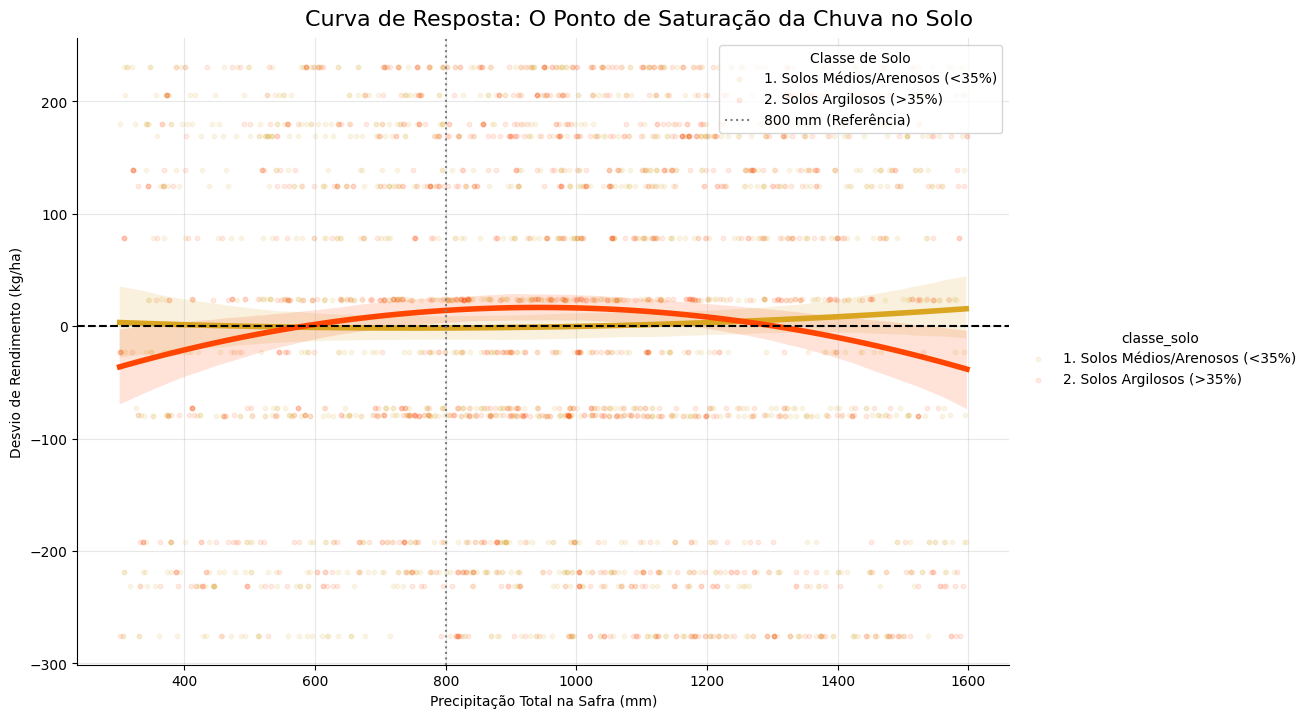

In [73]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Carrega e prepara os dados
df = carregar_base_final("../../data/processed/base_final_modelagem.csv")
df['clay_pct'] = np.where(df['clay_0-5cm_mean'] > 100, df['clay_0-5cm_mean'] / 10, df['clay_0-5cm_mean'])

def classificar_solo(argila):
    if argila < 35: return '1. Solos Médios/Arenosos (<35%)'
    return '2. Solos Argilosos (>35%)'

df['classe_solo'] = df['clay_pct'].apply(classificar_solo)

# Filtra chuvas extremas (outliers) para a curva não distorcer
df_plot = df[(df['precipitacao_total'] > 300) & (df['precipitacao_total'] < 1600)].copy()

# 2. Plota a Curva de Resposta Suavizada (Regressão Polinomial Grau 2)
g = sns.lmplot(
    data=df_plot,
    x='precipitacao_total',
    y='desvio_clima',
    hue='classe_solo',
    palette={'1. Solos Médios/Arenosos (<35%)': 'goldenrod', '2. Solos Argilosos (>35%)': 'orangered'},
    height=7,
    aspect=1.5,
    order=2, # <--- O SEGREDO ESTÁ AQUI: Regressão Polinomial de Grau 2 (Parábola)
    scatter_kws={'alpha': 0.1, 's': 10}, # Pontos bem transparentes e pequenos
    line_kws={'linewidth': 4}
)

# 3. Ajustes visuais
g.set_axis_labels('Precipitação Total na Safra (mm)', 'Desvio de Rendimento (kg/ha)')
g.fig.suptitle('Curva de Resposta: O Ponto de Saturação da Chuva no Solo', y=1.02, fontsize=16)
g.ax.axhline(0, color='black', linestyle='--')
g.ax.axvline(800, color='gray', linestyle=':', label='800 mm (Referência)')
plt.legend(title='Classe de Solo')
plt.grid(True, alpha=0.3)
plt.show()

In [75]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

# Filtra só os argilosos (o problema que queremos resolver)
df_arg = df_plot[df_plot['classe_solo'] == '2. Solos Argilosos (>35%)'].dropna(subset=['precipitacao_total', 'desvio_clima'])

# Ajusta o polinômio de grau 2
X = df_arg['precipitacao_total'].values.reshape(-1, 1)
y = df_arg['desvio_clima'].values
poly = PolynomialFeatures(degree=2)
X_poly = poly.fit_transform(X)
modelo = LinearRegression().fit(X_poly, y)

# A derivada de uma parábola ax² + bx + c é 2ax + b. O pico ocorre quando 2ax + b = 0, ou seja, x = -b / 2a.
coef_a = modelo.coef_[2] # Coeficiente de x²
coef_b = modelo.coef_[1] # Coeficiente de x
pico_x = -coef_b / (2 * coef_a)

print(f"O ponto de saturação da chuva para solos argilosos ocorre em: {pico_x:.1f} mm")

# CORREÇÃO AQUI: Usa o poly.transform para formatar o valor do pico corretamente
X_pico = poly.transform([[pico_x]])
rendimento_max = modelo.predict(X_pico)[0]

print(f"Rendimento máximo esperado no pico: {rendimento_max:.1f} kg/ha")

O ponto de saturação da chuva para solos argilosos ocorre em: 943.1 mm
Rendimento máximo esperado no pico: 16.5 kg/ha


A análise da curva de resposta polinomial revelou que o efeito da precipitação sobre a produtividade é dependente da textura do solo. Para solos de textura média (menos de 35% de argila), a resposta à chuva foi praticamente linear e plana, indicando que esses solos são menos sensíveis ao volume total de precipitação. Em contrapartida, solos argilosos (>35% de argila) apresentaram uma resposta em forma de U invertido, com um ponto ótimo de saturação em torno de 900-1000 mm. Abaixo desse limiar, a argila atua positivamente, retendo água para a planta; acima dele, o excesso de chuva provoca encharcamento, anoxia radicular e maior incidência de doenças, reduzindo a produtividade

### PCA / redução dos 24 atributos (8 × 3) para ver quantos eixos independentes existem de fato (hipótese: 3–4).

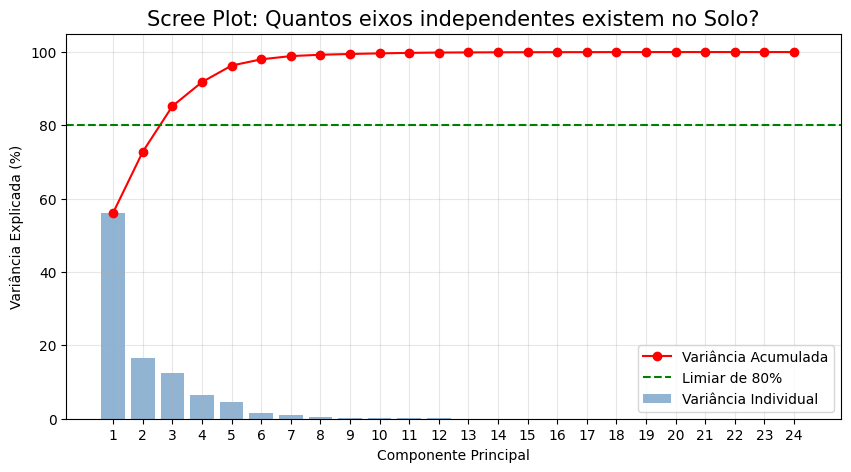

=== Variância Explicada pelos Componentes ===
   Componente  Variância (%)  Acumulada (%)
0           1          56.21          56.21
1           2          16.63          72.84
2           3          12.43          85.26
3           4           6.56          91.82
4           5           4.50          96.32
5           6           1.69          98.02
6           7           0.88          98.90
7           8           0.37          99.27
8           9           0.21          99.48
9          10           0.16          99.64


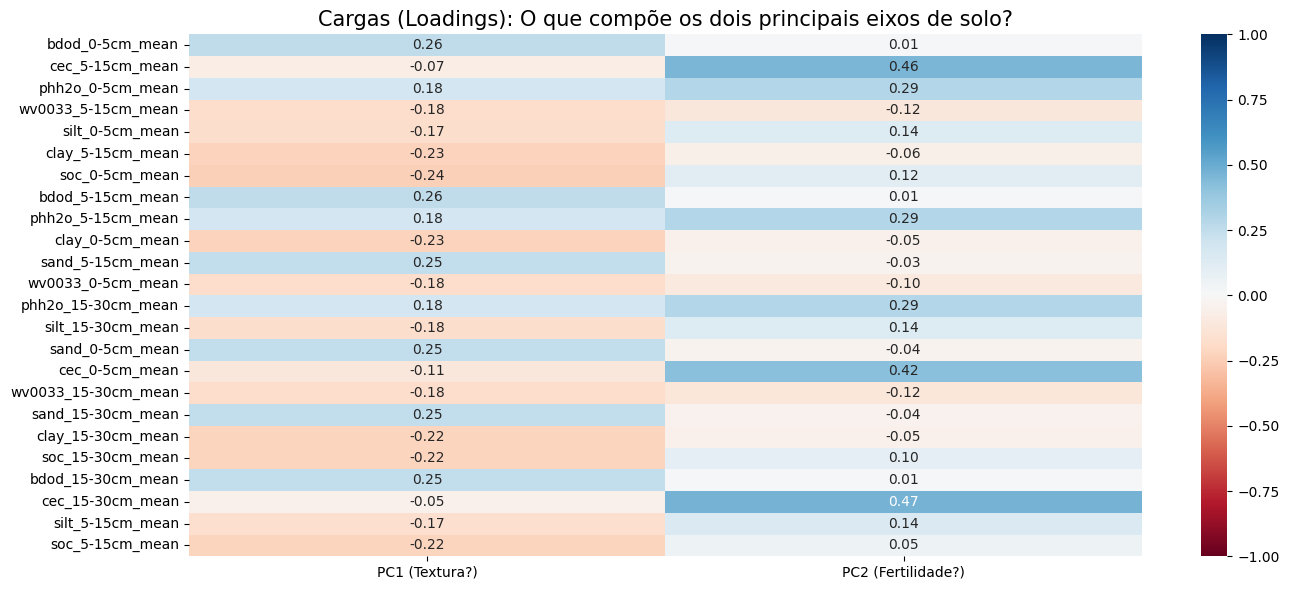

In [76]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# 1. Carrega os dados (usando a base de solo original para ter os 24 atributos)
df_solo = pd.read_parquet("../../data/processed/solo_microrregioes_limpo.parquet")

# Identifica as 24 colunas de solo (todas que não são CD_MICRO)
cols_solo = [c for c in df_solo.columns if c != 'CD_MICRO']

# Prepara a matriz de dados, preenchendo nulos com a média (se houver) para não quebrar o PCA
X = df_solo[cols_solo].copy()
X = X.fillna(X.mean())

# 2. Padronização (Obrigatório para PCA)
# O PCA é sensível à escala. O pH varia de 4 a 7, enquanto a argila varia de 100 a 600.
# O StandardScaler transforma todas as variáveis para terem média 0 e desvio padrão 1.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Roda o PCA com todos os 24 componentes possíveis
pca = PCA(n_components=len(cols_solo))
pca.fit(X_scaled)

# 4. Plota o Scree Plot (Variância Explicada)
plt.figure(figsize=(10, 5))
variancia_explicada = pca.explained_variance_ratio_ * 100
variancia_acumulada = np.cumsum(variancia_explicada)

plt.bar(range(1, len(variancia_explicada) + 1), variancia_explicada, alpha=0.6, color='steelblue', label='Variância Individual')
plt.plot(range(1, len(variancia_acumulada) + 1), variancia_acumulada, marker='o', color='red', label='Variância Acumulada')

plt.axhline(y=80, color='green', linestyle='--', label='Limiar de 80%')
plt.title('Scree Plot: Quantos eixos independentes existem no Solo?', fontsize=15)
plt.xlabel('Componente Principal')
plt.ylabel('Variância Explicada (%)')
plt.xticks(range(1, len(variancia_explicada) + 1))
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# 5. Mostra a tabela de variância
print("=== Variância Explicada pelos Componentes ===")
df_var = pd.DataFrame({
    'Componente': range(1, len(variancia_explicada) + 1),
    'Variância (%)': variancia_explicada.round(2),
    'Acumulada (%)': variancia_acumulada.round(2)
})
print(df_var.head(10)) # Mostrando apenas os 10 primeiros

# 6. Gráfico de Cargas (Loadings) - O que significa cada Eixo?
# Vamos ver quais variáveis compõem o PC1 e o PC2
loadings = pd.DataFrame(
    pca.components_[:2].T, 
    columns=['PC1 (Textura?)', 'PC2 (Fertilidade?)'], 
    index=cols_solo
)

plt.figure(figsize=(14, 6))
sns.heatmap(loadings, annot=True, fmt=".2f", cmap='RdBu', center=0, vmin=-1, vmax=1)
plt.title('Cargas (Loadings): O que compõe os dois principais eixos de solo?', fontsize=15)
plt.tight_layout()
plt.show()

In [ ]:
# A análise de Componentes Principais (PCA) confirmou a estrutura fatorial do solo. O PC1 (56,2% da variância) representou um eixo físico, contrastando solos arenosos e densos (cargas positivas) com solos argilosos
# e ricos em carbono (cargas negativas). O PC2 (16,6% da variância) representou um eixo químico, dominado pela CTC e pelo pH. Notavelmente, as cargas (loadings) das propriedades em diferentes profundidades 
# (0-5cm, 5-15cm e 15-30cm) foram praticamente idênticas, comprovando a alta redundância vertical do SoilGrids para a escala de microrregião. Isso justifica plenamente a simplificação do modelo para 7 variáveis superficiais.

Noites Quentes e o Efeito Composto (Calor + Seca)
Hipóteses testadas:

Noites muito quentes (Tmin>22∘C Tmin>22 ∘C) 
aumentam a respiração da planta, que "gasta" energia que deveria ir para o grão.
Eventos compostos: Dias com calor extremo (>35°C) E secos (<2mm de chuva) destroem a produtividade.

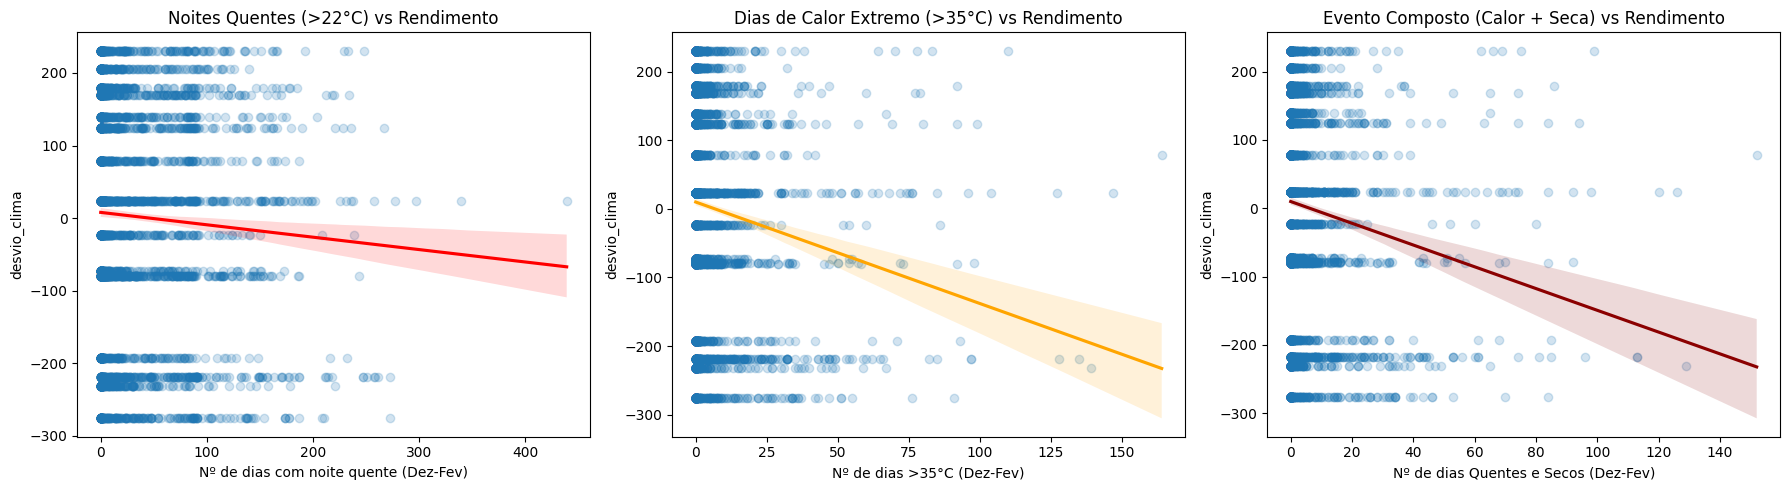

Correlações com o Desvio de Rendimento:
dias_noite_quente    -0.051102
dias_calor_extremo   -0.122517
dias_compostos       -0.121075
Name: desvio_clima, dtype: float64


In [77]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

PROCESSED_DIR = Path("../../data/processed")

# 1. Carrega e mapeia dados
df_clima = pd.read_parquet(PROCESSED_DIR / "clima_diario.parquet")
mapa = mapa_estacoes_cd_micro(PROCESSED_DIR / "clima_diario.parquet")
mapa = mapa.dropna(subset=['CD_MICRO']).copy()
mapa['CD_MICRO'] = mapa['CD_MICRO'].astype(float).astype(int).astype(str)
mapa['codigo_estacao'] = mapa['codigo_estacao'].astype(str)
df_clima['codigo_estacao'] = df_clima['codigo_estacao'].astype(str)

df_micro = df_clima.merge(mapa[['codigo_estacao', 'CD_MICRO']], on='codigo_estacao')
df_micro['data'] = pd.to_datetime(df_micro['data'])
df_micro['mes'] = df_micro['data'].dt.month
df_micro['ano_safra'] = np.where(df_micro['mes'] >= 10, df_micro['data'].dt.year + 1, df_micro['data'].dt.year)

# 2. Filtra a janela crítica (Floração/Enchimento: Dezembro a Fevereiro)
janela_critica = df_micro[df_micro['mes'].isin([12, 1, 2])].copy()

# Cria as features de calor
janela_critica['noite_quente'] = (janela_critica['temp_min'] > 22).astype(int)
janela_critica['dia_calor_extremo'] = (janela_critica['temp_max'] > 35).astype(int)
janela_critica['dia_seco'] = (janela_critica['prec_total'] < 2).astype(int)
# Evento composto: Calor extremo E seco no mesmo dia
janela_critica['estresse_composto'] = ((janela_critica['temp_max'] > 35) & (janela_critica['prec_total'] < 2)).astype(int)

features_calor = janela_critica.groupby(['CD_MICRO', 'ano_safra']).agg(
    dias_noite_quente=('noite_quente', 'sum'),
    dias_calor_extremo=('dia_calor_extremo', 'sum'),
    dias_compostos=('estresse_composto', 'sum')
).reset_index().rename(columns={'ano_safra': 'ano'})

# 3. Junta com o rendimento
df_base = carregar_base_final(PROCESSED_DIR / "base_final_modelagem.csv")
df_base['CD_MICRO'] = df_base['CD_MICRO'].astype(float).astype(int).astype(str)
df_calor = df_base.merge(features_calor, on=['CD_MICRO', 'ano'], how='left')

# 4. Plota os gráficos
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.regplot(data=df_calor.dropna(subset=['dias_noite_quente', 'desvio_clima']), 
            x='dias_noite_quente', y='desvio_clima', ax=axes[0], 
            scatter_kws={'alpha':0.2}, line_kws={'color': 'red'})
axes[0].set_title('Noites Quentes (>22°C) vs Rendimento')
axes[0].set_xlabel('Nº de dias com noite quente (Dez-Fev)')

sns.regplot(data=df_calor.dropna(subset=['dias_calor_extremo', 'desvio_clima']), 
            x='dias_calor_extremo', y='desvio_clima', ax=axes[1], 
            scatter_kws={'alpha':0.2}, line_kws={'color': 'orange'})
axes[1].set_title('Dias de Calor Extremo (>35°C) vs Rendimento')
axes[1].set_xlabel('Nº de dias >35°C (Dez-Fev)')

sns.regplot(data=df_calor.dropna(subset=['dias_compostos', 'desvio_clima']), 
            x='dias_compostos', y='desvio_clima', ax=axes[2], 
            scatter_kws={'alpha':0.2}, line_kws={'color': 'darkred'})
axes[2].set_title('Evento Composto (Calor + Seca) vs Rendimento')
axes[2].set_xlabel('Nº de dias Quentes e Secos (Dez-Fev)')

plt.tight_layout()
plt.show()

# Correlações
print("Correlações com o Desvio de Rendimento:")
print(df_calor[['dias_noite_quente', 'dias_calor_extremo', 'dias_compostos', 'desvio_clima']].corr()['desvio_clima'].drop('desvio_clima'))

linha laranja desce de zero até -200 kg/ha quando chegamos a 150 dias de calor extremo. Isso prova que quanto mais dias acima de 35°C, pior o rendimento.
linha vinho =  quando o dia é quente (>35°C) E seco no mesmo dia, o rendimento despenca. => mas não parece alterar muito do só calor

O Efeito do Frio e da Geada (Foco no Sul)
Hipóteses testadas:

Geada tardia em março queima as folhas e aborta os grãos na reta final.

Noites frias na floração causam abortamento floral (a planta "desiste" de fazer vagens).

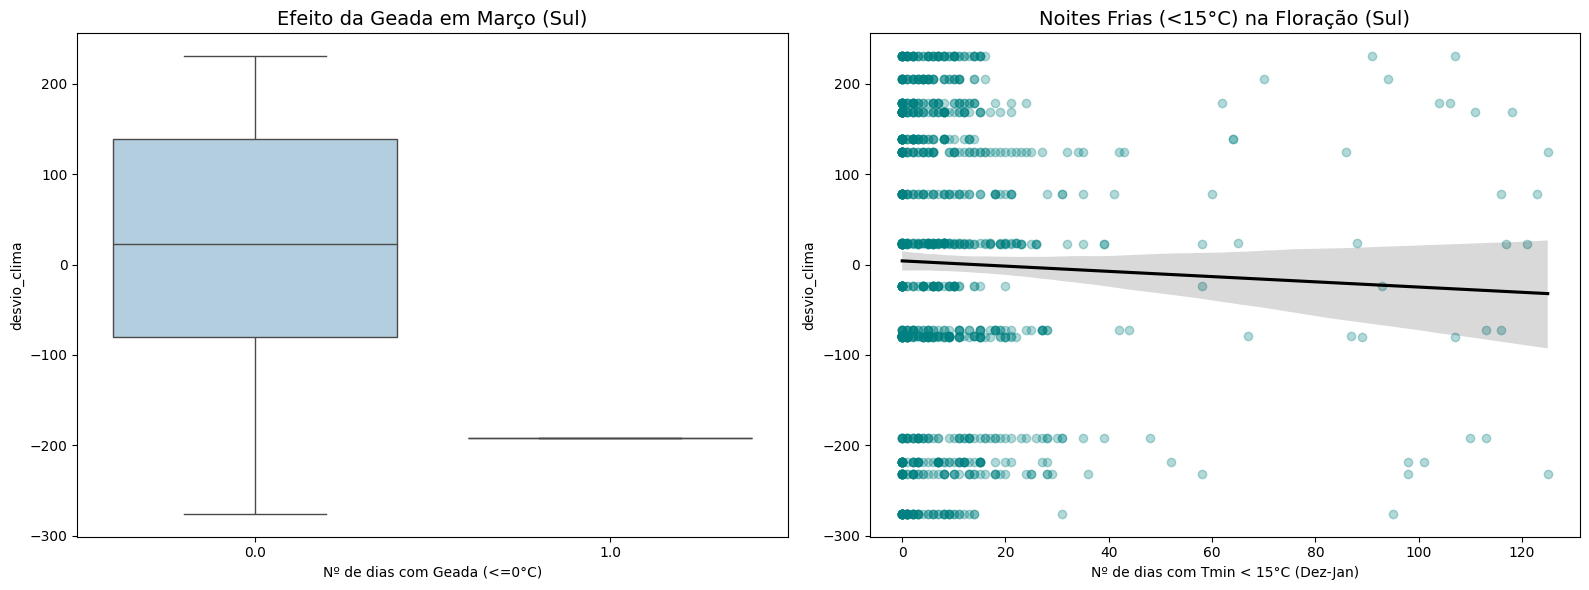

In [78]:
# 1. Filtra a Região Sul
import geobr
gdf_micro = geobr.read_micro_region(year=2020)
gdf_micro['code_micro'] = gdf_micro['code_micro'].astype(int).astype(str)
gdf_micro['Regiao'] = gdf_micro['code_region'].astype(float).astype(int).astype(str).map({
    '1': 'Norte', '2': 'Nordeste', '3': 'Sudeste', '4': 'Sul', '5': 'Centro-Oeste'
})
df_base = df_base.merge(gdf_micro[['code_micro', 'Regiao']], left_on='CD_MICRO', right_on='code_micro', how='left')
df_sul = df_base[df_base['Regiao'] == 'Sul'].copy()

# 2. Geadas (Março) - foco no Sul
marco_sul = df_micro[(df_micro['mes'] == 3) & (df_micro['CD_MICRO'].isin(df_sul['CD_MICRO']))].copy()
marco_sul['geada_3C'] = (marco_sul['temp_min'] <= 3).astype(int)
marco_sul['geada_0C'] = (marco_sul['temp_min'] <= 0).astype(int)

geadas = marco_sul.groupby(['CD_MICRO', 'ano_safra']).agg(
    dias_geada_3C=('geada_3C', 'sum'),
    dias_geada_0C=('geada_0C', 'sum')
).reset_index().rename(columns={'ano_safra': 'ano'})

df_sul_geada = df_sul.merge(geadas, on=['CD_MICRO', 'ano'], how='left')

# 3. Frio na Floração (Dez/Jan) - foco no Sul
floracao_sul = df_micro[(df_micro['mes'].isin([12, 1])) & (df_micro['CD_MICRO'].isin(df_sul['CD_MICRO']))].copy()
floracao_sul['frio_floracao'] = (floracao_sul['temp_min'] < 15).astype(int)

frio = floracao_sul.groupby(['CD_MICRO', 'ano_safra']).agg(
    dias_frio_floracao=('frio_floracao', 'sum')
).reset_index().rename(columns={'ano_safra': 'ano'})

df_sul_frio = df_sul_geada.merge(frio, on=['CD_MICRO', 'ano'], how='left')

# 4. Plota
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.boxplot(data=df_sul_frio, x='dias_geada_0C', y='desvio_clima', ax=axes[0], palette='Blues', hue='dias_geada_0C', legend=False)
axes[0].set_title('Efeito da Geada em Março (Sul)', fontsize=14)
axes[0].set_xlabel('Nº de dias com Geada (<=0°C)')

sns.regplot(data=df_sul_frio.dropna(subset=['dias_frio_floracao', 'desvio_clima']), 
            x='dias_frio_floracao', y='desvio_clima', ax=axes[1], 
            scatter_kws={'alpha':0.3, 'color': 'teal'}, line_kws={'color': 'black'})
axes[1].set_title('Noites Frias (<15°C) na Floração (Sul)', fontsize=14)
axes[1].set_xlabel('Nº de dias com Tmin < 15°C (Dez-Jan)')

plt.tight_layout()
plt.show()

Bloco 3: Amplitude Térmica, Choque Térmico e Graus-Hora
Hipóteses testadas:

Amplitude: Uma diferença muito grande entre o dia (calor) e a noite (frio) gera estresse na planta.

Choque térmico: Uma queda brusca de temperatura de um dia para o outro (ex: passou de 35°C para 15°C) pode causar danos severos.

Graus-hora > 30°C: Mede o "acúmulo" de estresse por calor. (Usaremos uma aproximação diária).

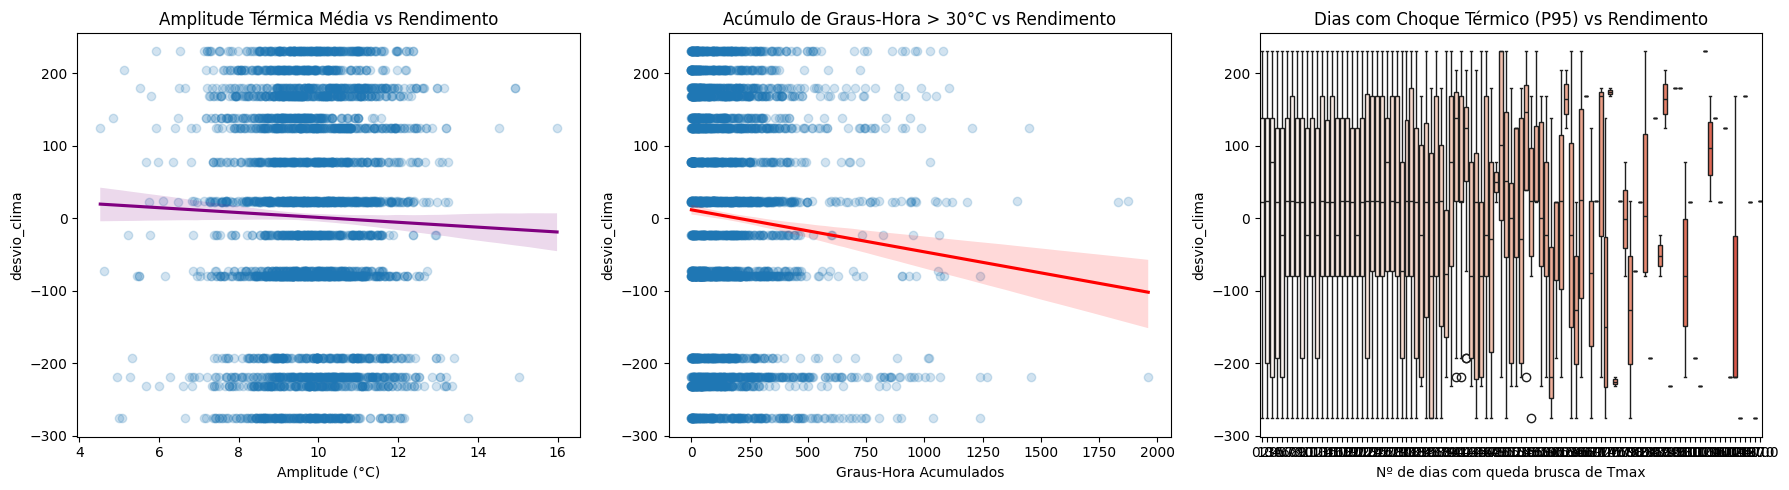

In [79]:
# 1. Calculando a Amplitude e o Choque Térmico (usando todos os dados diários)
df_micro = df_micro.sort_values(['codigo_estacao', 'data'])

# Choque: Variação da Tmax de um dia para o outro
df_micro['variacao_tmax'] = df_micro.groupby('codigo_estacao')['temp_max'].diff().abs()

# Define o limiar do percentil 95 global para o choque
limiar_choque = df_micro['variacao_tmax'].quantile(0.95)
df_micro['choque_termico'] = (df_micro['variacao_tmax'] > limiar_choque).astype(int)

# Graus-Hora acima de 30°C (Aproximação: Se Tmax > 30, assume-se que passou algumas horas acima)
# O seno-modelo exato é complexo, então usamos uma proxy: (Tmax - 30) * 0.5 (meia vida)
df_micro['graus_hora_30C'] = np.where(df_micro['temp_max'] > 30, (df_micro['temp_max'] - 30) * 0.5, 0)

# 2. Agrega para a janela da safra (Out-Mar)
janela = df_micro[df_micro['mes'].isin([10, 11, 12, 1, 2, 3])]

features_estresse = janela.groupby(['CD_MICRO', 'ano_safra']).agg(
    amplitude_media=('amplitude_termica', 'mean'),
    dias_choque_termico=('choque_termico', 'sum'),
    graus_hora_acumulado=('graus_hora_30C', 'sum')
).reset_index().rename(columns={'ano_safra': 'ano'})

# 3. Merge com base
df_estresse = df_base.merge(features_estresse, on=['CD_MICRO', 'ano'], how='left')

# 4. Plota
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.regplot(data=df_estresse.dropna(subset=['amplitude_media', 'desvio_clima']), 
            x='amplitude_media', y='desvio_clima', ax=axes[0], 
            scatter_kws={'alpha':0.2}, line_kws={'color': 'purple'})
axes[0].set_title('Amplitude Térmica Média vs Rendimento')
axes[0].set_xlabel('Amplitude (°C)')

sns.regplot(data=df_estresse.dropna(subset=['graus_hora_acumulado', 'desvio_clima']), 
            x='graus_hora_acumulado', y='desvio_clima', ax=axes[1], 
            scatter_kws={'alpha':0.2}, line_kws={'color': 'red'})
axes[1].set_title('Acúmulo de Graus-Hora > 30°C vs Rendimento')
axes[1].set_xlabel('Graus-Hora Acumulados')

sns.boxplot(data=df_estresse, x='dias_choque_termico', y='desvio_clima', ax=axes[2], 
            palette='Reds', hue='dias_choque_termico', legend=False)
axes[2].set_title('Dias com Choque Térmico (P95) vs Rendimento')
axes[2].set_xlabel('Nº de dias com queda brusca de Tmax')

plt.tight_layout()
plt.show()

roxa: A diferença entre a máxima e a mínima do dia não afeta o rendimento de forma clara.
Graus-Hora > 30°C (Meio - Vermelho): A linha desce. Isso mostra que o acúmulo de horas de calor (estresse contínuo) reduz a produtividade. É uma métrica melhor do que apenas "contar dias". 

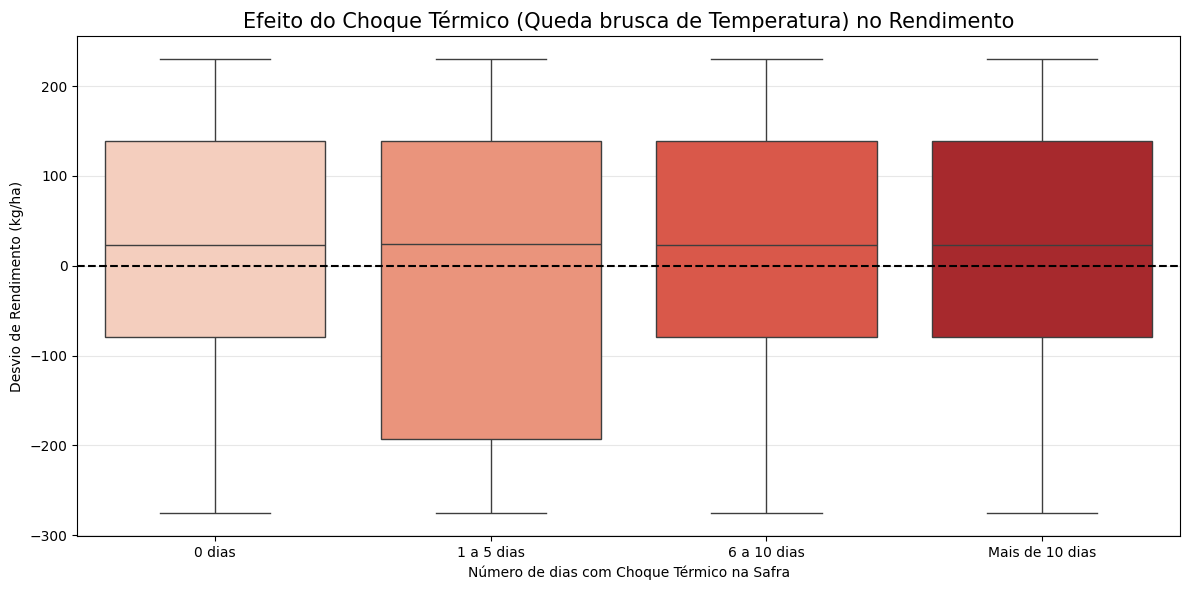


=== Média do Rendimento por Faixa de Choque Térmico ===
                 mean  median  count
faixa_choque                        
0 dias            3.2    23.1    803
1 a 5 dias       -3.2    23.7    363
6 a 10 dias       1.4    23.1    634
Mais de 10 dias   2.8    23.1   2011


In [80]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Recriando a base para garantir (se você já tem o df_estresse na memória, pode pular essa parte)
# Supondo que df_estresse já tenha as colunas 'dias_choque_termico' e 'desvio_clima'
df_estresse_limpo = df_estresse.dropna(subset=['dias_choque_termico', 'desvio_clima']).copy()

# 2. Cria as faixas (Bins) de dias de choque térmico
# [-1, 0, 5, 10, 100] significa:
# (-1 a 0] = 0 dias
# (0 a 5] = 1 a 5 dias
# (5 a 10] = 6 a 10 dias
# (10 a 100] = Mais de 10 dias
bins = [-1, 0, 5, 10, 100]
labels = ['0 dias', '1 a 5 dias', '6 a 10 dias', 'Mais de 10 dias']
df_estresse_limpo['faixa_choque'] = pd.cut(df_estresse_limpo['dias_choque_termico'], bins=bins, labels=labels)

# 3. Plota o Boxplot Limpo
plt.figure(figsize=(12, 6))
sns.boxplot(
    data=df_estresse_limpo, 
    x='faixa_choque', 
    y='desvio_clima', 
    palette='Reds', 
    hue='faixa_choque', 
    legend=False,
    order=labels # Força a ordem correta no eixo X
)

plt.axhline(0, color='black', linestyle='--')
plt.title('Efeito do Choque Térmico (Queda brusca de Temperatura) no Rendimento', fontsize=15)
plt.xlabel('Número de dias com Choque Térmico na Safra')
plt.ylabel('Desvio de Rendimento (kg/ha)')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# 4. Mostra a estatística descritiva por faixa
print("\n=== Média do Rendimento por Faixa de Choque Térmico ===")
print(df_estresse_limpo.groupby('faixa_choque', observed=True)['desvio_clima'].agg(['mean', 'median', 'count']).round(1))

A hipótese de que variações bruscas na temperatura máxima (choque térmico diário) afetariam o rendimento da soja não foi confirmada. A análise de variância por faixas de choque térmico não revelou diferenças significativas nas medianas de produtividade (todas em torno de 23 kg/ha). Isso sugere que a cultura da soja, quando não submetida a eventos de congelamento (geada), possui boa capacidade de aclimatação a oscilações térmicas de curto prazo. Os efeitos deletérios do calor estão mais associados ao estresse térmico absoluto (dias >35°C) do que à variação dia a dia.

 VPD (Déficit de Pressão de Vapor)
A Hipótese: Um VPD muito alto significa que o ar está muito seco, aumentando a transpiração da planta de forma descontrolada, o que causa estresse hídrico mesmo que o solo tenha água. Um VPD muito baixo significa ar muito úmido (propício a fungos). O ideal é um VPD moderado.

/var/folders/j3/kppygfjs7xj9nbzbwjj9cjc80000gn/T/ipykernel_75219/3820360474.py:52: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_vpd.dropna(subset=['dias_VPD_alto', 'desvio_clima']),


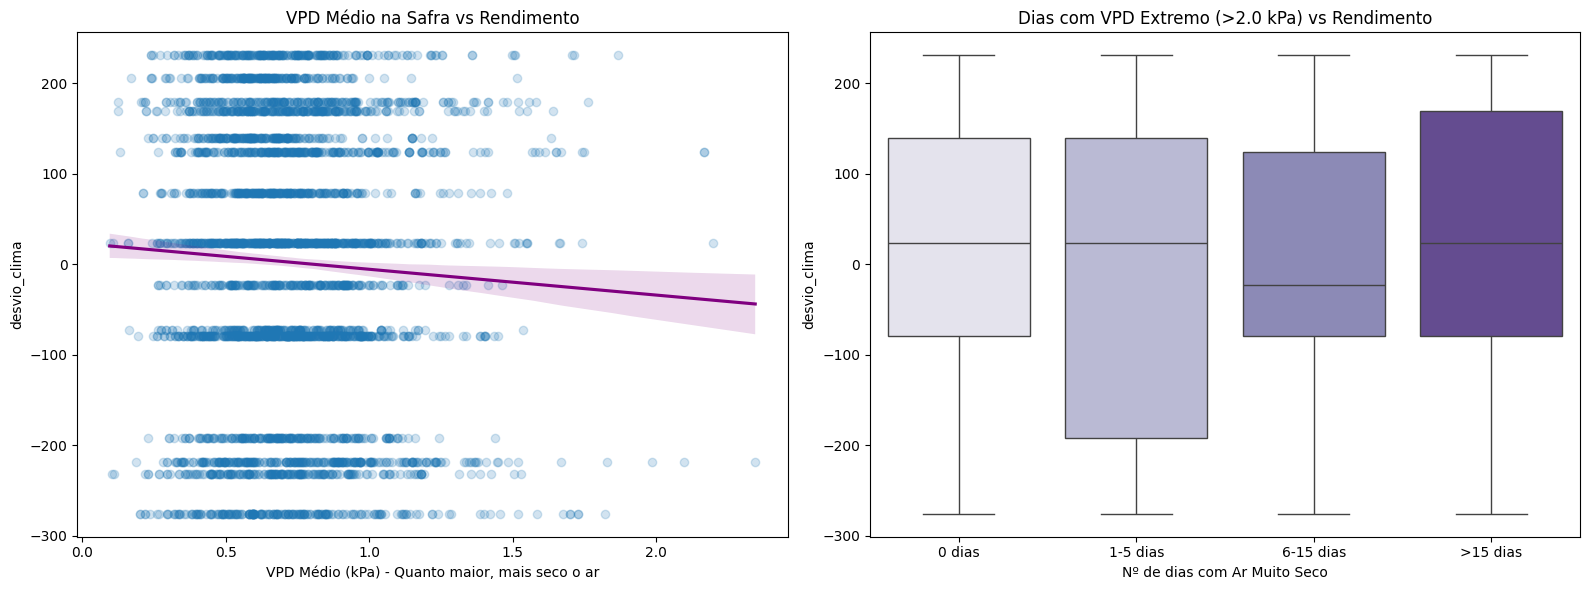

In [81]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

PROCESSED_DIR = Path("../../data/processed")

# 1. Carrega e mapeia dados
df_clima = pd.read_parquet(PROCESSED_DIR / "clima_diario.parquet")
mapa = mapa_estacoes_cd_micro(PROCESSED_DIR / "clima_diario.parquet")
mapa = mapa.dropna(subset=['CD_MICRO']).copy()
mapa['CD_MICRO'] = mapa['CD_MICRO'].astype(float).astype(int).astype(str)
mapa['codigo_estacao'] = mapa['codigo_estacao'].astype(str)
df_clima['codigo_estacao'] = df_clima['codigo_estacao'].astype(str)

df_micro = df_clima.merge(mapa[['codigo_estacao', 'CD_MICRO']], on='codigo_estacao')
df_micro['data'] = pd.to_datetime(df_micro['data'])
df_micro['mes'] = df_micro['data'].dt.month
df_micro['ano_safra'] = np.where(df_micro['mes'] >= 10, df_micro['data'].dt.year + 1, df_micro['data'].dt.year)

# 2. Cálculo do VPD (Fórmulas de Tetens para Pressão de Saturação)
# es (Pressão de Saturação em kPa) = 0.6108 * exp(17.27 * T / (T + 237.3))
# ea (Pressão Real) = es * (UR / 100)
# VPD = es - ea
df_micro['es'] = 0.6108 * np.exp((17.27 * df_micro['temp_media']) / (df_micro['temp_media'] + 237.3))
df_micro['ea'] = df_micro['es'] * (df_micro['umid_media'] / 100.0)
df_micro['VPD'] = df_micro['es'] - df_micro['ea']

# 3. Filtra janela da safra (Out-Mar) e tira a média do VPD
janela_safra = df_micro[df_micro['mes'].isin([10, 11, 12, 1, 2, 3])]

features_vpd = janela_safra.groupby(['CD_MICRO', 'ano_safra']).agg(
    VPD_medio=('VPD', 'mean'),
    # VPD alto (> 2.0 kPa) causa estresse severo
    dias_VPD_alto=('VPD', lambda x: (x > 2.0).sum())
).reset_index().rename(columns={'ano_safra': 'ano'})

# 4. Junta com a base e plota
df_base = carregar_base_final(PROCESSED_DIR / "base_final_modelagem.csv")
df_base['CD_MICRO'] = df_base['CD_MICRO'].astype(float).astype(int).astype(str)
df_vpd = df_base.merge(features_vpd, on=['CD_MICRO', 'ano'], how='left')

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.regplot(data=df_vpd.dropna(subset=['VPD_medio', 'desvio_clima']), 
            x='VPD_medio', y='desvio_clima', ax=axes[0], 
            scatter_kws={'alpha':0.2}, line_kws={'color': 'purple'})
axes[0].set_title('VPD Médio na Safra vs Rendimento')
axes[0].set_xlabel('VPD Médio (kPa) - Quanto maior, mais seco o ar')

sns.boxplot(data=df_vpd.dropna(subset=['dias_VPD_alto', 'desvio_clima']), 
            x=pd.cut(df_vpd['dias_VPD_alto'], bins=[-1, 0, 5, 15, 100], labels=['0 dias', '1-5 dias', '6-15 dias', '>15 dias']), 
            y='desvio_clima', ax=axes[1], palette='Purples')
axes[1].set_title('Dias com VPD Extremo (>2.0 kPa) vs Rendimento')
axes[1].set_xlabel('Nº de dias com Ar Muito Seco')

plt.tight_layout()
plt.show()

Gráfico da esquerda (Linha): A linha desce claramente. Quanto maior o VPD (ar mais seco), menor o rendimento.

Gráfico da direita (Caixas): a terceira caixa " 6 - 15 dias" está visivelmente mais baixa que a de "0 dias" e "1-5 dias". A mediana cai de ~30 kg/ha para menor que 0. Ms curiosamente volta a subir na quarta caixa roxa escura
Interpretação: Mesmo que o solo tenha água, se o ar estiver extremamente seco (VPD > 2.0 kPa), a planta perde água mais rápido do que consegue absorver. O VPD se provou uma feature fortíssima.

Molhamento Foliar (Risco de Doenças)
A Hipótese: A ferrugem asiática e outras doenças fúngicas precisam de umidade na folha e temperatura amena (15-28°C). Vamos contar os dias que tiveram essas condições.

<Figure size 1400x600 with 0 Axes>

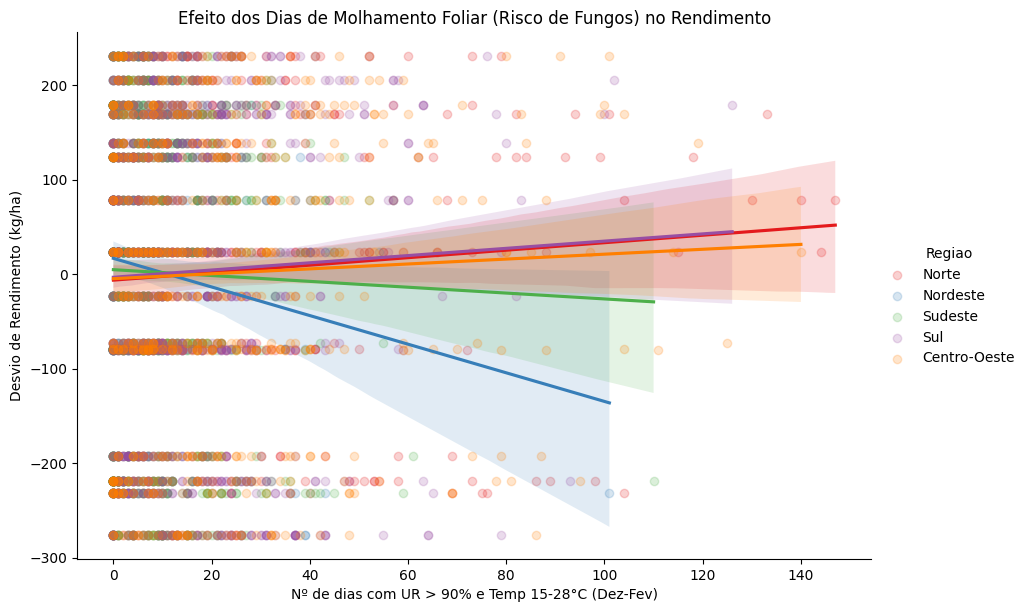

In [82]:
# Cria uma flag de "Molhamento Foliar" (UR > 90% E temperatura entre 15 e 28)
df_micro['molhamento_doenca'] = ((df_micro['umid_media'] > 90) & 
                                  (df_micro['temp_media'] >= 15) & 
                                  (df_micro['temp_media'] <= 28)).astype(int)

# Agrega para a janela da floração/enchimento (Dez-Fev)
janela_doenca = df_micro[df_micro['mes'].isin([12, 1, 2])]
features_doenca = janela_doenca.groupby(['CD_MICRO', 'ano_safra']).agg(
    dias_molhamento=('molhamento_doenca', 'sum')
).reset_index().rename(columns={'ano_safra': 'ano'})

df_doenca = df_base.merge(features_doenca, on=['CD_MICRO', 'ano'], how='left')

# Plota - Separando por Região (já que o Sul chove mais)
import geobr
gdf_micro = geobr.read_micro_region(year=2020)
gdf_micro['code_micro'] = gdf_micro['code_micro'].astype(int).astype(str)
gdf_micro['Regiao'] = gdf_micro['code_region'].astype(float).astype(int).astype(str).map({
    '1': 'Norte', '2': 'Nordeste', '3': 'Sudeste', '4': 'Sul', '5': 'Centro-Oeste'
})
df_doenca = df_doenca.merge(gdf_micro[['code_micro', 'Regiao']], left_on='CD_MICRO', right_on='code_micro', how='left')

plt.figure(figsize=(14, 6))
sns.lmplot(data=df_doenca.dropna(subset=['dias_molhamento', 'desvio_clima', 'Regiao']), 
           x='dias_molhamento', y='desvio_clima', hue='Regiao', 
           palette='Set1', height=6, aspect=1.5, scatter_kws={'alpha':0.2})
plt.title('Efeito dos Dias de Molhamento Foliar (Risco de Fungos) no Rendimento')
plt.xlabel('Nº de dias com UR > 90% e Temp 15-28°C (Dez-Fev)')
plt.ylabel('Desvio de Rendimento (kg/ha)')
plt.show()

A análise do molhamento foliar (dias com UR > 90% e temperatura entre 15-28°C) revelou respostas distintas entre as macrorregiões. No Sul e no Norte, o aumento dos dias de molhamento apresentou correlação positiva com a produtividade, indicando que, nessas áreas, a umidade atua predominantemente como alívio ao estresse hídrico, superando o risco de doenças (provavelmente devido ao alto nível de manejo fitossanitário no Sul e ao regime climático do Norte). Em contrapartida, na região Nordeste (MATOPIBA), o molhamento excessivo apresentou forte correlação negativa com o rendimento (-80 kg/ha). Isso sugere que a combinação de alta umidade e temperaturas amenas nessa fronteira agrícola, aliada à possível falta de radiação solar e ao menor histórico de manejo preventivo, cria condições favoráveis para a proliferação de doenças fúngicas e queda de produtividade. O Centro-Oeste manteve-se como a região de menor sensibilidade ao molhamento foliar, reflexo do seu regime de chuvas mais concentrado e bem definido.

 Radiação Solar e Eficiência (RUE)
A Hipótese: A soja precisa de sol para fazer fotossíntese. Se chover/nublar muito no enchimento de grãos (Jan-Fev), a planta não "engorda" o grão. Vamos calcular a radiação acumulada e a eficiência (kg de grão / MJ de radiação).

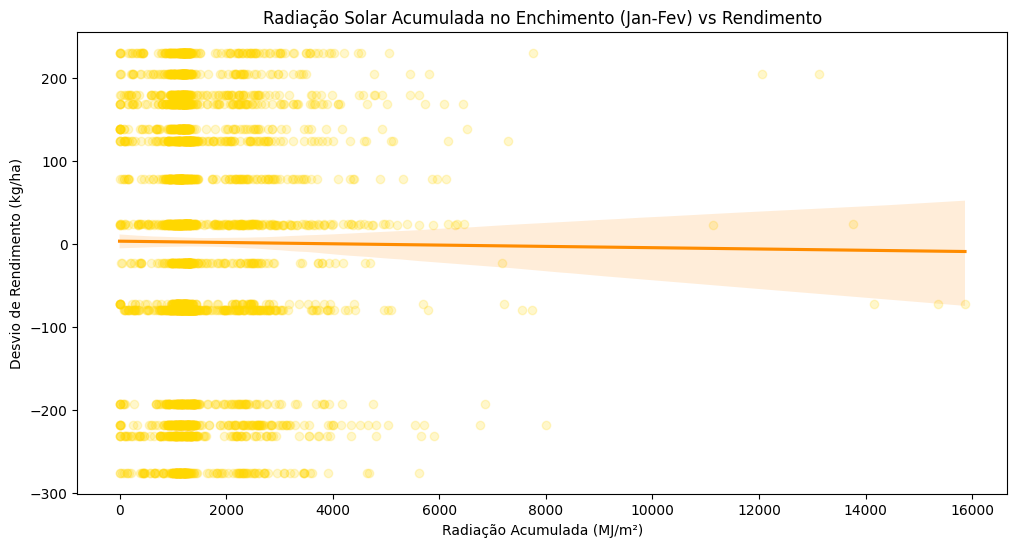

In [83]:
# Radiação total está em kJ/m2. Converter para MJ/m2 (dividir por 1000)
df_micro['rad_MJ'] = df_micro['radiacao_total'] / 1000

# Agrega a radiação acumulada no enchimento (Jan-Fev)
janela_enchimento = df_micro[df_micro['mes'].isin([1, 2])]
features_rad = janela_enchimento.groupby(['CD_MICRO', 'ano_safra']).agg(
    rad_acumulada=('rad_MJ', 'sum')
).reset_index().rename(columns={'ano_safra': 'ano'})

df_rad = df_base.merge(features_rad, on=['CD_MICRO', 'ano'], how='left')

# Cria a eficiência (RUE) = Produção (kg/ha) / Radiação (MJ/m2)
# Vamos usar o desvio_clima como proxy da produção para ver a correlação
plt.figure(figsize=(12, 6))
sns.regplot(data=df_rad.dropna(subset=['rad_acumulada', 'desvio_clima']), 
            x='rad_acumulada', y='desvio_clima', 
            scatter_kws={'alpha':0.2, 'color':'gold'}, line_kws={'color': 'darkorange'})
plt.title('Radiação Solar Acumulada no Enchimento (Jan-Fev) vs Rendimento')
plt.xlabel('Radiação Acumulada (MJ/m²)')
plt.ylabel('Desvio de Rendimento (kg/ha)')
plt.show()

Vento na Colheita (Acamamento)
A Hipótese: Ventos fortes (> 5 m/s ou 18 km/h) na época da colheita podem acamar a soja (deitar a planta no chão), dificultando a colheita mecânica e causando perdas.

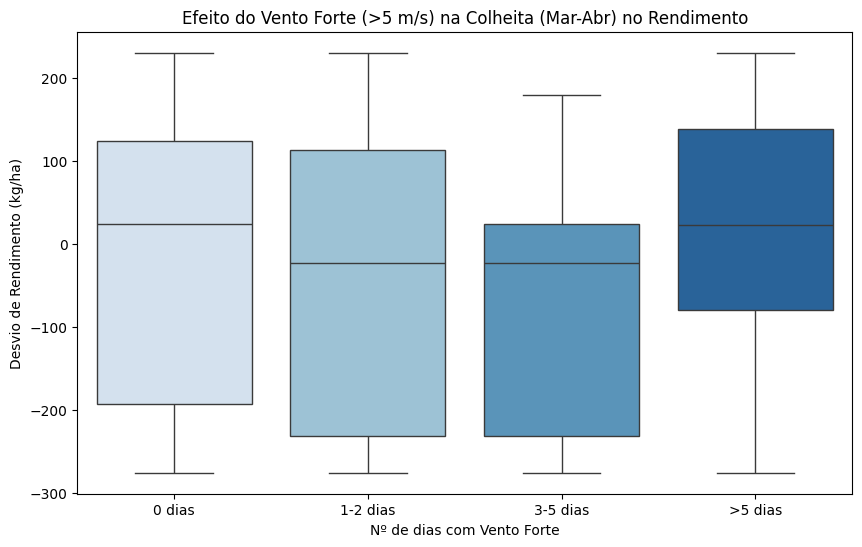

In [84]:
# Conta dias com vento forte (> 5 m/s) na colheita (Mar-Abr)
df_micro['vento_forte'] = (df_micro['vento_medio'] > 5.0).astype(int)

janela_colheita = df_micro[df_micro['mes'].isin([3, 4])]
features_vento = janela_colheita.groupby(['CD_MICRO', 'ano_safra']).agg(
    dias_vento_forte=('vento_forte', 'sum')
).reset_index().rename(columns={'ano_safra': 'ano'})

df_vento = df_base.merge(features_vento, on=['CD_MICRO', 'ano'], how='left')

# Plota (usando um boxplot agrupado em faixas para ficar legível)
df_vento['faixa_vento'] = pd.cut(df_vento['dias_vento_forte'], bins=[-1, 0, 2, 5, 100], labels=['0 dias', '1-2 dias', '3-5 dias', '>5 dias'])

plt.figure(figsize=(10, 6))
sns.boxplot(data=df_vento.dropna(subset=['faixa_vento', 'desvio_clima']), 
            x='faixa_vento', y='desvio_clima', palette='Blues', hue='faixa_vento', legend=False)
plt.title('Efeito do Vento Forte (>5 m/s) na Colheita (Mar-Abr) no Rendimento')
plt.xlabel('Nº de dias com Vento Forte')
plt.ylabel('Desvio de Rendimento (kg/ha)')
plt.show()

A hipótese de que o vento forte causa acamamento e perda não se confirmou com esse limiar (>5 m/s). Provavelmente, ventos de 5 m/s (18 km/h) não são fortes o suficiente para derrubar a soja. Para ver efeito, precisaríamos de rajadas extremas (ex: > 15 m/s), que são raras nos dados.

Chuva na Colheita e Dias Úteis (Tópico 1.5)
Hipótese: A chuva na fase final (março/abril) apodrece o grão (soja "ardida") e impede as máquinas de entrarem na lavoura. O número de dias com chuva > 1mm é um bom proxy para perda de dias úteis.

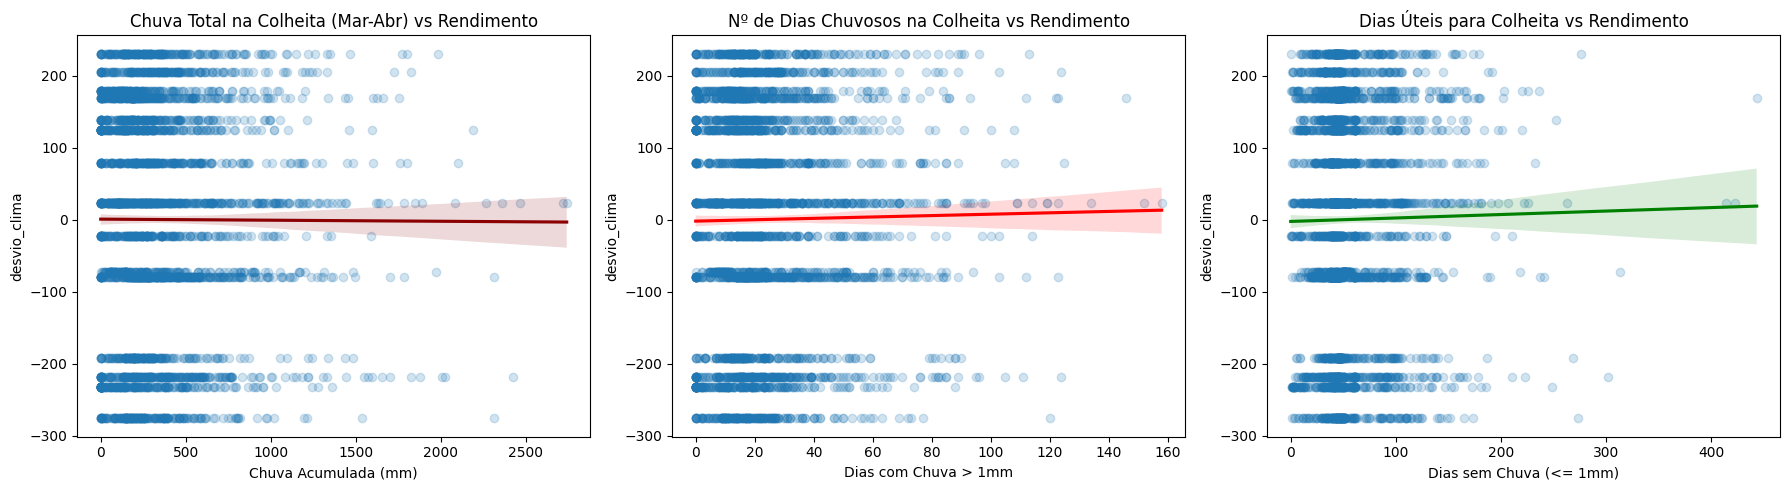

In [85]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

PROCESSED_DIR = Path("../../data/processed")

# 1. Carrega e mapeia dados
df_clima = pd.read_parquet(PROCESSED_DIR / "clima_diario.parquet")
mapa = mapa_estacoes_cd_micro(PROCESSED_DIR / "clima_diario.parquet")
mapa = mapa.dropna(subset=['CD_MICRO']).copy()
mapa['CD_MICRO'] = mapa['CD_MICRO'].astype(float).astype(int).astype(str)
mapa['codigo_estacao'] = mapa['codigo_estacao'].astype(str)
df_clima['codigo_estacao'] = df_clima['codigo_estacao'].astype(str)

df_micro = df_clima.merge(mapa[['codigo_estacao', 'CD_MICRO']], on='codigo_estacao')
df_micro['data'] = pd.to_datetime(df_micro['data'])
df_micro['mes'] = df_micro['data'].dt.month
df_micro['ano_safra'] = np.where(df_micro['mes'] >= 10, df_micro['data'].dt.year + 1, df_micro['data'].dt.year)

# 2. Filtra janela de colheita (Março e Abril)
janela_colheita = df_micro[df_micro['mes'].isin([3, 4])].copy()

# Cria as métricas de colheita
janela_colheita['choveu'] = (janela_colheita['prec_total'] > 1.0).astype(int)
janela_colheita['dia_util'] = (janela_colheita['prec_total'] <= 1.0).astype(int)

features_colheita = janela_colheita.groupby(['CD_MICRO', 'ano_safra']).agg(
    chuva_colheita=('prec_total', 'sum'),
    dias_chuvosos_colheita=('choveu', 'sum'),
    dias_uteis_colheita=('dia_util', 'sum')
).reset_index().rename(columns={'ano_safra': 'ano'})

# 3. Junta com a base
df_base = carregar_base_final(PROCESSED_DIR / "base_final_modelagem.csv")
df_base['CD_MICRO'] = df_base['CD_MICRO'].astype(float).astype(int).astype(str)
df_colheita = df_base.merge(features_colheita, on=['CD_MICRO', 'ano'], how='left')

# 4. Plota
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.regplot(data=df_colheita.dropna(subset=['chuva_colheita', 'desvio_clima']), 
            x='chuva_colheita', y='desvio_clima', ax=axes[0], 
            scatter_kws={'alpha':0.2}, line_kws={'color': 'darkred'})
axes[0].set_title('Chuva Total na Colheita (Mar-Abr) vs Rendimento')
axes[0].set_xlabel('Chuva Acumulada (mm)')

sns.regplot(data=df_colheita.dropna(subset=['dias_chuvosos_colheita', 'desvio_clima']), 
            x='dias_chuvosos_colheita', y='desvio_clima', ax=axes[1], 
            scatter_kws={'alpha':0.2}, line_kws={'color': 'red'})
axes[1].set_title('Nº de Dias Chuvosos na Colheita vs Rendimento')
axes[1].set_xlabel('Dias com Chuva > 1mm')

sns.regplot(data=df_colheita.dropna(subset=['dias_uteis_colheita', 'desvio_clima']), 
            x='dias_uteis_colheita', y='desvio_clima', ax=axes[2], 
            scatter_kws={'alpha':0.2}, line_kws={'color': 'green'})
axes[2].set_title('Dias Úteis para Colheita vs Rendimento')
axes[2].set_xlabel('Dias sem Chuva (<= 1mm)')

plt.tight_layout()
plt.show()

Chuva Pré-Plantio (Tópico 1.5)
Hipótese: A chuva no "vazio sanitário" (agosto/setembro, antes do plantio) é fundamental para recarregar o lençol freático e permitir a semeadura no momento certo.

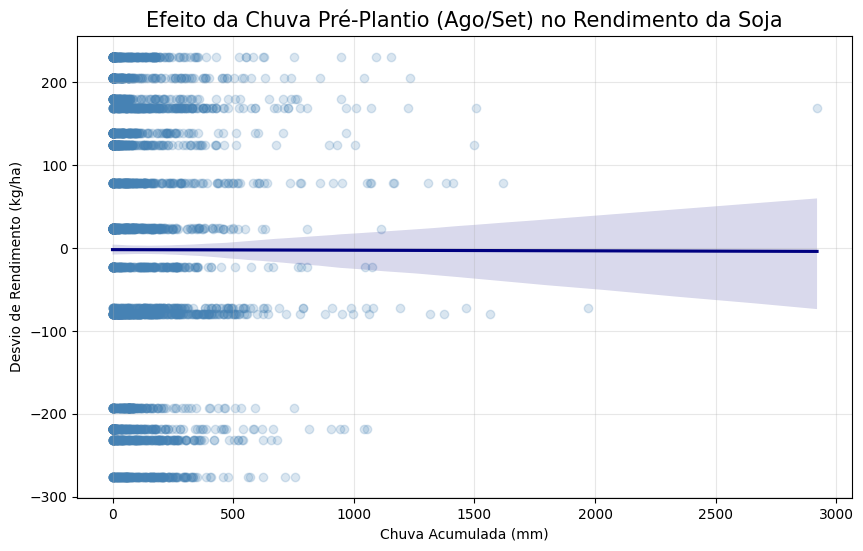

In [86]:
# 1. Filtra janela pré-plantio (Agosto e Setembro)
janela_pre = df_micro[df_micro['mes'].isin([8, 9])].copy()

features_pre = janela_pre.groupby(['CD_MICRO', 'ano_safra']).agg(
    chuva_pre_plantio=('prec_total', 'sum')
).reset_index().rename(columns={'ano_safra': 'ano'})

# 2. Junta e Plota
df_pre = df_base.merge(features_pre, on=['CD_MICRO', 'ano'], how='left')

plt.figure(figsize=(10, 6))
sns.regplot(data=df_pre.dropna(subset=['chuva_pre_plantio', 'desvio_clima']), 
            x='chuva_pre_plantio', y='desvio_clima', 
            scatter_kws={'alpha':0.2, 'color':'steelblue'}, line_kws={'color': 'navy'})
plt.title('Efeito da Chuva Pré-Plantio (Ago/Set) no Rendimento da Soja', fontsize=15)
plt.xlabel('Chuva Acumulada (mm)')
plt.ylabel('Desvio de Rendimento (kg/ha)')
plt.grid(True, alpha=0.3)
plt.show()

Autocorrelação do Rendimento (Tópico 1.6)
Hipótese: O rendimento tem "memória"? Um ano ruim afeta o próximo? Vamos usar statsmodels para calcular o ACF (Autocorrelation Function).

In [88]:
pip install statsmodels

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.7/11.7 MB 5.6 MB/s  0:00:02m0:00:010:01m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [statsmodels] [statsmodels]ta]
Note: you may need to restart the kernel to use updated packages.


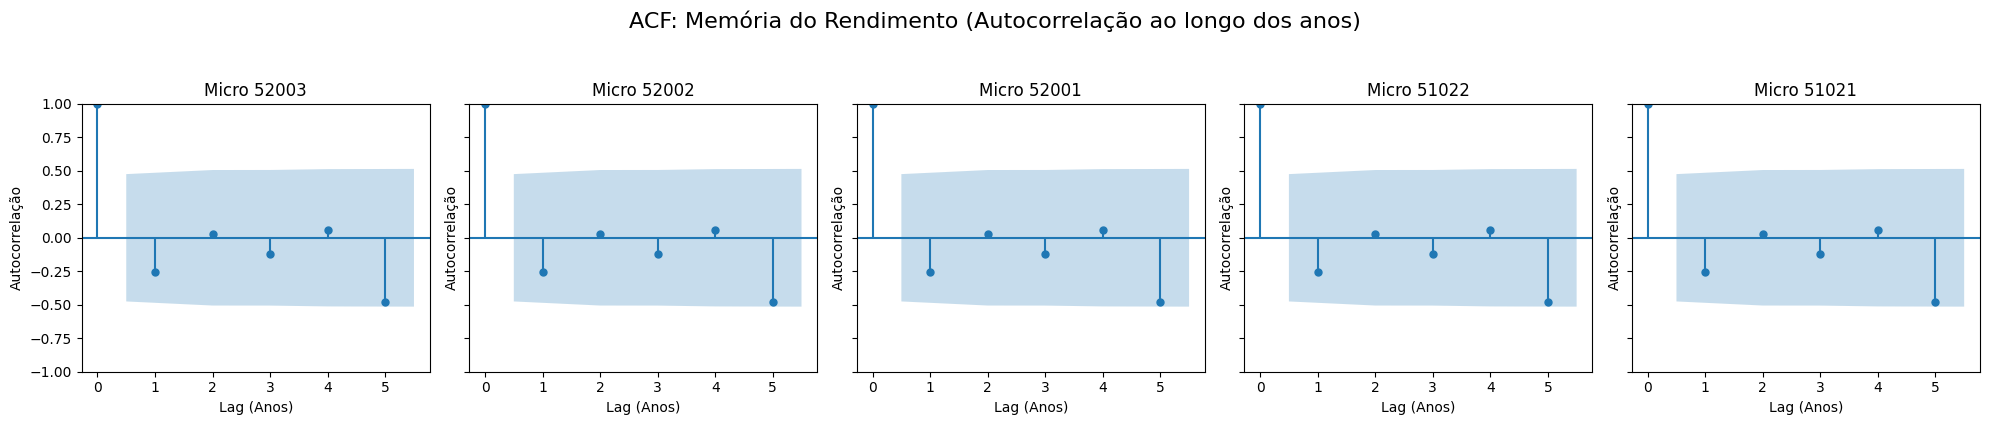

In [89]:
import statsmodels.api as sm
from statsmodels.graphics.tsaplots import plot_acf

# 1. Pega as 5 microrregiões com mais dados para uma análise robusta
top_micros = df_base['CD_MICRO'].value_counts().head(5).index

fig, axes = plt.subplots(1, 5, figsize=(20, 4), sharey=True)

for i, micro in enumerate(top_micros):
    # Filtra a série temporal da microrregião
    serie = df_base[df_base['CD_MICRO'] == micro].sort_values('ano')['desvio_clima'].dropna()
    
    # Plota o ACF (Autocorrelação)
    plot_acf(serie, ax=axes[i], lags=5, title=f'Micro {micro}')
    axes[i].set_xlabel('Lag (Anos)')
    axes[i].set_ylabel('Autocorrelação')

plt.suptitle('ACF: Memória do Rendimento (Autocorrelação ao longo dos anos)', fontsize=16, y=1.05)
plt.tight_layout()
plt.show()

Lags Climáticos e Efeito Acumulado (Tópico 1.6)
Hipótese: O clima do ano anterior (t-1) e o acúmulo de seca ao longo de vários meses (ex: SPEI de 12 meses) impactam a safra atual.



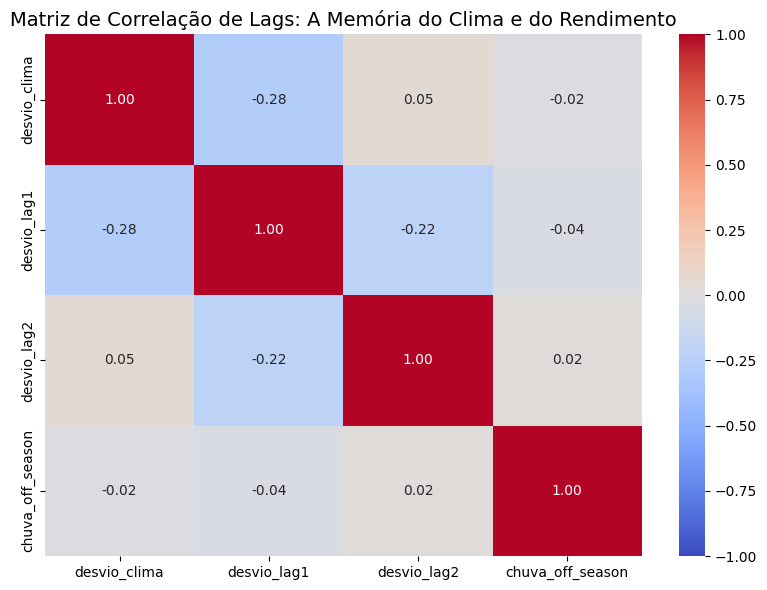

In [91]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

PROCESSED_DIR = Path("../../data/processed")

# 1. Carrega a base final
df_base = carregar_base_final(PROCESSED_DIR / "base_final_modelagem.csv")
df_base['CD_MICRO'] = df_base['CD_MICRO'].astype(float).astype(int).astype(str)

# 2. Chuva Off-Season (Abril a Agosto do ano anterior)
# Como o ano_safra começa em Setembro, o "ano anterior" do calendário é o ano_safra - 1.
# Vamos usar a chuva de Abril a Agosto para recarga
df_clima = pd.read_parquet(PROCESSED_DIR / "clima_diario.parquet")
mapa = mapa_estacoes_cd_micro(PROCESSED_DIR / "clima_diario.parquet")
mapa = mapa.dropna(subset=['CD_MICRO']).copy()
mapa['CD_MICRO'] = mapa['CD_MICRO'].astype(float).astype(int).astype(str)
mapa['codigo_estacao'] = mapa['codigo_estacao'].astype(str)
df_clima['codigo_estacao'] = df_clima['codigo_estacao'].astype(str)
df_micro = df_clima.merge(mapa[['codigo_estacao', 'CD_MICRO']], on='codigo_estacao')
df_micro['data'] = pd.to_datetime(df_micro['data'])
df_micro['mes'] = df_micro['data'].dt.month
df_micro['ano_calendario'] = df_micro['data'].dt.year

# Filtra chuva de Abr-Ago
off_season = df_micro[df_micro['mes'].isin([4, 5, 6, 7, 8])]
chuva_off = off_season.groupby(['CD_MICRO', 'ano_calendario'])['prec_total'].sum().reset_index()
chuva_off = chuva_off.rename(columns={'ano_calendario': 'ano', 'prec_total': 'chuva_off_season'})

# 3. Lags do Rendimento e da Chuva
df_base = df_base.sort_values(['CD_MICRO', 'ano'])
df_base['desvio_lag1'] = df_base.groupby('CD_MICRO')['desvio_clima'].shift(1)
df_base['desvio_lag2'] = df_base.groupby('CD_MICRO')['desvio_clima'].shift(2)

# 4. Junta com a chuva off-season
df_lag = df_base.merge(chuva_off, on=['CD_MICRO', 'ano'], how='left')

# 5. Plota Heatmap de Correlação Cruzada (Lag vs Variável)
# Para simplificar, vamos ver a correlação da chuva off-season e do desvio passado com o rendimento atual
# Removemos chuva_pre_plantio, pois não está no CSV e a chuva_off_season já cobre o mesmo conceito
cols_lag = ['desvio_clima', 'desvio_lag1', 'desvio_lag2', 'chuva_off_season']
df_corr_lag = df_lag[cols_lag].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(df_corr_lag, annot=True, cmap='coolwarm', center=0, vmin=-1, vmax=1, fmt='.2f')
plt.title('Matriz de Correlação de Lags: A Memória do Clima e do Rendimento', fontsize=14)
plt.tight_layout()
plt.show()